# Marketing Mix Modelling from First Principles
## A worked textbook with synthetic data, PyMC-Marketing and Google Meridian

This notebook teaches Bayesian Marketing Mix Modelling (MMM) from the ground up. It assumes you can read Python and remember a little high-school statistics (averages, a regression line). It does **not** assume you have ever done Bayesian statistics. Every concept is introduced in plain language first, then in maths, then in code.

**What we will do**

1. Learn what an MMM is and which question it answers (Part I).
2. Learn the Bayesian ideas the models rest on: prior, likelihood, posterior, MCMC, and how to tell whether a fit can be trusted (Part II).
3. Learn the building blocks of an MMM: carry-over (adstock), diminishing returns (saturation), baseline, seasonality and controls (Part III).
4. Manufacture a realistic, deliberately difficult dataset with PyMC-Marketing's data-generation workflow, so that we **know the true answer** (Part IV).
5. Explore the data the way an analyst would, without peeking at the truth (Part V).
6. Build, check and calibrate an MMM in **PyMC-Marketing** (Part VI).
7. Manufacture a second, **geo-level** dataset in Meridian's own model form (20 regions), then build, check and calibrate an MMM in **Google Meridian** on it, and measure what regional data adds (Part VII).
8. Compare all models against the truth of their own dataset (Part VIII).
9. Turn the models into a budget recommendation and grade that recommendation against the truth (Part IX).
10. Summarise the practices that carry over to real projects, with a glossary (Part X).

**How to read it.** Run the cells top to bottom. The whole notebook takes roughly 20 minutes on a modern multi-core CPU; most of that is four PyMC fits (about 1.5 minutes each) and two geo-level Meridian fits (about 4 minutes each). Text cells marked **Reading the output** interpret the numbers produced by the cell above. Because the random seeds are fixed, your numbers should match the ones quoted, up to small differences between machines.

**A word on honesty.** Synthetic data makes a model look better than it will on real data, because the model family we fit is the one that generated the data. Each library is given a dataset in its own functional form (a national series for PyMC-Marketing, regional data for Meridian), so the notebook shows how each behaves in its intended setting; it is not a contest between them. We counteract that by building in real-world problems (listed in Part IV) and by showing every result, including the ones where the models fail.

## 0. Setup

### 0.1 Software used

| Library | Version | Role |
|---|---|---|
| `pymc-marketing` | 0.19.4 | MMM toolkit from PyMC Labs; also our data generator |
| `pymc` | 5.28.5 | The probabilistic programming engine underneath PyMC-Marketing |
| `google-meridian` | 2.1.0 | Google's open-source MMM library (JAX backend) |
| `arviz` | 0.19.0 | Diagnostics and summaries for Bayesian models |
| `mlflow` | 3.16.1 | Experiment tracking (parameters, metrics, seeds for every fit) |

**Why PyMC-Marketing 0.19 and not 1.x?** At the time of writing, PyMC-Marketing 1.x requires ArviZ 1.x while Meridian 2.x requires ArviZ below 1.0, so the newest releases of the two libraries cannot be installed in the same Python environment. One notebook means one environment, so we use the newest pair that is officially compatible. We use the class `pymc_marketing.mmm.multidimensional.MMM`, which is the class that became the default `MMM` in 1.x, so the code here carries over with small changes.

### 0.2 Reproducing the environment

PyMC compiles its models to C, so it needs a C++ compiler. On Windows the simplest route is a conda environment that supplies one:

```bash
conda create -n mmm-pymc-meridian -c conda-forge python=3.12 m2w64-toolchain mkl mkl-service libpython pip
conda activate mmm-pymc-meridian
pip install -r requirements.txt      # exact pinned versions, shipped next to this notebook
```

Then select the `mmm-pymc-meridian` kernel for this notebook.

In [1]:
# --- Standard library ---------------------------------------------------------
import os
import sys
import json
import time
import hashlib
import logging
import platform
import warnings
from pathlib import Path

# PyMC needs the C++ compiler that lives inside the conda environment. If the notebook
# kernel was started without activating the environment, add its folders to PATH ourselves.
for sub in ("Library/mingw-w64/bin", "Library/usr/bin", "Library/bin", "Scripts"):
    folder = Path(sys.prefix) / sub
    if folder.exists() and str(folder) not in os.environ["PATH"]:
        os.environ["PATH"] = f"{folder}{os.pathsep}{os.environ['PATH']}"

# Quieten library chatter so the notebook output stays readable.
# (These must be set before the libraries are imported.)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")

# --- Scientific stack ---------------------------------------------------------
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan

# --- Bayesian stack -----------------------------------------------------------
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from pymc import do
from pymc_extras.prior import Prior

import pymc_marketing
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation, LinearTrend
from pymc_marketing.mmm.additive_effect import LinearTrendEffect
from pymc_marketing.mmm.multidimensional import (
    MMM,
    MultiDimensionalBudgetOptimizerWrapper,
)

import mlflow

for noisy in ["pymc", "pytensor", "absl", "jax", "mlflow", "alembic", "pymc_marketing"]:
    logging.getLogger(noisy).setLevel(logging.ERROR)

# One master seed for the whole notebook. Every random step derives from it.
SEED: int = 20261003

print(f"Python          {platform.python_version()}  ({platform.system()} {platform.machine()})")
print(f"pymc-marketing  {pymc_marketing.__version__}")
print(f"pymc            {pm.__version__}")
print(f"arviz           {az.__version__}")
print(f"mlflow          {mlflow.__version__}")
print(f"CPU cores       {os.cpu_count()}")

Python          3.12.14  (Windows AMD64)
pymc-marketing  0.19.4
pymc            5.28.5
arviz           0.19.0
mlflow          3.16.1
CPU cores       28


In [2]:
# --- Plot style -----------------------------------------------------------------
# One visual system for the whole notebook: thin marks, quiet grid, and a fixed
# colour per entity so that a channel (or a library) is the same colour everywhere.
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

CHANNELS: list[str] = ["tv", "search", "social", "display", "video"]
CHANNEL_COLOR: dict[str, str] = {
    "tv": "#2a78d6",       # blue
    "search": "#eb6834",   # orange
    "social": "#1baf7a",   # aqua
    "display": "#eda100",  # yellow
    "video": "#e87ba4",    # magenta
}
PYMC_COLOR, MERIDIAN_COLOR = "#4a3aa7", "#008300"   # violet, green
BLUE, ORANGE, BLUE_LIGHT = "#2a78d6", "#eb6834", "#9ec5f4"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (10, 4),
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
    "font.size": 10,
})


def thousands(ax: plt.Axes, axis: str = "y") -> None:
    """Format an axis in thousands of dollars ($k) so tick labels stay short."""
    fmt = mpl.ticker.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}k")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

### 0.3 Experiment tracking

Every model we fit is logged to a local MLflow store (`mlflow.db`, a small SQLite file next to the notebook): the settings, the random seed, a fingerprint of the data, the software versions and the resulting metrics. This costs a few lines and means that, weeks later, you can still answer "which settings produced that number?". To browse the runs afterwards, run `mlflow ui --backend-store-uri sqlite:///mlflow.db` in a terminal.

In [3]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("mmm-textbook")

ENVIRONMENT: dict[str, str] = {
    "python": platform.python_version(),
    "platform": f"{platform.system()} {platform.release()} {platform.machine()}",
    "processor": platform.processor(),
    "cpu_count": str(os.cpu_count()),
    "pymc_marketing": pymc_marketing.__version__,
    "pymc": pm.__version__,
    "arviz": az.__version__,
}


def log_run(name: str, library: str, params: dict, metrics: dict, data_hash: str) -> None:
    """Record one model fit in MLflow: settings, seed, data fingerprint, metrics."""
    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"library": library, "data_sha256": data_hash, "git_commit": "not-a-git-repo"})
        mlflow.log_params({**params, "seed": SEED})
        mlflow.log_dict(ENVIRONMENT, "environment.json")
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})

---
# Part I. What is a Marketing Mix Model?

## 1.1 The business question

A company spends money on several marketing channels: television, paid search, social media, and so on. At the end of the year the people who hold the budget ask three questions.

1. **How much of our sales did each channel cause?** (attribution, also called *contribution*)
2. **What did we get back per dollar?** (return on ad spend, *ROAS*, or *ROI*)
3. **How should we split next year's budget?** (optimisation)

A **Marketing Mix Model** answers these with a statistical model of sales over time. The data is a table with one row per time period (usually a week) and columns for sales, spend per channel, and other things that move sales such as price, holidays and promotions. The model explains each week's sales as a sum of parts:

$$
\text{sales}_t \;=\; \underbrace{\text{baseline}_t}_{\text{what you would sell with no advertising}} \;+\; \underbrace{\sum_{m} \text{effect of channel } m \text{ in week } t}_{\text{media contributions}} \;+\; \underbrace{\text{noise}_t}_{\text{everything unexplained}}
$$

Once the model has estimated each part, the three questions become arithmetic: the contribution of TV is the sum of its weekly effects; its ROAS is that sum divided by what was spent on TV; and the best budget is the split that makes the total media effect as large as possible.

## 1.2 The key word is *incremental*

The quantity we want is **incremental** sales: sales that happened *because of* the advertising and would not have happened otherwise. This is a *causal* question, and it is much harder than a descriptive one.

Here is why. Suppose a retailer raises its search-ads budget every December. Sales also rise every December, because of Christmas. A naive analysis sees spend and sales rising together and concludes that search ads are very effective. But much of that rise would have happened anyway. Spend and sales moved together because a third thing, seasonal demand, pushed both. This third thing is called a **confounder**, and the resulting error is **confounding bias**. We build exactly this trap into our data and watch a model fall into it in Part VI.

An MMM tries to separate these influences statistically by including the confounders (seasonality, price, demand) in the model. It only works if the important ones are included and if there is enough independent variation in spend. An MMM built on observational data is never as trustworthy as a randomised experiment, which is why modern practice **calibrates** MMMs with experiments (Sections 6.9 and 7.6).

## 1.3 Where MMM sits among measurement methods

| Method | Data it needs | Strength | Weakness |
|---|---|---|---|
| **Randomised experiment** (geo test, conversion-lift test) | A deliberate on/off test | Gold standard for causality | Expensive, slow, measures one channel at one moment |
| **Multi-touch attribution** | User-level click paths | Fine-grained, fast | Depends on tracking (cookies), blind to offline media, mostly correlational |
| **Marketing mix model** | Aggregate weekly totals | Covers all channels including offline, privacy-safe, gives budget guidance | Observational, needs years of data, sensitive to modelling choices |

The three are complements. A sound measurement programme uses experiments to establish truth for a few channels and an MMM, calibrated to those experiments, to generalise across the whole budget.

---
# Part II. A short course in Bayesian statistics

Both libraries in this notebook are Bayesian. This part gives you the ideas needed to read their output. If you already know Bayes' rule, MCMC and R-hat, skip to Part III.

## 2.1 Two ways to think about an unknown number

Suppose an online shop wants to know its **conversion rate** $\theta$: the fraction of visitors who buy. Yesterday 200 people visited and 14 bought.

The **frequentist** approach, the one taught in most introductory courses, treats $\theta$ as a fixed unknown constant and gives a single best estimate, $14/200 = 7\%$, plus a confidence interval whose meaning is about repeated hypothetical experiments.

The **Bayesian** approach describes our *knowledge* of $\theta$ with a probability distribution. Before seeing data we have some belief about $\theta$; after seeing data we have an updated belief. The result is not a single number but a full distribution over plausible values, which directly answers questions like "how likely is it that the conversion rate exceeds 5%?".

## 2.2 The three ingredients

**1. The prior, $p(\theta)$.** What we believe before seeing the data. If conversion rates in this industry are usually between 2% and 10%, we can encode that. A prior that says little is called *weakly informative*; one that says a lot is *informative*.

**2. The likelihood, $p(\text{data} \mid \theta)$.** A model of how the data arises given $\theta$. Here: each visitor buys with probability $\theta$, so the number of buyers out of 200 follows a Binomial distribution. Read $p(\text{data} \mid \theta)$ as "the probability of the data *given* $\theta$".

**3. The posterior, $p(\theta \mid \text{data})$.** What we believe after seeing the data. **Bayes' rule** combines the first two:

$$
\underbrace{p(\theta \mid \text{data})}_{\text{posterior}} \;=\; \frac{\overbrace{p(\text{data} \mid \theta)}^{\text{likelihood}} \;\times\; \overbrace{p(\theta)}^{\text{prior}}}{\underbrace{p(\text{data})}_{\text{a normalising constant}}}
\qquad\text{or in words:}\qquad \text{posterior} \;\propto\; \text{likelihood} \times \text{prior}
$$

The symbol $\propto$ means "proportional to". The denominator only rescales the result so that it sums to one. So the recipe is: for each candidate value of $\theta$, multiply how plausible it was beforehand (prior) by how well it explains the data (likelihood).

Let us do exactly that, by brute force, on a grid of candidate values.

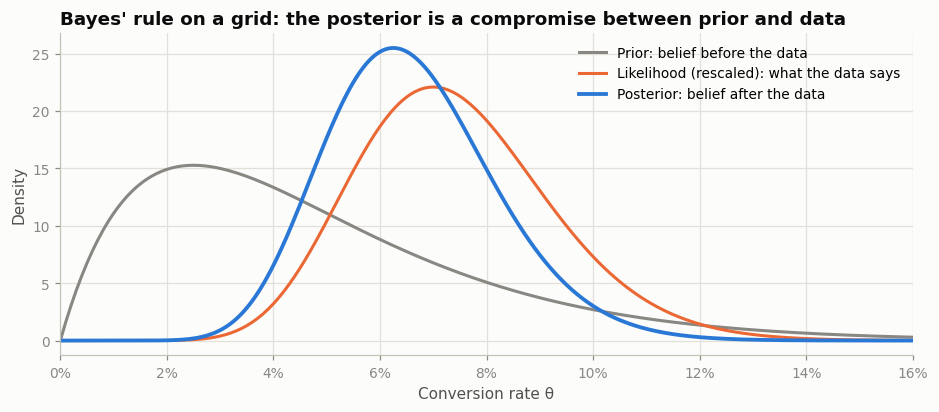

Raw data estimate           : 7.0%
Posterior mean              : 6.6%
94% credible interval       : 4.0% to 9.9%
Probability that θ exceeds 5%: 84%


In [4]:
# Data: 14 buyers out of 200 visitors.
n_visitors, n_buyers = 200, 14

# 1) A grid of candidate conversion rates between 0 and 30%.
theta = np.linspace(0.0, 0.30, 601)

# 2) Prior: a Beta(2, 40) distribution. Its mean is 2 / (2 + 40) = 4.8% and it puts
#    most of its weight between 1% and 12%: "conversion rates are usually a few percent".
prior = stats.beta.pdf(theta, 2, 40)

# 3) Likelihood: probability of seeing 14 buyers in 200 visitors for each candidate rate.
likelihood = stats.binom.pmf(n_buyers, n_visitors, theta)

# 4) Posterior is proportional to prior times likelihood. Rescale so it integrates to 1.
unnormalised = prior * likelihood
posterior = unnormalised / np.trapezoid(unnormalised, theta)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(theta, prior, color=MUTED, label="Prior: belief before the data")
ax.plot(theta, likelihood / np.trapezoid(likelihood, theta), color=ORANGE, label="Likelihood (rescaled): what the data says")
ax.plot(theta, posterior, color=BLUE, linewidth=2.5, label="Posterior: belief after the data")
ax.set(xlabel="Conversion rate θ", ylabel="Density", xlim=(0, 0.16),
       title="Bayes' rule on a grid: the posterior is a compromise between prior and data")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.legend()
plt.show()

post_mean = np.trapezoid(theta * posterior, theta)
cdf = np.cumsum(posterior) * (theta[1] - theta[0])
lo, hi = theta[np.searchsorted(cdf, 0.03)], theta[np.searchsorted(cdf, 0.97)]
print(f"Raw data estimate           : {n_buyers / n_visitors:.1%}")
print(f"Posterior mean              : {post_mean:.1%}")
print(f"94% credible interval       : {lo:.1%} to {hi:.1%}")
print(f"Probability that θ exceeds 5%: {1 - cdf[np.searchsorted(theta, 0.05)]:.0%}")

**Reading the output.** The grey prior is centred near 5%. The orange likelihood peaks at the raw data estimate of 7%. The blue posterior sits between them, closer to the data, because 200 visitors carry more information than our vague prior. With more data the posterior would move further towards the likelihood and become narrower; with less data it would stay closer to the prior. That behaviour, **the prior matters most when data is scarce**, is the reason Bayesian methods suit MMM: three years of weekly data is only 156 rows, and we ask it to estimate dozens of parameters.

Two terms used throughout the notebook:

* A **credible interval** is a range that contains the unknown with a stated probability. "94% credible interval of 4.0% to 9.9%" means: given the model and data, there is a 94% probability that $\theta$ lies in that range. (This is the interpretation people often wrongly give to a frequentist confidence interval.)
* An **HDI**, *highest density interval*, is the narrowest such range. PyMC and ArviZ report 94% HDIs by default. Why 94 and not 95? To remind us that the cut-off is arbitrary.

## 2.3 Why we need sampling: MCMC

The grid trick worked because there was one unknown. An MMM has dozens: with 30 unknowns and only 10 grid points each, we would need $10^{30}$ evaluations. That is impossible.

The solution is **Markov chain Monte Carlo (MCMC)**. Rather than evaluating the posterior everywhere, MCMC produces a long list of *samples* (also called *draws*) from it. Once you have, say, 4,000 samples of $\theta$, any question is answered by counting: the posterior mean is the average of the samples, the 94% interval is the range containing the middle 94% of them, and the probability that $\theta > 5\%$ is the fraction of samples above 5%.

The simplest MCMC algorithm, **Metropolis**, is a guided random walk:

1. Start anywhere.
2. Propose a small random step.
3. If the new position has a higher posterior value, move there. If it is lower, move there only sometimes, with probability equal to the ratio of the two values.
4. Record where you are, and repeat.

The walk spends time in each region in proportion to its posterior probability, so the recorded positions are samples from the posterior. We implement it in a dozen lines below.

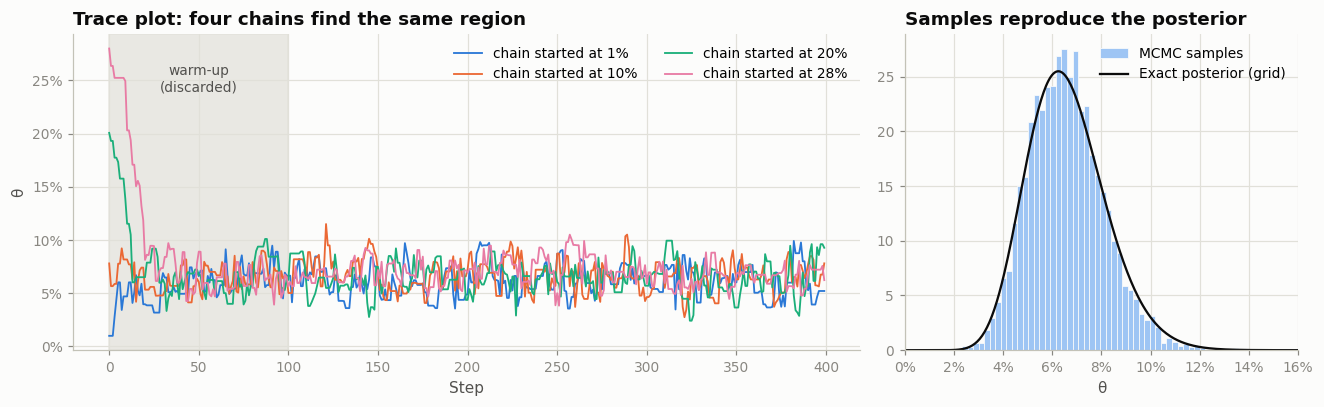

Posterior mean from samples: 6.6%  (grid answer: 6.6%)


In [5]:
def log_posterior(t: float) -> float:
    """Log of (prior x likelihood) for the conversion-rate example. Logs avoid tiny numbers."""
    if not 0.0 < t < 1.0:
        return -np.inf
    return stats.beta.logpdf(t, 2, 40) + stats.binom.logpmf(n_buyers, n_visitors, t)


def metropolis(start: float, n_steps: int, step_size: float, rng: np.random.Generator) -> np.ndarray:
    """A minimal Metropolis sampler: a random walk that accepts or rejects each proposed step."""
    samples = np.empty(n_steps)
    current, current_lp = start, log_posterior(start)
    for i in range(n_steps):  # an explicit loop is clearest here: each step depends on the last
        proposal = current + rng.normal(0.0, step_size)
        proposal_lp = log_posterior(proposal)
        # Accept with probability min(1, posterior(proposal) / posterior(current)).
        if np.log(rng.uniform()) < proposal_lp - current_lp:
            current, current_lp = proposal, proposal_lp
        samples[i] = current
    return samples


rng_demo = np.random.default_rng(SEED)
# Four independent walks ("chains") started from deliberately different places.
starts = [0.01, 0.10, 0.20, 0.28]
chains = np.array([metropolis(s, 2_000, 0.02, rng_demo) for s in starts])

chain_colors = [BLUE, ORANGE, "#1baf7a", "#e87ba4"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
for chain, color, s in zip(chains, chain_colors, starts):
    axes[0].plot(chain[:400], color=color, linewidth=1.2, label=f"chain started at {s:.0%}")
axes[0].axvspan(0, 100, color=GRID, alpha=0.7)
axes[0].text(50, 0.265, "warm-up\n(discarded)", ha="center", va="top", color=INK_2, fontsize=9)
axes[0].set(xlabel="Step", ylabel="θ", title="Trace plot: four chains find the same region")
axes[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
axes[0].legend(ncol=2)

kept = chains[:, 100:].ravel()  # drop warm-up, pool the four chains
axes[1].hist(kept, bins=50, density=True, color=BLUE_LIGHT, edgecolor=SURFACE, linewidth=0.5, label="MCMC samples")
axes[1].plot(theta, posterior, color=INK, linewidth=1.5, label="Exact posterior (grid)")
axes[1].set(xlabel="θ", xlim=(0, 0.16), title="Samples reproduce the posterior")
axes[1].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Posterior mean from samples: {kept.mean():.1%}  (grid answer: {post_mean:.1%})")

**Reading the output.** The left panel is a **trace plot**: the value of $\theta$ at each step, one line per chain. Three things to notice, because we will look for them in every model that follows.

* **Warm-up** (also called *tuning* or *burn-in*). Each chain starts somewhere arbitrary and needs time to find the region of high probability. Those early steps are not samples from the posterior and are thrown away.
* **Multiple chains.** We ran four independent walks from different starting points. If the sampler works, they all end up exploring the same region and their traces overlap like a "fuzzy caterpillar". If one chain wandered somewhere different, we would know something is wrong. With a single chain we could not tell.
* **Autocorrelation.** Each step is close to the previous one, so consecutive samples are not independent. 2,000 correlated samples carry less information than 2,000 independent ones. The **effective sample size (ESS)** measures how many independent samples the chain is worth.

The right panel confirms that the histogram of samples matches the exact posterior from the grid.

## 2.4 The sampler we actually use: NUTS

Metropolis proposes steps blindly, which becomes hopelessly slow with many parameters. Modern libraries use **Hamiltonian Monte Carlo (HMC)** and its self-tuning variant **NUTS** (the *No-U-Turn Sampler*). HMC uses the *gradient* (slope) of the posterior to propose long, well-aimed moves, like a ball rolling over a landscape instead of a drunkard's walk. Both PyMC and Meridian use NUTS. You never need to implement it, but you do need to check its health indicators:

| Diagnostic | What it measures | Healthy value |
|---|---|---|
| **R-hat** ($\hat R$) | Do the chains agree? Compares variation between chains with variation within chains. | Below 1.01 (Meridian's own threshold is a looser 1.2) |
| **ESS** (bulk and tail) | How many independent samples the draws are worth, for the centre and for the tails of the distribution. | At least 400 in total, more for stable intervals |
| **Divergences** | Steps where the sampler's simulation broke down, usually in a region of sharp curvature. They signal that part of the posterior may be unexplored. | Zero, or a tiny handful |

If these fail, the numbers the model reports cannot be trusted, however sensible they look. **Checking convergence is not optional.**

## 2.5 The same model in PyMC

Here is the conversion-rate model written in PyMC. The pattern is the same for every PyMC model, including the MMM: declare the unknowns with their priors, declare how the data depends on them, then call `pm.sample`.

In [6]:
with pm.Model() as conversion_model:
    # Prior for the unknown conversion rate.
    theta_rv = pm.Beta("theta", alpha=2, beta=40)
    # Likelihood: observed buyers out of visitors, given theta.
    pm.Binomial("buyers", n=n_visitors, p=theta_rv, observed=n_buyers)
    # Draw samples from the posterior with NUTS: 4 chains, 1000 warm-up and 1000 kept draws each.
    idata_demo = pm.sample(draws=1_000, tune=1_000, chains=4, cores=1,
                           random_seed=SEED, progressbar=False)

az.summary(idata_demo, hdi_prob=0.94)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
theta,0.066,0.016,0.036,0.095,0.0,0.0,1584.0,2452.0,1.0


**Reading the output.** `az.summary` is the table you will see for every model. Column by column:

* `mean`, `sd`: the posterior mean and standard deviation of the parameter.
* `hdi_3%`, `hdi_97%`: the ends of the 94% highest density interval.
* `mcse_mean`, `mcse_sd`: *Monte Carlo standard error*, the error that comes from using a finite number of samples. It should be small relative to `sd`.
* `ess_bulk`, `ess_tail`: effective sample size for the centre and the tails.
* `r_hat`: the chain-agreement statistic. Here it is 1.0, as it should be.

The posterior mean matches the grid and Metropolis answers. The object `idata_demo` is an ArviZ **InferenceData**: a container holding the posterior samples and the sampler's statistics, organised into named groups (`posterior`, `sample_stats`, and so on). Both libraries store their results in this format.

## 2.6 Checking a model against reality: predictive checks

A Bayesian model can *simulate* data, and that gives us two checks we will use repeatedly.

* **Prior predictive check**, before fitting. Draw parameters from the priors, simulate data, and ask: *do these simulated datasets look remotely like something that could happen?* If the priors imply sales of minus two billion dollars, they need fixing before any fitting.
* **Posterior predictive check**, after fitting. Draw parameters from the posterior, simulate data, and ask: *does the simulated data look like the data we observed?* If not, the model is missing something.

## 2.7 Why Bayesian methods suit MMM

1. **Little data, many parameters.** Priors keep estimates stable when the data alone cannot decide.
2. **Domain knowledge has a formal place.** "Advertising cannot reduce sales" or "TV effects last longer than search effects" can be written into the priors.
3. **Uncertainty comes for free.** A budget decision based on "ROAS is 2.1" is very different from one based on "ROAS is between 0.4 and 3.8". The posterior tells you which situation you are in.
4. **Experiments can be folded in.** A lift test becomes extra evidence that narrows the posterior (Section 6.9).

The cost is that the answer depends on the priors when the data is weak. This is a feature only if the priors are chosen and reported with care, which is why we spend time on them.

---
# Part III. The building blocks of an MMM

A plain linear regression of sales on spend would assume that a dollar spent this week affects only this week, and that the millionth dollar works as well as the first. Both assumptions are wrong for advertising. MMMs fix them with two transformations applied to each channel's spend before it enters the regression.

## 3.1 Adstock: advertising has memory

Someone who sees a TV advertisement today may buy next week or the week after. The effect of advertising **carries over** into later periods and fades. The transformation that models this is called **adstock**.

The most common form is **geometric adstock**. Each week, a fraction $\alpha$ (between 0 and 1) of last week's effect survives:

$$
\text{adstock}_t \;=\; \frac{x_t + \alpha\,x_{t-1} + \alpha^2 x_{t-2} + \dots + \alpha^{L} x_{t-L}}{1 + \alpha + \alpha^2 + \dots + \alpha^{L}}
$$

* $x_t$ is spend in week $t$.
* $\alpha$ is the **decay** or **retention rate**. $\alpha = 0$ means no memory; $\alpha = 0.7$ means 70% of the effect survives each week.
* $L$ is the **maximum lag** (`l_max`): how many weeks back we look. We use 8.
* The denominator **normalises** the weights so they sum to one. Adstock then *spreads* spend over time without changing its total, which keeps the other parameters interpretable.

A handy summary is the **half-life**, the number of weeks until the effect falls to half: $\log(0.5)/\log(\alpha)$. For $\alpha = 0.65$ that is about 1.6 weeks.

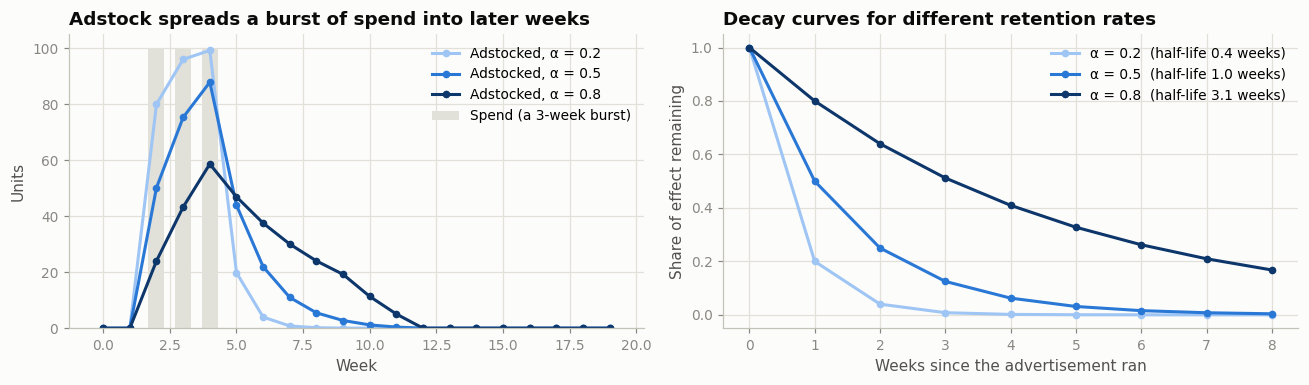

In [7]:
def geometric_adstock_np(x: np.ndarray, alpha: float, l_max: int = 8) -> np.ndarray:
    """Normalised geometric adstock, written in plain NumPy for teaching.

    Each output value is a weighted average of the current and previous `l_max - 1` inputs,
    with weights 1, alpha, alpha^2, ... that are rescaled to sum to one.
    """
    weights = alpha ** np.arange(l_max)
    weights = weights / weights.sum()
    # Convolution slides the weights along the series; trimming keeps the original length.
    return np.convolve(x, weights)[: len(x)]


weeks = np.arange(20)
burst = np.zeros(20)
burst[2:5] = 100.0  # a three-week advertising burst

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(weeks, burst, color=GRID, width=0.6, label="Spend (a 3-week burst)")
for alpha, color in zip([0.2, 0.5, 0.8], [BLUE_LIGHT, BLUE, "#0d366b"]):
    axes[0].plot(weeks, geometric_adstock_np(burst, alpha), color=color, marker="o", markersize=4,
                 label=f"Adstocked, α = {alpha}")
axes[0].set(xlabel="Week", ylabel="Units", title="Adstock spreads a burst of spend into later weeks")
axes[0].legend()

lags = np.arange(9)
for alpha, color in zip([0.2, 0.5, 0.8], [BLUE_LIGHT, BLUE, "#0d366b"]):
    axes[1].plot(lags, alpha ** lags, color=color, marker="o", markersize=4,
                 label=f"α = {alpha}  (half-life {np.log(0.5) / np.log(alpha):.1f} weeks)")
axes[1].set(xlabel="Weeks since the advertisement ran", ylabel="Share of effect remaining",
            title="Decay curves for different retention rates")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3.2 Saturation: diminishing returns

The first advertisement someone sees can change their mind. The twentieth one, shown to the same person in the same week, changes very little. As spend grows, each extra dollar produces less extra sales. This is **saturation**, or **diminishing returns**, and it is what makes budget optimisation possible: if returns never diminished, the best plan would always be to put everything into the single best channel.

A saturation function turns (adstocked) spend into a response that rises quickly at first and then flattens. The two libraries use different curves by default.

**Logistic saturation** (PyMC-Marketing's default):

$$
\text{saturation}(x) \;=\; \frac{1 - e^{-\lambda x}}{1 + e^{-\lambda x}}
$$

$\lambda$ (lambda) controls how fast the curve bends. A large $\lambda$ saturates early. The curve starts at 0 and approaches 1; it is then multiplied by a coefficient $\beta$ that sets the maximum possible contribution of the channel.

**Hill saturation** (Meridian's default):

$$
\text{Hill}(x) \;=\; \frac{x^{s}}{x^{s} + ec^{\,s}}
$$

$ec$ is the **half-saturation point**: the spend level at which the response is half its maximum. $s$ is the **slope**. With $s \le 1$ the curve is concave (diminishing returns from the first dollar); with $s > 1$ it is **S-shaped**: low spend does almost nothing, then there is a threshold, then it flattens.

The two families can produce similar shapes over the range where data exists, but they are not identical. This matters in Part VIII: we generate data with the logistic curve, which gives PyMC-Marketing a home advantage and makes Meridian fit a model that is slightly *misspecified*, as every model is on real data.

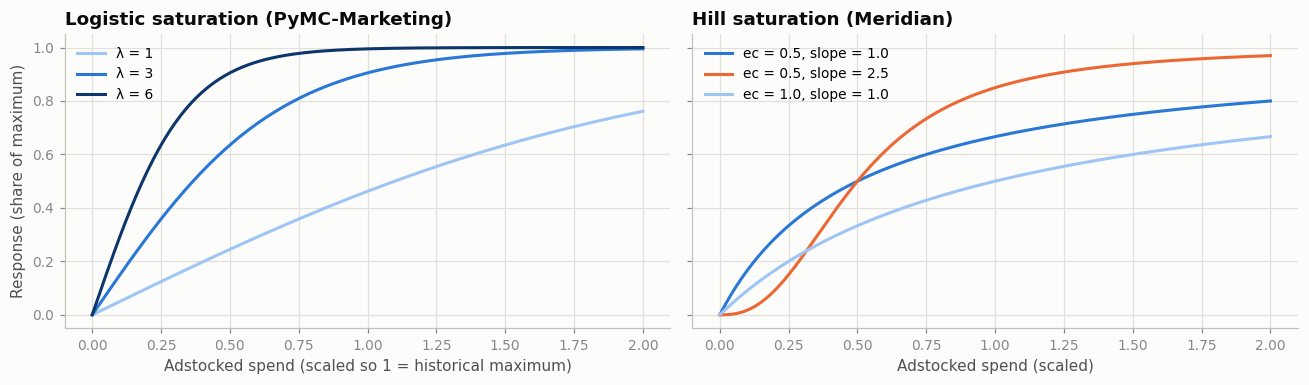

In [8]:
x_grid = np.linspace(0, 2, 200)


def logistic_saturation_np(x: np.ndarray, lam: float) -> np.ndarray:
    """Logistic saturation: rises from 0 and flattens towards 1."""
    return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))


def hill_np(x: np.ndarray, ec: float, slope: float) -> np.ndarray:
    """Hill saturation: `ec` is the half-saturation point, `slope` controls the shape."""
    return x**slope / (x**slope + ec**slope)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for lam, color in zip([1, 3, 6], [BLUE_LIGHT, BLUE, "#0d366b"]):
    axes[0].plot(x_grid, logistic_saturation_np(x_grid, lam), color=color, label=f"λ = {lam}")
axes[0].set(xlabel="Adstocked spend (scaled so 1 = historical maximum)", ylabel="Response (share of maximum)",
            title="Logistic saturation (PyMC-Marketing)")
axes[0].legend()

for (ec, slope), color in zip([(0.5, 1.0), (0.5, 2.5), (1.0, 1.0)], [BLUE, ORANGE, BLUE_LIGHT]):
    axes[1].plot(x_grid, hill_np(x_grid, ec, slope), color=color, label=f"ec = {ec}, slope = {slope}")
axes[1].set(xlabel="Adstocked spend (scaled)", title="Hill saturation (Meridian)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Two kinds of return.** Saturation forces us to distinguish:

* **Average return (ROAS or ROI):** total incremental sales divided by total spend. "What did this channel earn per dollar overall?"
* **Marginal return (mROAS or mROI):** the extra sales from the *next* dollar. "What would one more dollar earn?"

On a saturating curve the marginal return is always below the average return, and budget decisions should be made on the marginal one. A channel can have an excellent average ROAS and still be a bad place for extra money, because it is already saturated.

## 3.3 The baseline: trend, seasonality, controls

Everything that is not media goes into the **baseline**.

* **Intercept:** the level of sales with no media and all else at its reference value.
* **Trend:** slow growth or decline (brand strength, distribution, market size).
* **Seasonality:** patterns that repeat every year. PyMC-Marketing models it with a **Fourier series**: a sum of sine and cosine waves with periods of one year, half a year, and so on. With $K$ "modes" you get $2K$ waves, each with its own coefficient, and their sum can approximate any smooth yearly pattern:
$$
\text{seasonality}_t = \sum_{k=1}^{K}\Big[a_k \sin\!\Big(\tfrac{2\pi k\, d_t}{365.25}\Big) + b_k \cos\!\Big(\tfrac{2\pi k\, d_t}{365.25}\Big)\Big], \quad d_t = \text{day of year}
$$
* **Control variables:** measured things that move sales and that we do not want to mistake for media effects: price, promotions, holidays, competitor activity, weather. Each gets a regression coefficient.

Controls are not a formality. **A control that affects both spend and sales is a confounder, and omitting it biases the media estimates** (Section 1.2). Choosing controls is the main causal-inference step in an MMM.

## 3.4 The whole model in one line

Putting the blocks together, the model PyMC-Marketing fits is:

$$
y_t \;=\; \underbrace{\alpha_0}_{\text{intercept}} \;+\; \underbrace{\sum_{m=1}^{M} \beta_m \,\text{saturation}\big(\text{adstock}(x_{m,t};\,\alpha_m);\,\lambda_m\big)}_{\text{media}} \;+\; \underbrace{\sum_{c} \gamma_c\, z_{c,t}}_{\text{controls}} \;+\; \underbrace{\text{seasonality}_t + \text{trend}_t}_{\text{time structure}} \;+\; \varepsilon_t, \qquad \varepsilon_t \sim \text{Normal}(0, \sigma)
$$

For each channel $m$ there are three unknowns: retention $\alpha_m$, saturation speed $\lambda_m$ and size $\beta_m$. Then one coefficient $\gamma_c$ per control, the seasonal and trend coefficients, the intercept and the noise level $\sigma$. With five channels that is about 35 parameters estimated from 143 weekly observations. This is why priors are needed.

**Scaling.** Before fitting, PyMC-Marketing divides sales by its maximum and each channel's spend by that channel's maximum, so everything lies between 0 and 1. This makes generic priors meaningful (a $\beta$ of 0.2 means "at most 20% of peak sales") and helps the sampler. Results are converted back to dollars afterwards. Meridian does a similar internal scaling.

---
# Part IV. Manufacturing a realistic dataset

## 4.1 Why synthetic data?

With real data we never learn the true contribution of a channel, so we cannot tell whether a model's answer is right. With synthetic data we write the rules ourselves, so we can grade the model. This is called a **parameter recovery study**, and it is the standard way to validate an MMM pipeline before trusting it with real money.

## 4.2 The PyMC-Marketing data-generation workflow

PyMC-Marketing's recommended recipe ("Generating Synthetic MMM Data" in its documentation) uses the MMM class itself as the simulator:

1. **Generate the inputs** (spend and control variables), ideally with realistic correlations.
2. **Build an `MMM`** on those inputs with a placeholder target.
3. **Clamp every parameter to a chosen "true" value** using PyMC's `do` operator. `do` replaces a random variable in a model by a fixed value. It is named after the *do-operator* of causal inference, which represents an intervention ("set this to that").
4. **Forward-sample**: push the inputs through the now fully specified model and draw the noisy sales series.

Because the simulator is the same code as the model, there can be no mismatch between how the data was generated and how adstock and saturation are defined.

## 4.3 The difficulties we build in

The official tutorial generates clean data. Real marketing data is not clean, so we add the problems that practitioners actually meet. Each one is a lesson later in the notebook.

| # | Difficulty | How we build it | Why it hurts |
|---|---|---|---|
| 1 | **Multicollinearity** | Search and social budgets move together (correlation about 0.8) | The model cannot tell which of the two caused the sales |
| 2 | **Confounding by demand** | Search spend follows an *unobserved* market-demand index that also drives sales directly | Search gets credit for sales that demand caused |
| 3 | **Seasonal budgets** | All channels spend more in the fourth quarter, when sales are high anyway | Media and seasonality are entangled |
| 4 | **Flighting** | TV runs in 6-week bursts with silent weeks between | Many zeros; but also useful on/off variation |
| 5 | **A channel launched mid-way** | Online video starts after 60 weeks | A structural zero block and less data for that channel |
| 6 | **A weak channel** | Display has a small budget and a small effect | Its signal is smaller than the noise |
| 7 | **Different carry-over per channel** | TV retains 65% per week, search 10% | Adstock must be learned per channel |
| 8 | **Non-linear trend** | Growth accelerates part-way through | A straight-line trend is not enough |
| 9 | **Holidays** | Black Friday and Christmas spikes | Large outliers if not modelled |
| 10 | **Price promotions** | 14 discount weeks | A strong non-media driver |
| 11 | **Omitted variable** | Competitor promotions reduce sales but are *not in the analyst's data* | Unexplained dips; inflated noise |
| 12 | **Supply shock outlier** | A 2-week stock-out that nobody recorded | A level outlier the analyst must find |
| 13 | **Missing values** | Two weeks of display spend are missing | Must be handled explicitly |
| 14 | **Short history** | 156 weeks, 5 channels | Low data-to-parameter ratio |

## 4.4 Step 1: time axis and hidden drivers

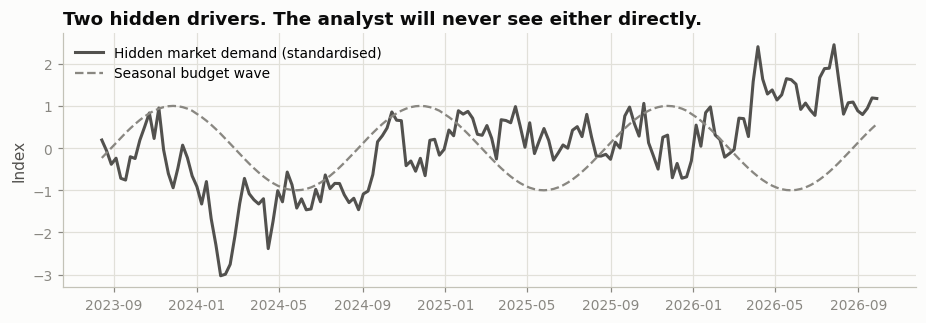

In [9]:
rng = np.random.default_rng(SEED)

L_MAX: int = 8        # adstock window, in weeks
N_OBS: int = 156      # three years of weekly data that the analyst will see
N_TOTAL: int = N_OBS + L_MAX  # we simulate 8 extra weeks first and then discard them (see 4.8)

dates = pd.date_range(end="2026-09-28", periods=N_TOTAL, freq="W-MON")  # weeks starting on Mondays
t_unit = np.arange(N_TOTAL) / (N_TOTAL - 1)                               # time running from 0 to 1
week_of_year = dates.isocalendar().week.to_numpy().astype(float)

# A smooth yearly wave that peaks in late November. It drives BUDGETS (difficulty 3).
season_wave = np.cos(2 * np.pi * (week_of_year - 48) / 52.18)

# Hidden market demand (difficulty 2): a slowly wandering index. "AR(1)" means each week's
# value is 0.85 times last week's value plus a fresh random shock.
shocks = rng.normal(0, 1, N_TOTAL)
demand_raw = np.zeros(N_TOTAL)
for i in range(1, N_TOTAL):  # explicit loop: each value depends on the previous one
    demand_raw[i] = 0.85 * demand_raw[i - 1] + shocks[i]
demand = (demand_raw - demand_raw.mean()) / demand_raw.std()  # standardise: mean 0, sd 1

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(dates, demand, color=INK_2, label="Hidden market demand (standardised)")
ax.plot(dates, season_wave, color=MUTED, linestyle="--", linewidth=1.5, label="Seasonal budget wave")
ax.set(title="Two hidden drivers. The analyst will never see either directly.", ylabel="Index")
ax.legend()
plt.show()

## 4.5 Step 2: a generative model for media spend

Following the official workflow, spend comes from a small PyMC model. Each channel has a mean level that responds to the season, to hidden demand and to time, and the week-to-week randomness is drawn from a **multivariate normal** distribution with a chosen correlation matrix. That is how we get budgets that move together (difficulty 1). A `softplus` function, a smooth version of "take the positive part", keeps spend positive.

Notice the row of `demand_weight`: search responds strongly to hidden demand. That single line creates the confounding of difficulty 2.

In [10]:
# Correlation between the random weekly budget movements of the channels.
#                    tv   search social display video
spend_corr = np.array([
    [1.0, 0.1, 0.1, 0.0, 0.1],   # tv
    [0.1, 1.0, 0.6, 0.3, 0.2],   # search
    [0.1, 0.6, 1.0, 0.3, 0.2],   # social   <- moves with search
    [0.0, 0.3, 0.3, 1.0, 0.1],   # display
    [0.1, 0.2, 0.2, 0.1, 1.0],   # video
])
spend_sd = np.array([0.25, 0.25, 0.30, 0.45, 0.30])
spend_chol = np.linalg.cholesky(spend_corr * np.outer(spend_sd, spend_sd))  # "square root" of the covariance

# How strongly each channel's budget follows each driver.
#                          tv   search social display video
base_level    = np.array([1.2, 1.00, 1.00, 1.00, 1.0])
season_weight = np.array([0.3, 0.45, 0.50, 0.10, 0.2])   # Q4 budget increases
demand_weight = np.array([0.0, 0.30, 0.10, 0.00, 0.0])   # search (and a little social) chase demand
trend_weight  = np.array([0.0, 0.30, 0.40, 0.00, 0.6])   # digital budgets grow over time
dollars       = np.array([60_000, 18_000, 13_000, 4_500, 11_000])  # converts unit levels to weekly dollars

coords = {"date": dates, "channel": CHANNELS}
with pm.Model(coords=coords) as covariates_model:
    mean_level = (
        base_level[None, :]
        + np.outer(season_wave, season_weight)
        + np.outer(demand, demand_weight)
        + np.outer(t_unit, trend_weight)
    )
    x_raw = pm.MvNormal("x_raw", mu=mean_level, chol=spend_chol, dims=("date", "channel"))
    pm.Deterministic("x", pt.softplus(2.5 * x_raw) / 2.5, dims=("date", "channel"))

# One random realisation of the spend process.
spend = pm.draw(covariates_model["x"], random_seed=rng) * dollars

# Difficulty 4, flighting: TV is on for 6 weeks, then off for 4 to 7 weeks.
tv_on = np.zeros(N_TOTAL, dtype=bool)
start = 3
while start < N_TOTAL:
    tv_on[start:start + 6] = True
    start += 6 + int(rng.integers(4, 8))
spend[:, 0] *= tv_on

# Difficulty 5, mid-way launch: video starts 60 weeks into the observed data and ramps up.
VIDEO_LAUNCH: int = L_MAX + 60
spend[:VIDEO_LAUNCH, 4] = 0.0
spend[VIDEO_LAUNCH:VIDEO_LAUNCH + 8, 4] *= np.linspace(0.3, 1.0, 8)

spend = np.round(spend, 2)
pd.DataFrame(spend, columns=CHANNELS, index=dates).describe().T.round(0)

,count,mean,std,min,25%,50%,75%,max
tv,164.0,37791.0,39682.0,0.0,0.0,36821.0,71697.0,128706.0
search,164.0,21387.0,8115.0,3524.0,15323.0,21942.0,27062.0,42104.0
social,164.0,15954.0,5428.0,2581.0,12001.0,15989.0,19657.0,32578.0
display,164.0,4743.0,1758.0,1068.0,3530.0,4633.0,5877.0,10829.0
video,164.0,9006.0,8138.0,0.0,0.0,11158.0,16184.0,23837.0


## 4.6 Step 3: control variables

In [11]:
def is_black_friday_week(week_start: pd.Timestamp) -> bool:
    """True if the week starting on this Monday contains Black Friday (the 4th Friday of November)."""
    friday = week_start + pd.Timedelta(days=4)
    return friday.month == 11 and 23 <= friday.day <= 29


def is_christmas_week(week_start: pd.Timestamp) -> bool:
    """True if the week starting on this Monday contains 25 December."""
    christmas = pd.Timestamp(week_start.year, 12, 25)
    return week_start <= christmas <= week_start + pd.Timedelta(days=6)


# Difficulty 8: the trend is a straight line whose slope increases after 55% of the timeline.
trend_shape = t_unit + 0.8 * np.clip(t_unit - 0.55, 0, None)

# Difficulty 10: a price index around 1.0 with 14 promotional weeks at an 8% to 18% discount.
price_index = np.ones(N_TOTAL)
promo_weeks = rng.choice(np.arange(L_MAX, N_TOTAL), size=14, replace=False)
price_index[promo_weeks] = rng.uniform(0.82, 0.92, size=14)
price_index = price_index + rng.normal(0, 0.01, N_TOTAL)

# Difficulty 11: six 2-week competitor promotions. The analyst will NOT get this column.
competitor_promo = np.zeros(N_TOTAL)
for s in rng.choice(np.arange(L_MAX, N_TOTAL - 3), size=6, replace=False):
    competitor_promo[s:s + 2] = 1.0

# Difficulty 9: holiday indicators (1 in the holiday week, 0 otherwise).
black_friday = np.array([is_black_friday_week(d) for d in dates], dtype=float)
christmas = np.array([is_christmas_week(d) for d in dates], dtype=float)

# Difficulty 12: an unrecorded 2-week stock-out.
STOCKOUT_START: int = L_MAX + 97
stockout = np.zeros(N_TOTAL)
stockout[STOCKOUT_START:STOCKOUT_START + 2] = 1.0

# Everything the SIMULATOR needs, in one table. `y_dummy` is a placeholder target.
gen_df = pd.DataFrame(spend, columns=CHANNELS)
gen_df.insert(0, "date", dates)
gen_df = gen_df.assign(
    trend=trend_shape,
    price_dev=price_index - 1.0,      # price relative to the regular price
    demand=demand,
    competitor_promo=competitor_promo,
    black_friday=black_friday,
    christmas=christmas,
    stockout=stockout,
    y_dummy=1.0,
)
GEN_CONTROLS: list[str] = ["trend", "price_dev", "demand", "competitor_promo", "black_friday", "christmas", "stockout"]
gen_df.head(3)

,date,tv,search,social,display,video,trend,price_dev,demand,competitor_promo,black_friday,christmas,stockout,y_dummy
0,2023-08-14,0.0,12159.22,6133.39,4704.61,0.0,0.000000,0.013234,0.191311,0.0,0.0,0.0,0.0,1.0
1,2023-08-21,0.0,17833.03,15252.65,2923.36,0.0,0.006135,-0.023744,-0.061864,0.0,0.0,0.0,0.0,1.0
2,2023-08-28,0.0,21914.33,17901.09,8288.60,0.0,0.012270,-0.012512,-0.384013,0.0,0.0,0.0,0.0,1.0


## 4.7 Step 4: choose the truth

These are the "laws of nature" of our simulated market. Because the placeholder target equals 1, the model's internal sales scale is 1, so we can state every effect directly in **dollars of weekly sales**.

* `adstock_alpha`: weekly retention per channel. TV lingers; search is almost immediate.
* `saturation_lam`: how quickly each channel saturates. Remember that spend is divided by its historical maximum, so $\lambda$ acts on a 0-to-1 scale.
* `saturation_beta`: the ceiling of each channel's weekly contribution, in dollars.
* `gamma_control`: the dollar effect per unit of each control. For example a competitor promotion costs \$30,000 a week, and a 10% price cut (`price_dev` = -0.10) adds $-420{,}000 \times -0.10 = \$42{,}000$.
* `gamma_fourier`: the size of the four seasonal waves.
* `y_sigma`: the standard deviation of the weekly noise.

In [12]:
TRUE_PARAMS: dict = {
    "intercept": 300_000.0,
    #                               tv      search   social  display  video
    "adstock_alpha":   np.array([0.65,     0.10,    0.30,    0.20,    0.50]),
    "saturation_lam":  np.array([2.0,      3.5,     2.5,     1.5,     2.0]),
    "saturation_beta": np.array([190_000., 78_000., 35_000., 6_000.,  50_000.]),
    #                           trend    price_dev  demand   competitor black_fri christmas stockout
    "gamma_control":   np.array([70_000., -420_000., 28_000., -30_000.,  95_000.,  45_000.,  -130_000.]),
    #                           sin_1     sin_2    cos_1    cos_2
    "gamma_fourier":   np.array([-10_000., 4_000.,  20_000., 6_000.]),
    "y_sigma": 14_000.0,
}

## 4.8 Step 5: build the simulator, clamp it with `do`, and sample

In [13]:
# The same MMM class we will later fit, used here as a simulator.
generator = MMM(
    date_column="date",
    target_column="y_dummy",
    channel_columns=CHANNELS,
    control_columns=GEN_CONTROLS,
    adstock=GeometricAdstock(l_max=L_MAX),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,          # two Fourier modes = four waves
)
generator.build_model(gen_df.drop(columns="y_dummy"), gen_df["y_dummy"])

print("Unknowns of the model (these are what we clamp):")
print(" ", [rv.name for rv in generator.model.free_RVs])

# `do` returns a copy of the model in which each named random variable is a fixed constant.
generator.model = do(
    generator.model,
    {
        "intercept_contribution": TRUE_PARAMS["intercept"],
        "adstock_alpha": TRUE_PARAMS["adstock_alpha"],
        "saturation_lam": TRUE_PARAMS["saturation_lam"],
        "saturation_beta": TRUE_PARAMS["saturation_beta"],
        "gamma_control": TRUE_PARAMS["gamma_control"],
        "gamma_fourier": TRUE_PARAMS["gamma_fourier"],
        "y_sigma": TRUE_PARAMS["y_sigma"],
    },
)

# With all parameters fixed, "sampling from the prior" is a single forward simulation:
# only the weekly noise is random.
with generator.model:
    simulated = pm.sample_prior_predictive(
        draws=1,
        var_names=["y", "channel_contribution", "control_contribution", "yearly_seasonality_contribution"],
        random_seed=rng,
    )

sim_prior = simulated.prior.sel(chain=0, draw=0)
sales_all = simulated.prior_predictive["y"].sel(chain=0, draw=0).to_numpy()
true_media_all = sim_prior["channel_contribution"].to_numpy()          # weeks x channels, in dollars
true_control_all = sim_prior["control_contribution"].to_numpy()        # weeks x controls
true_season_all = sim_prior["yearly_seasonality_contribution"].to_numpy()

# The scale the simulator used for each channel (its maximum weekly spend). Needed later
# to evaluate the TRUE response curves.
GEN_CHANNEL_SCALE = gen_df[CHANNELS].max().to_numpy()
print(f"\nSimulated {len(sales_all)} weeks; sales range ${sales_all.min():,.0f} to ${sales_all.max():,.0f}")

Unknowns of the model (these are what we clamp):
  ['intercept_contribution', 'adstock_alpha', 'saturation_lam', 'saturation_beta', 'gamma_control', 'gamma_fourier', 'y_sigma']



Simulated 164 weeks; sales range $254,109 to $717,957


**Why discard the first 8 weeks?** Adstock in week 1 needs the spend of weeks 0, -1, -2 and so on. A real company was advertising before its dataset begins, so its first observed weeks already contain carry-over from earlier, unobserved spend. We imitate that by simulating 8 extra weeks and cutting them off. The analyst's first weeks therefore contain carry-over the model cannot see, exactly as in reality.

## 4.9 Step 6: the analyst's dataset and the answer key

We now split what we have into two tables.

* **`data/mmm_weekly.csv`: what the analyst gets.** Sales, spend, price and one extra column, `brand_search_index`: a noisy *proxy* for hidden demand, like a Google Trends series for the category. The analyst does **not** get true demand, competitor promotions or the stock-out flag, and two display values are missing (difficulty 13).
* **`data/ground_truth.csv`: the answer key.** The true weekly dollar contribution of every component. We use it only for grading.

In [14]:
obs = slice(L_MAX, None)   # drop the 8 warm-up weeks

# --- The analyst's dataset -------------------------------------------------------
data = gen_df.loc[gen_df.index[obs], ["date"] + CHANNELS].reset_index(drop=True)
data.insert(1, "sales", np.round(sales_all[obs], 2))
data["price_index"] = np.round(price_index[obs], 4)
# Proxy for hidden demand: correlated with it, but noisy and on an arbitrary scale.
data["brand_search_index"] = np.round(100 * (1 + 0.25 * demand[obs]) + rng.normal(0, 6, N_OBS), 1)
# Difficulty 13: a reporting gap in display spend.
MISSING_DISPLAY_ROWS: list[int] = [41, 42]
data.loc[MISSING_DISPLAY_ROWS, "display"] = np.nan

# --- The answer key --------------------------------------------------------------
truth = pd.DataFrame({"date": dates[obs]})
for j, ch in enumerate(CHANNELS):
    truth[f"contrib_{ch}"] = true_media_all[obs, j]
for j, c in enumerate(GEN_CONTROLS):
    truth[f"contrib_{c}"] = true_control_all[obs, j]
truth["contrib_seasonality"] = true_season_all[obs]
truth["contrib_intercept"] = TRUE_PARAMS["intercept"]
truth["true_spend_display"] = gen_df["display"].to_numpy()[obs]   # display spend before values went missing
truth["hidden_demand"] = demand[obs]

Path("data").mkdir(exist_ok=True)
data.to_csv("data/mmm_weekly.csv", index=False)
truth.to_csv("data/ground_truth.csv", index=False)
with open("data/true_params.json", "w") as f:
    json.dump({k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in TRUE_PARAMS.items()}, f, indent=2)

# A fingerprint of the dataset: if the data ever changes, this hash changes, and MLflow records it.
DATA_HASH: str = hashlib.sha256(Path("data/mmm_weekly.csv").read_bytes()).hexdigest()
print(f"Saved data/mmm_weekly.csv  ({data.shape[0]} rows x {data.shape[1]} columns)  sha256 {DATA_HASH[:12]}...")
data.head()

Saved data/mmm_weekly.csv  (156 rows x 9 columns)  sha256 cb627cea15ed...


,date,sales,tv,search,social,display,video,price_index,brand_search_index
0,2023-10-09,494893.27,104894.72,25984.75,20526.70,1925.94,0.0,1.0057,122.0
1,2023-10-16,495861.37,0.00,42103.66,30311.25,6725.87,0.0,1.0123,120.1
2,2023-10-23,480519.41,0.00,27036.27,20269.06,5057.26,0.0,1.0032,124.6
3,2023-10-30,432952.77,0.00,23931.59,19203.04,8233.52,0.0,0.9985,109.5
4,2023-11-06,465282.06,0.00,38512.12,23621.11,5729.80,0.0,0.9872,126.0


## 4.10 A look at the answer key

Before putting the truth away, here is what we are trying to recover: the true decomposition of sales and each channel's true ROAS (dollars of incremental sales per dollar spent).

,total spend ($),true contribution ($),share of sales,true ROAS,retention α
tv,"5,799,874","8,202,517",10.7%,1.41,0.65
search,"3,354,024","8,227,437",10.7%,2.45,0.10
social,"2,494,583","2,912,755",3.8%,1.17,0.30
display,"736,511","293,215",0.4%,0.40,0.20
video,"1,477,007","2,677,695",3.5%,1.81,0.50


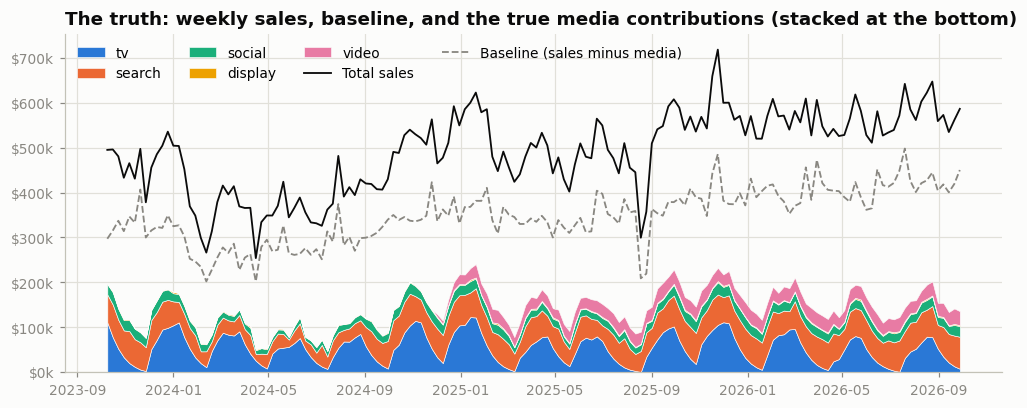

Media explains 29.1% of total sales; the baseline explains the rest.


In [15]:
media_cols = [f"contrib_{c}" for c in CHANNELS]
true_spend = gen_df[CHANNELS].to_numpy()[obs].sum(axis=0)          # true spend (no missing values)
true_roas_full = truth[media_cols].sum().to_numpy() / true_spend

answer_key = pd.DataFrame({
    "total spend ($)": true_spend,
    "true contribution ($)": truth[media_cols].sum().to_numpy(),
    "share of sales": truth[media_cols].sum().to_numpy() / data["sales"].sum(),
    "true ROAS": true_roas_full,
    "retention α": TRUE_PARAMS["adstock_alpha"],
}, index=CHANNELS)
display(answer_key.style.format({"total spend ($)": "{:,.0f}", "true contribution ($)": "{:,.0f}",
                                 "share of sales": "{:.1%}", "true ROAS": "{:.2f}", "retention α": "{:.2f}"}))

baseline_true = data["sales"].to_numpy() - truth[media_cols].sum(axis=1).to_numpy()
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(truth["date"], [truth[c].to_numpy() for c in media_cols],
             colors=[CHANNEL_COLOR[c] for c in CHANNELS], labels=CHANNELS, edgecolor=SURFACE, linewidth=0.4)
ax.plot(truth["date"], data["sales"], color=INK, linewidth=1.2, label="Total sales")
ax.plot(truth["date"], baseline_true, color=MUTED, linewidth=1.2, linestyle="--", label="Baseline (sales minus media)")
ax.set(title="The truth: weekly sales, baseline, and the true media contributions (stacked at the bottom)")
thousands(ax)
ax.legend(ncol=4, loc="upper left")
plt.show()
print(f"Media explains {truth[media_cols].sum().sum() / data['sales'].sum():.1%} of total sales; the baseline explains the rest.")

**Reading the output.** Media accounts for a bit under 30% of sales, a typical figure for an advertised consumer brand. Search has the highest true ROAS, about 2.4; TV is the largest contributor in dollars with a ROAS near 1.4; display returns about 40 cents per dollar, so it loses money. Note how small the display band is: at under 0.5% of sales, it is far below the weekly noise of \$14,000. No model can measure it precisely, and a good model should *say so* through a wide interval.

From here on we behave like an analyst who has only `data/mmm_weekly.csv`.

---
# Part V. Exploratory data analysis

Never fit a model to data you have not looked at. The purpose of EDA in an MMM project is to find data problems, understand how much independent variation each channel has, and decide which controls are needed.

## 5.1 Structure, types and missing values

In [16]:
df = pd.read_csv("data/mmm_weekly.csv", parse_dates=["date"])

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Period: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
gaps = df["date"].diff().dropna().dt.days
print(f"Weekly spacing consistent: {bool((gaps == 7).all())}   Duplicate dates: {int(df['date'].duplicated().sum())}")

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "zeros": (df.select_dtypes("number") == 0).sum().reindex(df.columns).fillna(0).astype(int),
    "min": df.select_dtypes("number").min().reindex(df.columns),
    "median": df.select_dtypes("number").median().reindex(df.columns),
    "max": df.select_dtypes("number").max().reindex(df.columns),
})
overview

Shape: 156 rows x 9 columns
Period: 2023-10-09 to 2026-09-28
Weekly spacing consistent: True   Duplicate dates: 0


,dtype,missing,zeros,min,median,max
date,datetime64[ns],0,0,NaN,NaN,NaN
sales,float64,0,0,254109.1400,505687.08000,717957.3600
tv,float64,0,77,0.0000,30371.22500,128705.5700
search,float64,0,0,3524.4600,22505.99500,42103.6600
social,float64,0,0,2580.5200,16065.09000,32577.5300
display,float64,2,0,1067.6900,4562.95000,10828.7500
video,float64,0,60,0.0000,12424.24500,23836.9200
price_index,float64,0,0,0.8145,0.99675,1.0295
brand_search_index,float64,0,0,19.6000,102.95000,161.7000


**Reading the output.**

* The time axis is clean: 156 consecutive weeks, no duplicates.
* **`display` has 2 missing values.** A sampler cannot work with missing inputs, so we must decide what to do (next cell).
* **`tv` is zero in about half the weeks and `video` is zero for the first 60.** These zeros are real (no campaign running), not missing data, so they stay.

### Handling the missing display spend

Three options: drop the weeks (breaks the weekly sequence that adstock needs), fill with zero (wrong if money was actually spent), or interpolate. The channel is always-on and the neighbouring weeks have ordinary spend, so a reporting gap is far more plausible than two weeks of zero spend. We **interpolate linearly** and keep a flag so the choice stays visible. On a real project you would first ask the media team for the invoices.

In [17]:
df["display_was_imputed"] = df["display"].isna()
print("Weeks with missing display spend:")
print(df.loc[df["display_was_imputed"], ["date", "display"]].to_string(index=False))

df["display"] = df["display"].interpolate(method="linear")
print("\nAfter linear interpolation:")
print(df.loc[df["display_was_imputed"], ["date", "display"]].round(0).to_string(index=False))

Weeks with missing display spend:
      date  display
2024-07-22      NaN
2024-07-29      NaN

After linear interpolation:
      date  display
2024-07-22   2040.0
2024-07-29   1554.0


## 5.2 The time series

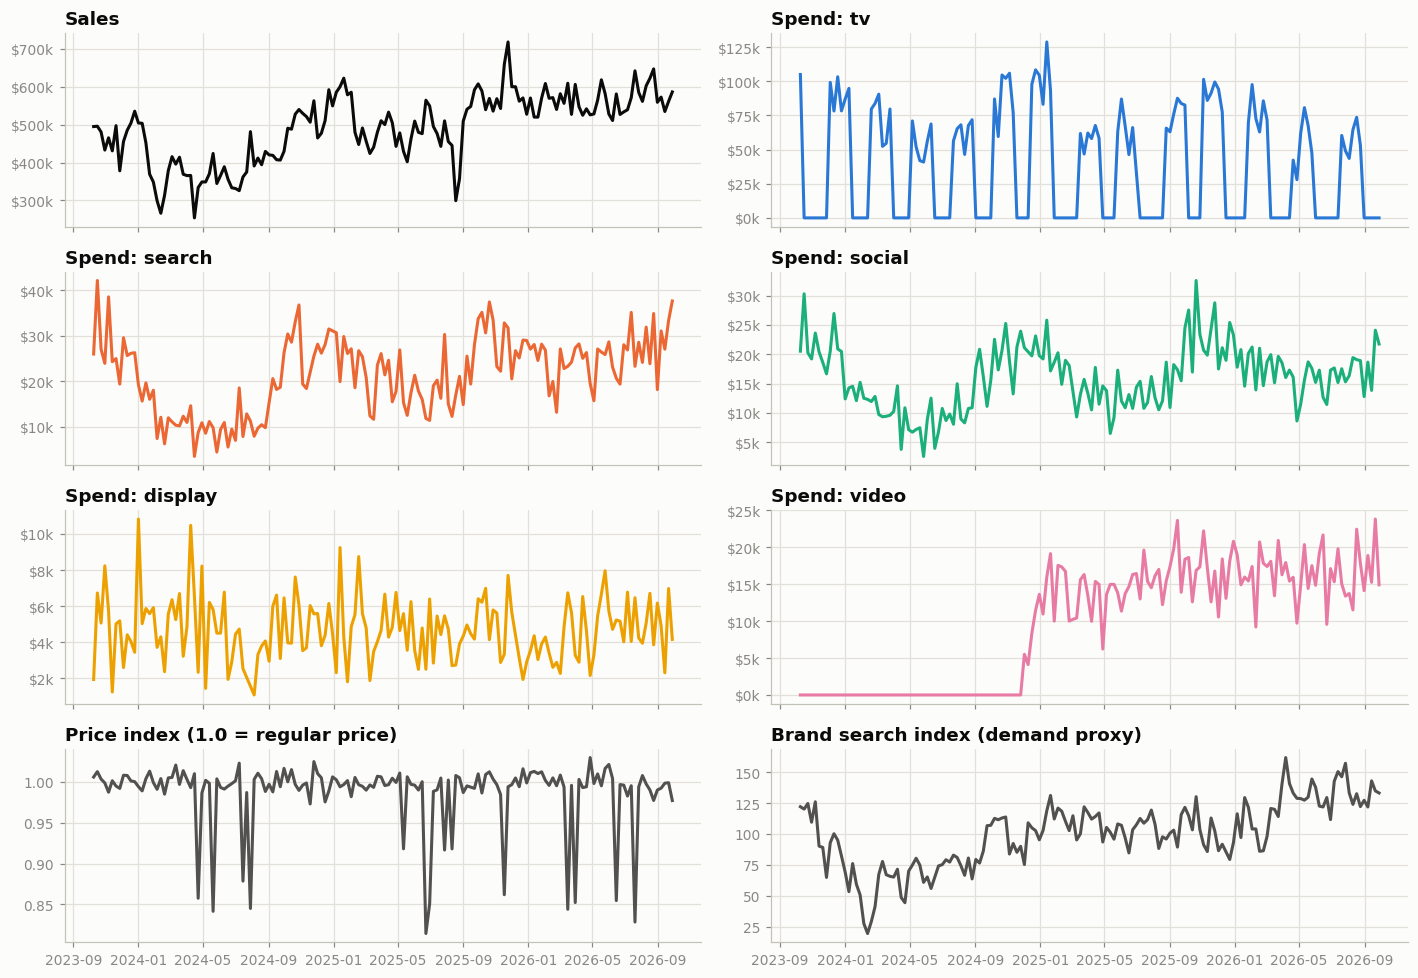

In [18]:
fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
axes = axes.ravel()
axes[0].plot(df["date"], df["sales"], color=INK)
axes[0].set_title("Sales")
thousands(axes[0])
for ax, ch in zip(axes[1:6], CHANNELS):
    ax.plot(df["date"], df[ch], color=CHANNEL_COLOR[ch])
    ax.set_title(f"Spend: {ch}")
    thousands(ax)
axes[6].plot(df["date"], df["price_index"], color=INK_2)
axes[6].set_title("Price index (1.0 = regular price)")
axes[7].plot(df["date"], df["brand_search_index"], color=INK_2)
axes[7].set_title("Brand search index (demand proxy)")
plt.tight_layout()
plt.show()

**Reading the output.**

* **Sales** trend upward, show a yearly pattern with a peak at year-end, sharp spikes (holidays) and a few sharp dips.
* **TV** runs in bursts. That on/off pattern is helpful: weeks without TV show what sales look like without it, almost like a small experiment.
* **Search and social** look alike and both rise towards year-end and over time. Similar-looking series are hard for a model to separate.
* **Video** begins part-way through.
* **Price** has visible promotional dips.

## 5.3 Outliers

We flag weeks where sales deviate strongly from their local level. The local level is a 9-week centred rolling median, and the deviation is scaled by the **MAD** (median absolute deviation), a measure of spread that, unlike the standard deviation, is not itself distorted by outliers. A "robust z-score" beyond about 3.5 is a conventional flag.

In [19]:
local_level = df["sales"].rolling(window=9, center=True, min_periods=5).median()
deviation = df["sales"] - local_level
mad = (deviation - deviation.median()).abs().median()
df["robust_z"] = 0.6745 * (deviation - deviation.median()) / mad   # 0.6745 makes MAD comparable to a std dev

flagged = df.loc[df["robust_z"].abs() > 3.5, ["date", "sales", "robust_z", "price_index"]].copy()
flagged["black_friday"] = flagged["date"].apply(is_black_friday_week)
flagged["christmas"] = flagged["date"].apply(is_christmas_week)
flagged["promo_price"] = flagged["price_index"] < 0.95
flagged.round(2)

,date,sales,robust_z,price_index,black_friday,christmas,promo_price
27,2024-04-15,254109.14,-3.66,1.01,False,False,False
97,2025-08-18,299464.94,-5.11,1.01,False,False,False
98,2025-08-25,357255.37,-4.98,1.00,False,False,False
111,2025-11-24,717957.36,4.84,0.99,True,False,False


**Reading the output and deciding what to do.** Each flagged week needs an explanation before we decide how to treat it.

* **The positive outlier** is a Black Friday week. It is a real, explainable event. We do not remove it; we give the model a variable that explains it (a holiday indicator). The same goes for Christmas weeks and price promotions, which are visible in the sales plot even though they fall below the flagging threshold here.
* **Negative outliers with no holiday and no promotion** are unexplained by anything in our data. On a real project this is where you pick up the phone. Suppose operations confirms that a **warehouse failure caused a two-week stock-out** in the two consecutive August 2025 weeks. Sales were capped by supply, not by demand, so these weeks say nothing about marketing. The standard treatment is an **indicator variable** (1 in those weeks, 0 otherwise), which lets the model absorb the dip without deleting rows and breaking the adstock sequence.

We do not drop or alter any data. The rule: *explain outliers with variables when you can; never delete them silently.*

The remaining flagged week (April 2024) has no confirmed cause. We, as authors, know it is a competitor promotion, but the analyst does not. It stays in the data unexplained and ends up in the noise term. This is the omitted-variable problem of difficulty 11.

In [20]:
# Unexplained negative outliers: no holiday, no promotion.
unexplained = flagged[(flagged["robust_z"] < 0) & ~flagged["black_friday"] & ~flagged["christmas"] & ~flagged["promo_price"]]
# Operations confirmed a stock-out for the two CONSECUTIVE weeks with the deepest drop.
worst = unexplained.sort_values("robust_z").index[0]
stockout_rows = sorted(i for i in unexplained.index if abs(i - worst) <= 1)
print("Weeks flagged as stock-out after checking with operations:")
print(df.loc[stockout_rows, ["date", "sales", "robust_z"]].round(2).to_string(index=False))

# Grading our detective work against the answer key (only possible with synthetic data).
true_stockout_rows = [STOCKOUT_START - L_MAX, STOCKOUT_START - L_MAX + 1]
print(f"\nTrue stock-out rows: {true_stockout_rows}; identified rows: {stockout_rows}")

Weeks flagged as stock-out after checking with operations:
      date     sales  robust_z
2025-08-18 299464.94     -5.11
2025-08-25 357255.37     -4.98

True stock-out rows: [97, 98]; identified rows: [97, 98]


## 5.4 Feature engineering

We now create the model inputs.

* `black_friday`, `christmas`: holiday indicators built from the calendar.
* `stockout`: the indicator for the confirmed supply problem.
* `price_dev`: price relative to regular price (`price_index - 1`). Centring a control on its normal value means the intercept keeps a clean meaning: sales at the regular price.
* `demand_proxy`: the brand search index **standardised** (mean 0, standard deviation 1). PyMC-Marketing does not scale controls automatically, and a variable with values near 100 next to others near 0.1 would make one shared prior on the coefficients fit badly.

In [21]:
df["black_friday"] = df["date"].apply(is_black_friday_week).astype(float)
df["christmas"] = df["date"].apply(is_christmas_week).astype(float)
df["stockout"] = 0.0
df.loc[stockout_rows, "stockout"] = 1.0
df["price_dev"] = df["price_index"] - 1.0

# Train/test split by time: the last 13 weeks (one quarter) are held out to test forecasts.
N_TEST: int = 13
N_TRAIN: int = len(df) - N_TEST
train_df, test_df = df.iloc[:N_TRAIN].copy(), df.iloc[N_TRAIN:].copy()

# Standardise the demand proxy using TRAINING statistics only. Using the full sample would let
# information from the test period leak into the model inputs ("data leakage").
proxy_mean, proxy_sd = train_df["brand_search_index"].mean(), train_df["brand_search_index"].std()
for frame in (df, train_df, test_df):
    frame["demand_proxy"] = (frame["brand_search_index"] - proxy_mean) / proxy_sd

print(f"Training: {train_df['date'].min():%Y-%m-%d} to {train_df['date'].max():%Y-%m-%d}  ({len(train_df)} weeks)")
print(f"Test    : {test_df['date'].min():%Y-%m-%d} to {test_df['date'].max():%Y-%m-%d}  ({len(test_df)} weeks)")
print(f"Holiday weeks in training: Black Friday {int(train_df['black_friday'].sum())}, Christmas {int(train_df['christmas'].sum())}")

Training: 2023-10-09 to 2026-06-29  (143 weeks)
Test    : 2026-07-06 to 2026-09-28  (13 weeks)
Holiday weeks in training: Black Friday 3, Christmas 3


**Why split by time?** With time series you must never shuffle rows into training and test sets: that would let the model use the future to predict the past. We hold out the final quarter, fit on everything before it, and later ask the model to forecast the held-out weeks. This checks whether the model has learned something that generalises or has merely memorised the training period (**overfitting**).

## 5.5 How much of the budget goes where

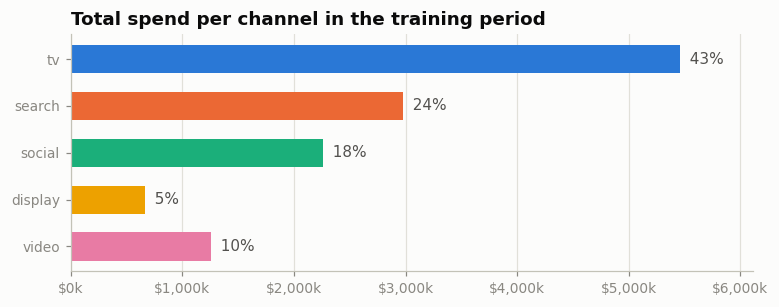

In [22]:
spend_tot = train_df[CHANNELS].sum()
SPEND_SHARE = (spend_tot / spend_tot.sum()).to_numpy()

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(CHANNELS[::-1], spend_tot.to_numpy()[::-1], color=[CHANNEL_COLOR[c] for c in CHANNELS[::-1]], height=0.6)
for bar, share in zip(bars, SPEND_SHARE[::-1]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {share:.0%}", va="center", color=INK_2)
ax.set(title="Total spend per channel in the training period", xlim=(0, spend_tot.max() * 1.12))
thousands(ax, "x")
ax.grid(axis="y", visible=False)
plt.show()

## 5.6 Correlation and multicollinearity

**Multicollinearity** means that some explanatory variables are strongly correlated with each other. A regression then cannot tell their effects apart: it knows the *sum* of their effects well and the *split* badly. The usual measure is the **variance inflation factor (VIF)**. For each variable, regress it on all the others and take $\text{VIF} = 1/(1-R^2)$. A VIF of 1 means the variable is unrelated to the rest; above 5 is a common warning level and above 10 is serious.

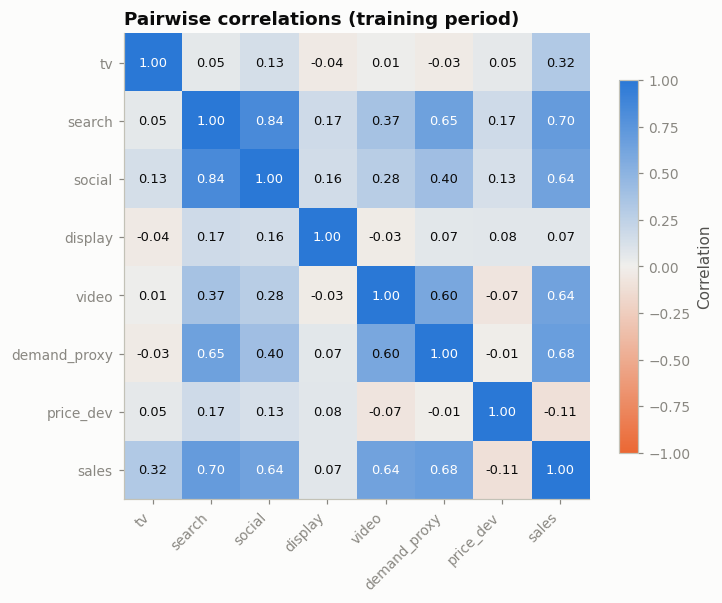

,tv,search,social,display,video,demand_proxy,price_dev
VIF,1.04,5.82,3.93,1.05,1.6,2.7,1.07


In [23]:
corr_cols = CHANNELS + ["demand_proxy", "price_dev", "sales"]
corr = train_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
# Diverging colour scale: orange for negative, grey at zero, blue for positive.
cmap = mpl.colors.LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else INK)
ax.grid(False)
ax.set_title("Pairwise correlations (training period)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation")
plt.show()

# VIF among the predictors (a constant column is added, as the VIF formula requires).
vif_X = sm.add_constant(train_df[CHANNELS + ["demand_proxy", "price_dev"]])
vif = pd.Series(
    [variance_inflation_factor(vif_X.to_numpy(), i) for i in range(1, vif_X.shape[1])],
    index=vif_X.columns[1:], name="VIF",
)
vif.round(2).to_frame().T

**Reading the output.**

* **Search and social are correlated at about 0.8.** Their VIFs are the highest in the table. Expect the model to be unsure how to split credit between them: wide, negatively related posteriors.
* **Search is strongly correlated with the demand proxy.** This is the fingerprint of confounding: search budgets follow demand. If we leave demand out, search will absorb its effect.
* **Sales correlate with search at about 0.7 and with TV at only about 0.3.** A naive reading says "search drives sales, TV barely matters". We know from the answer key that TV is the largest contributor. Raw correlations are not contributions.
* **TV is nearly uncorrelated with everything else**, thanks to flighting. That independence is what makes it measurable.

## 5.7 A baseline to beat: ordinary least squares

Before the Bayesian models, here is what the simplest possible analysis says: a linear regression of sales on raw spend and the controls, with no adstock and no saturation. A simple baseline tells us what the sophisticated model must improve on.

**Assumptions of OLS, stated explicitly:** (1) the relationship is linear in spend; (2) *exogeneity*: no omitted variable is correlated with both spend and sales; (3) errors are uncorrelated across weeks; (4) errors have constant variance (*homoscedasticity*). We already have reasons to doubt (1) and (2). We report **HAC (Newey-West) standard errors**, which remain valid when the errors are autocorrelated or have non-constant variance, as is normal for weekly time series; plain OLS standard errors would be too small.

In [24]:
ols_controls = ["price_dev", "black_friday", "christmas", "stockout"]
ols_X = sm.add_constant(train_df[CHANNELS + ols_controls].assign(t=np.arange(N_TRAIN) / N_TRAIN))
ols = sm.OLS(train_df["sales"], ols_X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

# In a linear model the coefficient on spend IS the estimated return per dollar.
ci = ols.conf_int(alpha=0.05)   # 95% confidence interval
# Answer key for the TRAINING window: true contribution divided by true spend.
TRUE_CONTRIB_TRAIN = truth[media_cols].iloc[:N_TRAIN].sum().to_numpy()
TRUE_SPEND_TRAIN = gen_df[CHANNELS].to_numpy()[obs][:N_TRAIN].sum(axis=0)
TRUE_ROAS = TRUE_CONTRIB_TRAIN / TRUE_SPEND_TRAIN

ols_table = pd.DataFrame({
    "OLS return per $": ols.params[CHANNELS],
    "HAC std. error": ols.bse[CHANNELS],
    "95% CI low": ci.loc[CHANNELS, 0],
    "95% CI high": ci.loc[CHANNELS, 1],
    "p-value": ols.pvalues[CHANNELS],
    "TRUE ROAS": TRUE_ROAS,
})
display(ols_table.round(3))

ols_resid = ols.resid
bp_stat, bp_p, _, _ = het_breuschpagan(ols_resid, ols_X)
print(f"R-squared: {ols.rsquared:.3f}")
print(f"Durbin-Watson: {durbin_watson(ols_resid):.2f}   (2 = no autocorrelation; well below 2 = positive autocorrelation)")
print(f"Breusch-Pagan test for non-constant variance: statistic {bp_stat:.1f}, p-value {bp_p:.3f}")

,OLS return per $,HAC std. error,95% CI low,95% CI high,p-value,TRUE ROAS
tv,0.648,0.060,0.530,0.765,0.000,1.414
search,4.105,0.716,2.702,5.507,0.000,2.482
social,2.383,0.862,0.693,4.074,0.006,1.169
display,0.618,1.724,-2.761,3.998,0.720,0.398
video,1.266,0.922,-0.541,3.072,0.170,1.816


R-squared: 0.881
Durbin-Watson: 1.13   (2 = no autocorrelation; well below 2 = positive autocorrelation)
Breusch-Pagan test for non-constant variance: statistic 11.0, p-value 0.360


**Reading the output.** The simple regression fits well by the usual yardstick (R-squared near 0.88) and gets the answer wrong.

* **TV is underestimated by more than half** (about 0.65 against a true 1.41). TV's effect is spread over later weeks by carry-over; a model that only looks at the same week misses most of it.
* **Search and social are overestimated** (about 4.1 and 2.4 against true values of 2.5 and 1.2). Both follow demand and season, so they collect credit that belongs to the baseline.
* **Display and video** have confidence intervals that include zero: the data cannot pin them down.
* **Durbin-Watson is about 1.1**, well below 2. The residuals are positively autocorrelated, which means the model is missing time structure (carry-over, seasonality). The Breusch-Pagan test does not reject constant variance (p-value about 0.36).

A good fit is not evidence of correct attribution. This is the single most important idea in MMM, and it is why we now build a model with the right structure.

---
# Part VI. The MMM in PyMC-Marketing

## 6.1 What we are about to build

PyMC-Marketing's `MMM` class assembles the model of Section 3.4 from components. We choose:

| Component | Choice | Reason |
|---|---|---|
| Adstock | `GeometricAdstock(l_max=8)` | Standard; 8 weeks covers the plausible carry-over of weekly media |
| Saturation | `LogisticSaturation()` | The library default; one shape parameter per channel |
| Seasonality | `yearly_seasonality=2` | Two Fourier modes: smooth yearly pattern without overfitting |
| Trend | `LinearTrendEffect` with 6 changepoints | A piecewise-linear trend that can bend, since growth need not be constant |
| Controls | price, holidays, stock-out, (later) demand proxy | From the EDA |
| Likelihood | Normal | Weekly sales are large numbers with roughly symmetric noise |

**Model assumptions, stated explicitly.** (1) Effects are *additive*: channels do not amplify each other. (2) Each channel's response follows geometric decay and a logistic curve whose parameters are constant over time. (3) *No unobserved confounding*: after conditioning on the controls, trend and seasonality, variation in spend is unrelated to anything else that moves sales. This is the assumption that turns a correlation into a causal claim, and it is the one most likely to fail. (4) Noise is Normal, independent across weeks, with constant variance. We test what can be tested (4, and the fit) and stress assumption (3) deliberately in Section 6.6.

## 6.2 Choosing priors

Recall that sales and spend are both divided by their maxima, so parameters live on a 0-to-1 scale. Here are the priors and the reasoning for each.

| Parameter | Prior | Plain-language meaning |
|---|---|---|
| `intercept` | Normal(0.5, 0.25) | Baseline sales are probably between 0 and 100% of peak sales, most likely around half |
| `adstock_alpha` | Beta(1, 3) | Retention is between 0 and 1, more likely low (mean 0.25) but high values are possible |
| `saturation_lam` | Gamma(3, 1) | Curvature is positive, centred around 2 to 3: clearly bending within the observed spend range |
| `saturation_beta` | HalfNormal(sigma proportional to spend share) | Effects are **non-negative**; a channel with more budget can plausibly contribute more |
| `gamma_control` | Normal(0, 0.3) | Controls can push sales up or down |
| `gamma_fourier` | Laplace(0, 0.1) | Seasonal waves are probably small; the pointed Laplace shape shrinks unneeded waves towards zero |
| trend `delta` | Laplace(0, 0.1) | Most changepoints should do nothing; a few may bend the trend |
| noise `sigma` | HalfNormal(0.2) | Weekly noise is positive and probably well under 20% of peak sales |

Two of these carry real modelling weight.

**The HalfNormal on `saturation_beta` encodes "advertising does not reduce sales".** This is a strong assumption and a sensible one: it stops the model from assigning a negative effect to one of two correlated channels just to offset the other.

**Scaling the prior by spend share** is a practice recommended by PyMC Labs. Without it, every channel gets the same prior on its maximum contribution, which implies that a \$5k-a-week channel could matter as much as a \$40k-a-week one. Scaling the prior width by spend share says "expect contribution to be roughly in proportion to budget, unless the data says otherwise", which amounts to a prior belief that ROAS is similar across channels.

In [25]:
BASE_CONTROLS: list[str] = ["price_dev", "black_friday", "christmas", "stockout"]
MCMC_VARS: list[str] = ["intercept_contribution", "adstock_alpha", "saturation_lam", "saturation_beta",
                        "gamma_control", "gamma_fourier", "delta", "y_sigma"]
SAMPLER: dict = {"chains": 4, "cores": 4, "tune": 1_000, "draws": 1_000, "target_accept": 0.9}


def make_pymc_mmm(control_cols: list[str], beta_prior_width: float = 0.15) -> MMM:
    """Create an (unfitted) PyMC-Marketing MMM with the priors discussed in Section 6.2.

    `beta_prior_width` scales the prior on each channel's maximum contribution; it is exposed
    so that we can test how sensitive the results are to this choice (Section 6.10).
    """
    n_channels = len(CHANNELS)
    model_config = {
        "intercept": Prior("Normal", mu=0.5, sigma=0.25),
        "adstock_alpha": Prior("Beta", alpha=1, beta=3, dims="channel"),
        "saturation_lam": Prior("Gamma", alpha=3, beta=1, dims="channel"),
        # Wider prior for channels with a larger share of the budget.
        "saturation_beta": Prior("HalfNormal", sigma=beta_prior_width * n_channels * SPEND_SHARE, dims="channel"),
        "gamma_control": Prior("Normal", mu=0, sigma=0.3, dims="control"),
        "gamma_fourier": Prior("Laplace", mu=0, b=0.1, dims="fourier_mode"),
        "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
    }
    mmm = MMM(
        date_column="date",
        target_column="sales",
        channel_columns=CHANNELS,
        control_columns=control_cols,
        adstock=GeometricAdstock(l_max=L_MAX),
        saturation=LogisticSaturation(),
        yearly_seasonality=2,
        model_config=model_config,
    )
    # A piecewise-linear trend: 6 evenly spaced points where the slope is allowed to change.
    trend = LinearTrend(n_changepoints=6, priors={"delta": Prior("Laplace", mu=0, b=0.1, dims="changepoint")})
    mmm.add_mu_effect(LinearTrendEffect(trend=trend, prefix="trend"))
    return mmm


def fit_pymc_mmm(control_cols: list[str], lift_tests: pd.DataFrame | None = None,
                 beta_prior_width: float = 0.15) -> tuple[MMM, float]:
    """Build, optionally calibrate, and fit the MMM on the training data. Returns (model, seconds)."""
    mmm = make_pymc_mmm(control_cols, beta_prior_width)
    X, y = train_df[["date"] + CHANNELS + control_cols], train_df["sales"]
    mmm.build_model(X, y)
    # Ask for each component's contribution in dollars, not only on the internal 0-1 scale.
    mmm.add_original_scale_contribution_variable(var=[
        "channel_contribution", "control_contribution", "intercept_contribution",
        "yearly_seasonality_contribution", "trend_effect_contribution",
    ])
    if lift_tests is not None:
        mmm.add_lift_test_measurements(lift_tests)
    started = time.perf_counter()
    mmm.fit(X, y, random_seed=SEED, progressbar=False, **SAMPLER)
    seconds = time.perf_counter() - started
    # Simulate sales from the fitted model for the training weeks (posterior predictive).
    mmm.sample_posterior_predictive(X, extend_idata=True, random_seed=SEED, progressbar=False)
    return mmm, seconds

## 6.3 Prior predictive check

Before fitting, we ask what the priors alone imply. We draw 500 parameter sets from the priors and simulate a sales series from each. If the simulated range does not comfortably contain the real data, or if it is absurdly wide, the priors need another look.

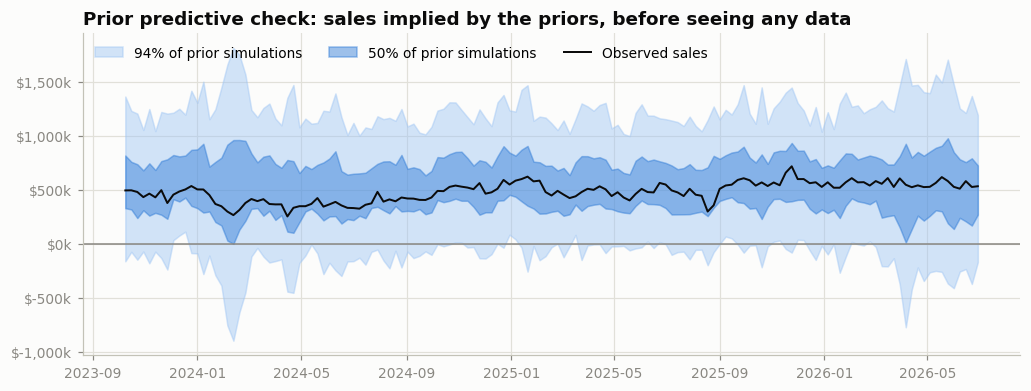

Share of prior-simulated weekly sales below zero: 6.7%


In [26]:
prior_model = make_pymc_mmm(BASE_CONTROLS + ["demand_proxy"])
X_train_full = train_df[["date"] + CHANNELS + BASE_CONTROLS + ["demand_proxy"]]
prior_model.build_model(X_train_full, train_df["sales"])
prior_model.sample_prior_predictive(X_train_full, train_df["sales"], samples=500, random_seed=SEED)

target_scale_prior = float(prior_model.get_scales_as_xarray()["target_scale"])
prior_sales = prior_model.idata.prior_predictive["y"].stack(sample=("chain", "draw")) * target_scale_prior

fig, ax = plt.subplots(figsize=(11, 3.8))
q = prior_sales.quantile([0.03, 0.25, 0.75, 0.97], dim="sample")
ax.fill_between(train_df["date"], q.sel(quantile=0.03), q.sel(quantile=0.97), color=BLUE_LIGHT, alpha=0.45, label="94% of prior simulations")
ax.fill_between(train_df["date"], q.sel(quantile=0.25), q.sel(quantile=0.75), color=BLUE, alpha=0.45, label="50% of prior simulations")
ax.plot(train_df["date"], train_df["sales"], color=INK, linewidth=1.3, label="Observed sales")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set(title="Prior predictive check: sales implied by the priors, before seeing any data")
thousands(ax)
ax.legend(ncol=3, loc="upper left")
plt.show()

share_negative = float((prior_sales < 0).mean())
print(f"Share of prior-simulated weekly sales below zero: {share_negative:.1%}")

**Reading the output.** The observed series (black) lies inside the band of prior simulations, and the band is wide: the priors allow weekly sales anywhere from around zero to several times the observed level. That is what we want from *weakly informative* priors. They rule out the absurd (sales fifty times the peak) while leaving the data free to decide. The spikes in the band at holiday and stock-out weeks appear because the prior lets each indicator push sales up or down by a large amount.

A few percent of simulated values are negative, which is impossible for sales. This is a known cost of a Normal likelihood with an additive model, and it is harmless here because the data pulls the posterior far away from that region.

A prior predictive check is also how you catch priors that are too loose. A first draft of this notebook used a prior on channel effects almost three times wider; the simulated sales were then centred at about twice the observed level, which is how we knew to tighten it.

## 6.4 Model M0: the naive model

We start with a model that an analyst might reasonably build first: media, price, holidays, the stock-out indicator, seasonality and trend. It does **not** include the demand proxy. We fit it on purpose, to see what confounding looks like from the inside.

`mmm.fit` runs the NUTS sampler: 4 chains, each with 1,000 warm-up steps (during which the sampler tunes itself) and 1,000 kept draws, giving 4,000 posterior samples. `target_accept=0.9` makes the sampler take smaller, more careful steps than the default of 0.8, which reduces divergences in models with curved posteriors like this one.

In [27]:
mmm_m0, seconds_m0 = fit_pymc_mmm(BASE_CONTROLS)
print(f"M0 fitted in {seconds_m0:.0f} seconds. Posterior draws: "
      f"{mmm_m0.idata.posterior.sizes['chain']} chains x {mmm_m0.idata.posterior.sizes['draw']} draws")

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


M0 fitted in 91 seconds. Posterior draws: 4 chains x 1000 draws


## 6.5 Convergence diagnostics

Before reading any result, check the sampler (Section 2.4).

In [28]:
def mcmc_health(mmm: MMM) -> dict[str, float]:
    """Headline convergence numbers for a fitted PyMC model."""
    summary = az.summary(mmm.idata, var_names=MCMC_VARS)
    return {
        "max r_hat": float(summary["r_hat"].max()),
        "min ess_bulk": float(summary["ess_bulk"].min()),
        "min ess_tail": float(summary["ess_tail"].min()),
        "divergences": int(mmm.idata.sample_stats["diverging"].sum()),
    }


print("M0 convergence:", mcmc_health(mmm_m0))
az.summary(mmm_m0.idata, var_names=["adstock_alpha", "saturation_lam", "saturation_beta", "y_sigma"], hdi_prob=0.94).round(3)

M0 convergence: {'max r_hat': 1.01, 'min ess_bulk': 1711.0, 'min ess_tail': 1243.0, 'divergences': 1}


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
adstock_alpha[tv],0.574,0.034,0.512,0.636,0.001,0.000,4019.0,2580.0,1.0
adstock_alpha[search],0.191,0.072,0.053,0.324,0.002,0.001,1711.0,1243.0,1.0
adstock_alpha[social],0.236,0.172,0.000,0.540,0.002,0.002,3617.0,2020.0,1.0
adstock_alpha[display],0.238,0.184,0.000,0.576,0.002,0.002,4690.0,1941.0,1.0
adstock_alpha[video],0.410,0.224,0.002,0.761,0.004,0.003,3466.0,2102.0,1.0
saturation_lam[tv],1.971,0.720,0.670,3.275,0.016,0.011,1895.0,2326.0,1.0
saturation_lam[search],2.962,0.581,1.852,4.042,0.010,0.007,3083.0,2274.0,1.0
saturation_lam[social],2.339,1.479,0.273,5.042,0.021,0.017,5102.0,2935.0,1.0
saturation_lam[display],2.578,1.787,0.157,5.839,0.023,0.019,5135.0,2627.0,1.0
saturation_lam[video],3.768,1.750,0.849,7.040,0.028,0.020,3005.0,1778.0,1.0


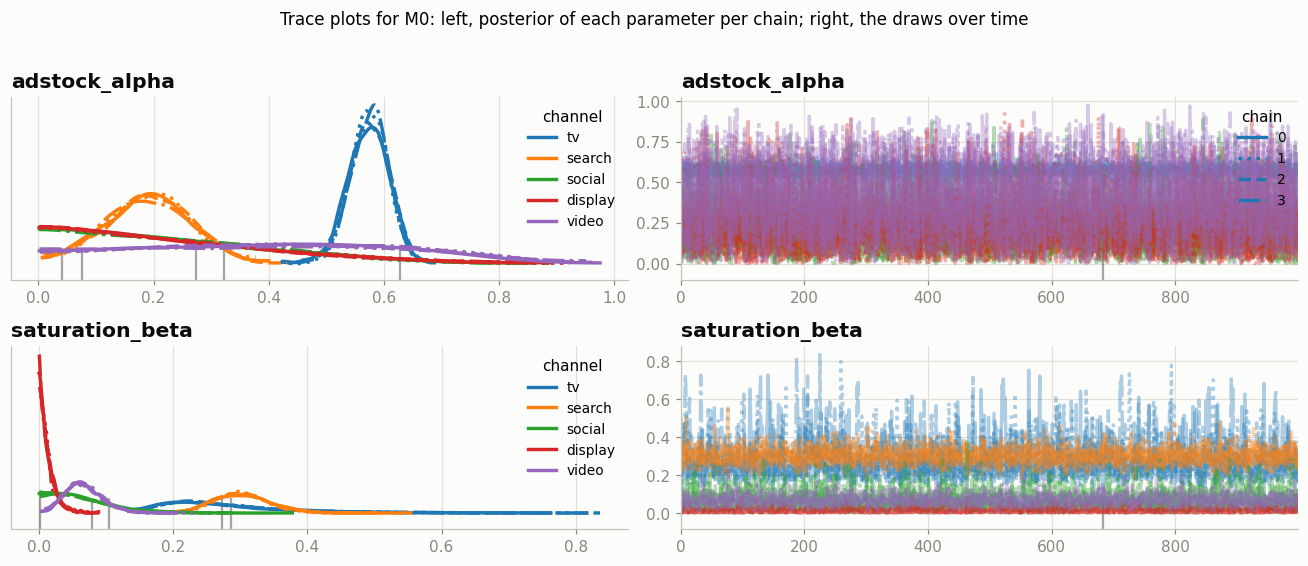

In [29]:
axes = az.plot_trace(mmm_m0.idata, var_names=["adstock_alpha", "saturation_beta"], compact=True, legend=True, figsize=(12, 5))
plt.suptitle("Trace plots for M0: left, posterior of each parameter per chain; right, the draws over time", y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

**Reading the output.**

* `max r_hat` is 1.00 to 1.01: the four chains agree.
* The smallest effective sample size is above 1,000, comfortably above the 400 guideline.
* There is at most a single divergence among 4,000 draws. One or two isolated divergences are tolerable; dozens, or divergences concentrated in one region, would not be.
* In the trace plot, colours are channels and line styles are chains. Each channel's four chain-wise distributions (left) lie on top of each other, and the traces (right) are stationary fuzzy bands with no drift.

The sampler has done its job. Note carefully what this does and does not mean. **Convergence tells you that the computer has correctly computed the posterior of the model you wrote. It says nothing about whether the model you wrote is right.** M0 has converged perfectly and, as we are about to see, is badly wrong about one channel.

## 6.6 What M0 says, and why it is wrong

ROAS for a channel is its total contribution divided by its total spend. We compute it for every posterior draw, which gives a full posterior distribution of ROAS, and compare the result with the answer key.

,true,median,hdi_3%,hdi_97%,truth inside interval
tv,1.41,1.26,1.09,1.45,True
search,2.48,6.04,4.41,7.81,False
social,1.17,0.94,0.00,2.50,True
display,0.40,0.52,0.00,1.92,True
video,1.82,2.28,0.60,4.09,True


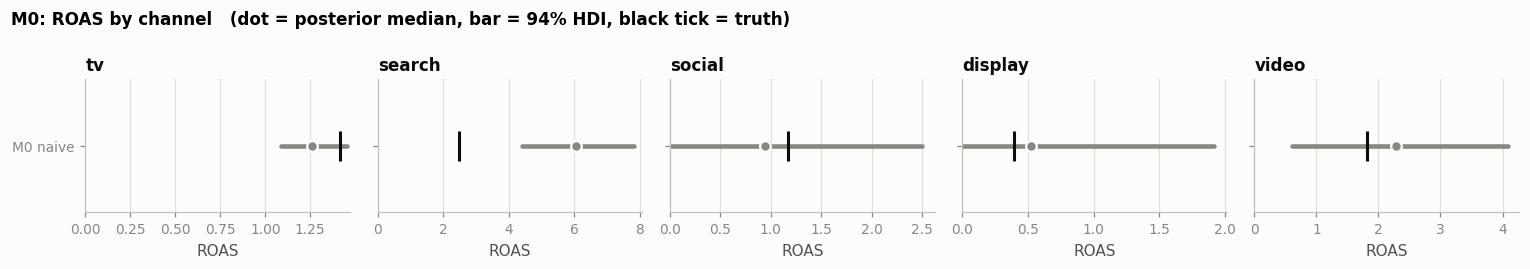

In [30]:
ROAS_DRAWS: dict[str, np.ndarray] = {}        # model label -> array of shape (draws, channels)
CONTRIB_DRAWS: dict[str, np.ndarray] = {}     # model label -> array of shape (draws, weeks, channels)
ROAS_TRUTH: dict[str, np.ndarray] = {}        # model label -> true ROAS of the dataset that model was fitted to
TOTAL_SALES: dict[str, float] = {}            # model label -> total training-period sales of that dataset
spend_train = train_df[CHANNELS].sum().to_numpy()


def store_pymc_results(label: str, mmm: MMM) -> None:
    """Extract per-draw channel contributions (dollars) and ROAS from a fitted PyMC model."""
    contrib = (mmm.idata.posterior["channel_contribution_original_scale"]
               .stack(sample=("chain", "draw")).transpose("sample", "date", "channel").to_numpy())
    CONTRIB_DRAWS[label] = contrib
    ROAS_DRAWS[label] = contrib.sum(axis=1) / spend_train
    ROAS_TRUTH[label] = TRUE_ROAS
    TOTAL_SALES[label] = float(train_df["sales"].sum())


def roas_table(label: str) -> pd.DataFrame:
    """Posterior median and 94% HDI of ROAS per channel, next to the true value."""
    draws = ROAS_DRAWS[label]
    hdi = np.array([az.hdi(draws[:, j], hdi_prob=0.94) for j in range(draws.shape[1])])
    table = pd.DataFrame({"true": ROAS_TRUTH[label], "median": np.median(draws, axis=0),
                          "hdi_3%": hdi[:, 0], "hdi_97%": hdi[:, 1]}, index=CHANNELS)
    table["truth inside interval"] = (table["true"] >= table["hdi_3%"]) & (table["true"] <= table["hdi_97%"])
    return table


def plot_roas(labels: list[str], colors: list[str], title: str) -> None:
    """One panel per channel: each model's ROAS interval, with the true value for its dataset as a black tick."""
    fig, axes = plt.subplots(1, len(CHANNELS), figsize=(14, 0.55 * len(labels) + 1.9), sharey=True)
    for ax, (j, ch) in zip(axes, enumerate(CHANNELS)):
        for row, (label, color) in enumerate(zip(labels, colors)):
            draws = ROAS_DRAWS[label][:, j]
            lo, hi = az.hdi(draws, hdi_prob=0.94)
            ax.plot([lo, hi], [row, row], color=color, linewidth=3, solid_capstyle="round")
            ax.plot(np.median(draws), row, "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
            ax.plot(ROAS_TRUTH[label][j], row, "|", color=INK, markersize=20, markeredgewidth=2)
        ax.set_title(ch, fontsize=11)
        ax.set_xlim(left=0)
        ax.set_yticks(range(len(labels)), labels)
        ax.set_ylim(len(labels) - 0.5, -0.5)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("ROAS")
    fig.suptitle(title + "   (dot = posterior median, bar = 94% HDI, black tick = truth)", x=0.01, ha="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()


store_pymc_results("M0 naive", mmm_m0)
display(roas_table("M0 naive").round(2))
plot_roas(["M0 naive"], [MUTED], "M0: ROAS by channel")

**Reading the output.** TV, social, display and video are in reasonable agreement with the truth: their intervals contain the true value. **Search is not.** M0 puts search ROAS at roughly 6, with an interval that excludes the true value of about 2.5. The model is confident and wrong.

The mechanism is the confounding of Section 1.2:

1. Hidden market demand rises.
2. People search more, so the search budget (which is tied to search volume) rises.
3. The same demand produces more sales *directly*, with or without advertising.
4. M0 has no variable for demand. The only input that moved together with those extra sales is search spend, so search gets the credit.

Statisticians call this **omitted-variable bias**. A budget optimiser fed with M0 would shift a large share of the budget into search and the company would lose money.

Nothing in M0's own diagnostics reveals the problem: R-hat is fine and, as the next cell shows, the fit is good. Detecting confounding takes subject knowledge (search budgets follow demand: this is well known) or an experiment.

## 6.7 Model M1: adding a demand control

The textbook remedy for a confounder is to **condition on it**: include it in the model. We cannot observe demand itself, but we have a proxy, the brand search index. Google's own MMM guidance makes the same recommendation: include query volume as a control when modelling paid search.

M1 fitted in 98 seconds.  Convergence: {'max r_hat': 1.0, 'min ess_bulk': 1656.0, 'min ess_tail': 1383.0, 'divergences': 0}


,true,median,hdi_3%,hdi_97%,truth inside interval
tv,1.41,1.36,1.20,1.54,True
search,2.48,2.23,0.95,3.79,True
social,1.17,1.30,0.04,2.83,True
display,0.40,0.61,0.00,1.98,True
video,1.82,1.20,0.04,2.40,True


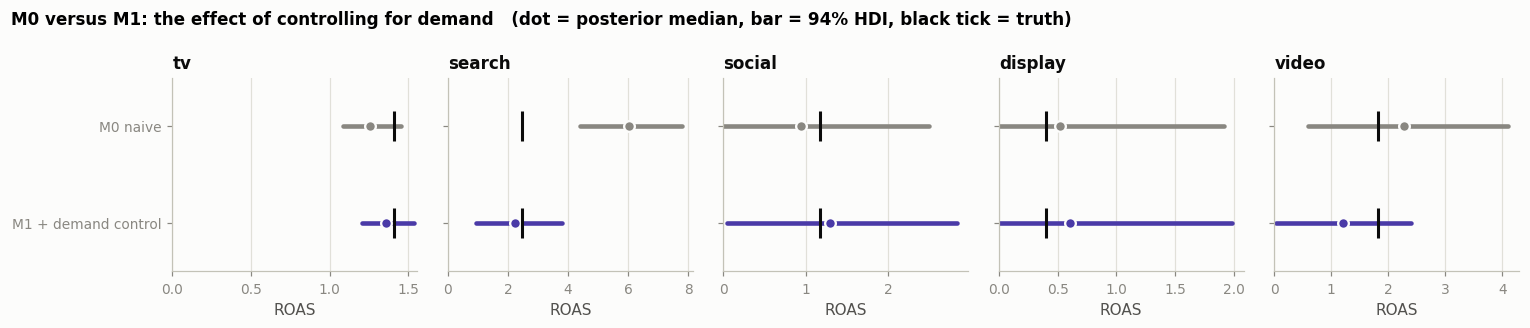

In [31]:
M1_CONTROLS: list[str] = BASE_CONTROLS + ["demand_proxy"]
mmm_m1, seconds_m1 = fit_pymc_mmm(M1_CONTROLS)
store_pymc_results("M1 + demand control", mmm_m1)

print(f"M1 fitted in {seconds_m1:.0f} seconds.  Convergence: {mcmc_health(mmm_m1)}")
display(roas_table("M1 + demand control").round(2))
plot_roas(["M0 naive", "M1 + demand control"], [MUTED, PYMC_COLOR], "M0 versus M1: the effect of controlling for demand")

**Reading the output.** With the demand proxy included, search ROAS falls from about 6 to about 2.2, and the interval now contains the true 2.5. One extra column changed the headline conclusion of the study. TV and social move little. Video's median also falls, from about 2.3 to 1.2: video launched during a period of rising demand, so it too had been collecting some of demand's credit.

Look also at the **width** of the intervals. TV is narrow: its on/off flighting gives the model clean information. Search and social are wide because they move together (multicollinearity). Display is very wide relative to its value: the model is saying, correctly, that it cannot measure a channel this small. A wide interval is not a failure of the model. It is an honest report of what the data can and cannot tell us.

### Fit quality: in-sample and out-of-sample

We now check how well M0 and M1 reproduce sales, both on the training weeks and on the 13 held-out weeks that neither model has seen. Three metrics:

* **R-squared**: share of the variance in sales explained (1 is perfect).
* **MAPE**, mean absolute percentage error: the typical size of the error as a percentage of sales.
* **Coverage**: the share of weeks whose actual sales fall inside the model's 94% predictive interval. A well-calibrated model should score near 94%. Much lower means the model is overconfident.

,train R2,train MAPE,train coverage,test R2,test MAPE,test coverage
M0 naive,0.952,3.3%,97%,0.869,1.8%,100%
M1 + demand control,0.972,2.5%,97%,0.766,2.3%,92%


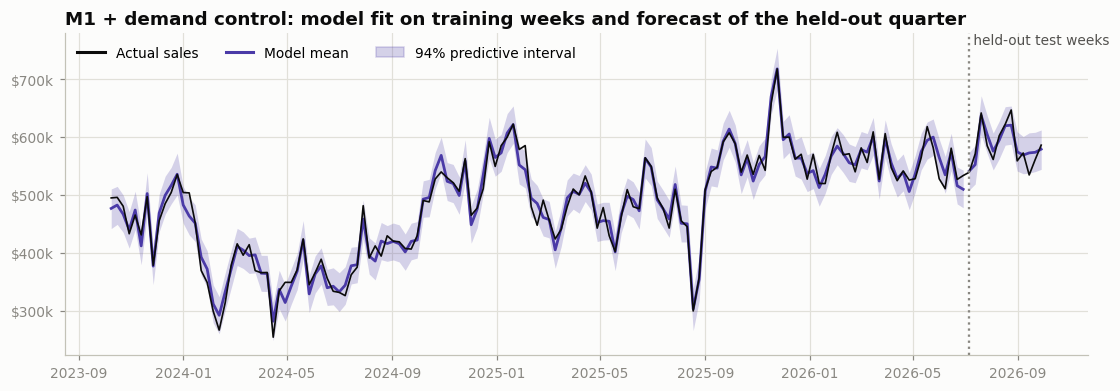

In [32]:
def pymc_predictions(mmm: MMM, control_cols: list[str]) -> dict[str, np.ndarray]:
    """Posterior predictive sales in dollars for the training and test weeks: arrays (weeks, samples)."""
    scale = float(mmm.get_scales_as_xarray()["target_scale"])
    in_sample = mmm.idata.posterior_predictive["y"].stack(sample=("chain", "draw")).transpose("date", "sample").to_numpy() * scale
    # For the test weeks the model needs the last weeks of training spend to compute carry-over;
    # `include_last_observations=True` supplies them and then drops them from the output.
    X_test = test_df[["date"] + CHANNELS + control_cols]
    out = mmm.sample_posterior_predictive(X_test, extend_idata=False, include_last_observations=True, random_seed=SEED,
                                          progressbar=False)
    return {"train": in_sample, "test": out["y"].transpose("date", "sample").to_numpy() * scale}


def fit_metrics(actual: np.ndarray, predictive: np.ndarray) -> dict[str, float]:
    """R-squared, MAPE and 94% interval coverage for one set of weeks."""
    mean = predictive.mean(axis=1)
    lo, hi = np.quantile(predictive, [0.03, 0.97], axis=1)
    ss_res, ss_tot = ((actual - mean) ** 2).sum(), ((actual - actual.mean()) ** 2).sum()
    return {"R2": 1 - ss_res / ss_tot, "MAPE": float(np.mean(np.abs(actual - mean) / actual)),
            "coverage_94": float(np.mean((actual >= lo) & (actual <= hi)))}


PREDICTIONS: dict[str, dict[str, np.ndarray]] = {}
ACTUALS: dict[str, dict[str, np.ndarray]] = {}
FIT_ROWS: dict[str, dict[str, float]] = {}


def record_fit(label: str, preds: dict[str, np.ndarray], actual_train: np.ndarray | None = None,
               actual_test: np.ndarray | None = None) -> None:
    """Store predictions and compute train/test metrics for a model.

    The actual sales default to the national dataset; a model fitted to another dataset passes its own.
    """
    PREDICTIONS[label] = preds
    ACTUALS[label] = {
        "train": train_df["sales"].to_numpy() if actual_train is None else np.asarray(actual_train),
        "test": test_df["sales"].to_numpy() if actual_test is None else np.asarray(actual_test),
    }
    tr = fit_metrics(ACTUALS[label]["train"], preds["train"])
    te = fit_metrics(ACTUALS[label]["test"], preds["test"])
    FIT_ROWS[label] = {"train R2": tr["R2"], "train MAPE": tr["MAPE"], "train coverage": tr["coverage_94"],
                       "test R2": te["R2"], "test MAPE": te["MAPE"], "test coverage": te["coverage_94"]}


record_fit("M0 naive", pymc_predictions(mmm_m0, BASE_CONTROLS))
record_fit("M1 + demand control", pymc_predictions(mmm_m1, M1_CONTROLS))
fit_fmt = {"train R2": "{:.3f}", "test R2": "{:.3f}", "train MAPE": "{:.1%}", "test MAPE": "{:.1%}",
           "train coverage": "{:.0%}", "test coverage": "{:.0%}"}
display(pd.DataFrame(FIT_ROWS).T.style.format(fit_fmt))


def plot_fit(label: str, color: str) -> None:
    """Actual sales against the model's posterior predictive mean and 94% interval."""
    preds = PREDICTIONS[label]
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for frame, key in ((train_df, "train"), (test_df, "test")):
        lo, hi = np.quantile(preds[key], [0.03, 0.97], axis=1)
        ax.fill_between(frame["date"], lo, hi, color=color, alpha=0.22, linewidth=0)
        ax.plot(frame["date"], preds[key].mean(axis=1), color=color, linewidth=1.8)
    ax.plot(df["date"], np.concatenate([ACTUALS[label]["train"], ACTUALS[label]["test"]]), color=INK, linewidth=1.1)
    ax.axvline(test_df["date"].iloc[0], color=MUTED, linestyle=":", linewidth=1.5)
    ax.text(test_df["date"].iloc[0], ax.get_ylim()[1], " held-out test weeks", va="top", color=INK_2, fontsize=9)
    ax.plot([], [], color=INK, label="Actual sales")
    ax.plot([], [], color=color, label="Model mean")
    ax.fill_between([], [], [], color=color, alpha=0.22, label="94% predictive interval")
    ax.set(title=f"{label}: model fit on training weeks and forecast of the held-out quarter")
    thousands(ax)
    ax.legend(ncol=3, loc="upper left")
    plt.show()


plot_fit("M1 + demand control", PYMC_COLOR)

**Reading the output.** Both models fit the training data well: R-squared of 0.95 for M0 and 0.97 for M1, with typical errors of 3.3% and 2.5% of sales. Training coverage is 97%, close to the nominal 94%. On the 13 held-out weeks both forecast with an error of about 2%.

Now compare the rows closely. On the held-out quarter, **M0 is slightly more accurate than M1** (about 1.8% against 2.3%), although M0's search ROAS was wrong by a factor of about 2.5. This is worth stating as a rule:

> **Predictive accuracy does not validate attribution.** Two models can forecast sales equally well and disagree completely about *why* sales happened. Fit metrics can rule a model out; they cannot rule it in.

The reason is simple. To forecast, a model only needs variables that *move with* sales. Search spend moves with demand, so a model that credits demand-driven sales to search still forecasts well, as long as search budgets keep following demand. The error only becomes visible when someone acts on it and changes the search budget.

The test R-squared is lower than the training one for both models. Partly that is the usual out-of-sample penalty, and partly it is arithmetic: R-squared compares errors with the variance of the period being predicted, and 13 summer weeks with no holidays vary much less than three full years, so the same dollar error gives a lower R-squared. MAPE is the more comparable figure.

## 6.8 Residual diagnostics

**Residuals** are what is left over: actual sales minus the model's mean prediction. If the model has captured the structure in the data, residuals should look like featureless noise. We check three things.

* **No pattern over time.** Residuals should scatter around zero with no runs or drift.
* **No autocorrelation.** The residual in one week should not predict the next. The **autocorrelation function (ACF)** plots the correlation between residuals $k$ weeks apart; bars inside the dashed band are consistent with no autocorrelation. The **Ljung-Box test** summarises this in one p-value (null hypothesis: no autocorrelation), and the **Durbin-Watson** statistic should be near 2.
* **Roughly Normal shape**, since we assumed Normal noise.

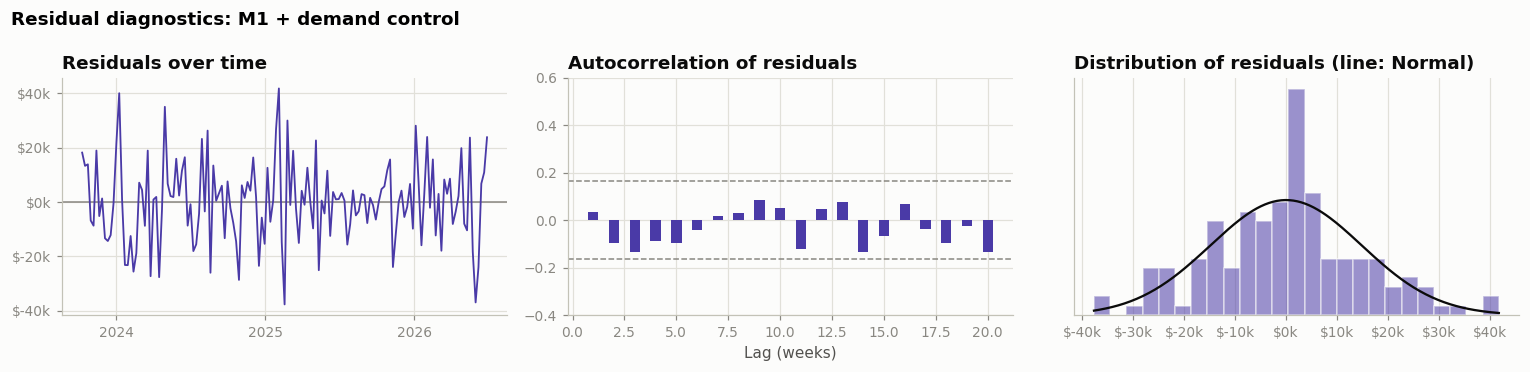

Residual std dev: $14,829   (true noise std dev: $14,000)
Durbin-Watson: 1.91
Ljung-Box test (8 lags): statistic 7.1, p-value 0.529
Shapiro-Wilk normality test: statistic 0.990, p-value 0.437


In [33]:
def residual_report(label: str, color: str) -> None:
    """Residual plots and tests for a model's training-period fit."""
    resid = ACTUALS[label]["train"] - PREDICTIONS[label]["train"].mean(axis=1)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))

    axes[0].axhline(0, color=MUTED, linewidth=1)
    axes[0].plot(train_df["date"], resid, color=color, linewidth=1.2)
    axes[0].set_title("Residuals over time")
    axes[0].xaxis.set_major_locator(mpl.dates.YearLocator())
    axes[0].xaxis.set_major_formatter(mpl.dates.DateFormatter("%Y"))
    thousands(axes[0])

    acf = sm.tsa.acf(resid, nlags=20)
    band = 1.96 / np.sqrt(len(resid))
    axes[1].bar(range(1, 21), acf[1:], color=color, width=0.5)
    axes[1].axhline(band, color=MUTED, linestyle="--", linewidth=1)
    axes[1].axhline(-band, color=MUTED, linestyle="--", linewidth=1)
    axes[1].set(title="Autocorrelation of residuals", xlabel="Lag (weeks)", ylim=(-0.4, 0.6))

    axes[2].hist(resid, bins=25, density=True, color=color, alpha=0.55, edgecolor=SURFACE)
    grid = np.linspace(resid.min(), resid.max(), 200)
    axes[2].plot(grid, stats.norm.pdf(grid, resid.mean(), resid.std()), color=INK, linewidth=1.5)
    axes[2].set_title("Distribution of residuals (line: Normal)")
    axes[2].set_yticks([])   # the density scale itself carries no information here
    thousands(axes[2], "x")
    fig.suptitle(f"Residual diagnostics: {label}", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()

    lb = acorr_ljungbox(resid, lags=[8], return_df=True)
    shapiro_stat, shapiro_p = stats.shapiro(resid)
    print(f"Residual std dev: ${resid.std():,.0f}   (true noise std dev: ${TRUE_PARAMS['y_sigma']:,.0f})")
    print(f"Durbin-Watson: {durbin_watson(resid):.2f}")
    print(f"Ljung-Box test (8 lags): statistic {lb['lb_stat'].iloc[0]:.1f}, p-value {lb['lb_pvalue'].iloc[0]:.3f}")
    print(f"Shapiro-Wilk normality test: statistic {shapiro_stat:.3f}, p-value {shapiro_p:.3f}")


residual_report("M1 + demand control", PYMC_COLOR)

**Reading the output.** Compared with the OLS baseline (Durbin-Watson 1.1), the residuals of M1 are well behaved.

* The Durbin-Watson statistic is about 1.9, close to 2: adstock, seasonality and trend have absorbed the time structure.
* The Ljung-Box p-value is about 0.5, so there is no evidence of autocorrelation at lags up to 8 weeks, and the ACF bars stay inside the band.
* The Shapiro-Wilk p-value is about 0.4, so there is no evidence against Normality.
* The residual standard deviation is about \$14,800, a little above the true noise level of \$14,000. The excess is what the model could not explain: the competitor promotions that are missing from our data (difficulty 11) and the part of demand that the noisy proxy does not capture.

Assumption (4) of Section 6.1 therefore holds up. Keep in mind what these tests cannot do. They check the noise assumptions; they are silent about confounding. M0, whose search estimate was badly biased, would not have been caught by a residual plot.

## 6.9 What the model learned about each channel

### Carry-over

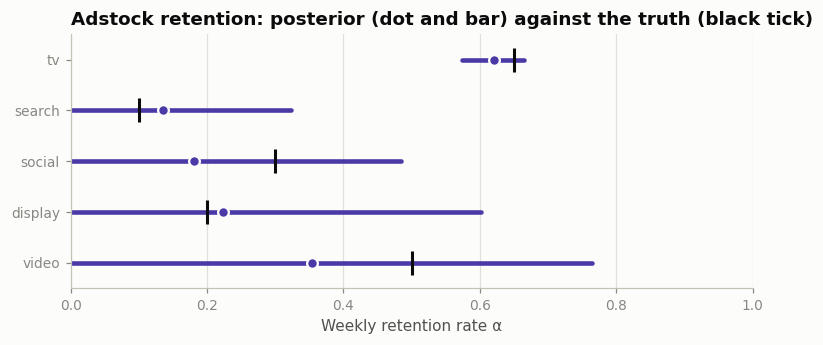

In [34]:
def interval_plot(ax: plt.Axes, draws: np.ndarray, truth_values: np.ndarray, color: str, xlabel: str) -> None:
    """Horizontal 94% HDI bars per channel with the true value marked."""
    for row, ch in enumerate(CHANNELS):
        lo, hi = az.hdi(draws[:, row], hdi_prob=0.94)
        ax.plot([lo, hi], [row, row], color=color, linewidth=3, solid_capstyle="round")
        ax.plot(np.median(draws[:, row]), row, "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
        ax.plot(truth_values[row], row, "|", color=INK, markersize=16, markeredgewidth=2)
    ax.set_yticks(range(len(CHANNELS)), CHANNELS)
    ax.set_ylim(len(CHANNELS) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)


post_m1 = mmm_m1.idata.posterior
alpha_draws = post_m1["adstock_alpha"].stack(sample=("chain", "draw")).transpose("sample", "channel").to_numpy()

fig, ax = plt.subplots(figsize=(8, 3))
interval_plot(ax, alpha_draws, TRUE_PARAMS["adstock_alpha"], PYMC_COLOR, "Weekly retention rate α")
ax.set_xlim(0, 1)
ax.set_title("Adstock retention: posterior (dot and bar) against the truth (black tick)")
plt.show()

**Reading the output.** TV's retention is estimated precisely and close to the true 0.65: the bursts followed by silence let the model watch the effect decay. For the always-on channels the intervals are wide. When spend never stops, last week's carry-over and this week's fresh effect are nearly indistinguishable, so the data says little about $\alpha$ and the posterior stays close to the prior. This is a general lesson: **parameters are learned from variation**. Flighting, tests and budget changes are what make a channel measurable.

### Response curves

The response curve shows the weekly contribution we should expect at each level of weekly spend, at steady state. It combines $\lambda$ and $\beta$ into the one object that budget decisions depend on.

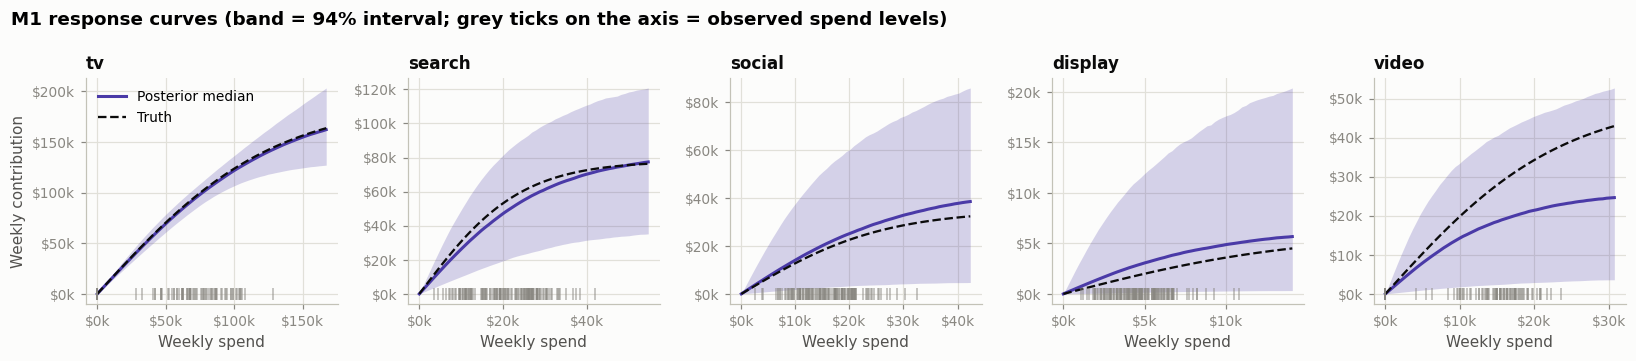

In [35]:
def true_response(channel_index: int, weekly_spend: np.ndarray) -> np.ndarray:
    """TRUE steady-state weekly contribution (dollars) at a given weekly spend. Answer key only."""
    scaled = weekly_spend / GEN_CHANNEL_SCALE[channel_index]
    return TRUE_PARAMS["saturation_beta"][channel_index] * logistic_saturation_np(scaled, TRUE_PARAMS["saturation_lam"][channel_index])


def pymc_response_draws(mmm: MMM, channel_index: int, weekly_spend: np.ndarray) -> np.ndarray:
    """Posterior draws of the steady-state response curve, shape (draws, len(weekly_spend))."""
    post = mmm.idata.posterior
    scales = mmm.get_scales_as_xarray()
    lam = post["saturation_lam"].isel(channel=channel_index).to_numpy().ravel()[:, None]
    beta = post["saturation_beta"].isel(channel=channel_index).to_numpy().ravel()[:, None]
    scaled = weekly_spend[None, :] / float(scales["channel_scale"][channel_index])
    return beta * logistic_saturation_np(scaled, lam) * float(scales["target_scale"])


def plot_response_curves(curve_fn, color: str, title: str) -> None:
    """Small multiples: estimated response curve with 94% band against the true curve."""
    fig, axes = plt.subplots(1, len(CHANNELS), figsize=(15, 3.3))
    for ax, (j, ch) in zip(axes, enumerate(CHANNELS)):
        grid = np.linspace(0, 1.3 * train_df[ch].max(), 60)
        draws = curve_fn(j, grid)
        lo, hi = np.quantile(draws, [0.03, 0.97], axis=0)
        ax.fill_between(grid, lo, hi, color=color, alpha=0.22, linewidth=0)
        ax.plot(grid, np.median(draws, axis=0), color=color, label="Posterior median")
        ax.plot(grid, true_response(j, grid), color=INK, linestyle="--", linewidth=1.5, label="Truth")
        # Rug: where the observed weekly spend actually lies.
        ax.plot(train_df[ch], np.zeros(N_TRAIN), "|", color=MUTED, markersize=8, alpha=0.6)
        ax.set_title(ch, fontsize=11)
        thousands(ax)
        thousands(ax, "x")
        ax.set_xlabel("Weekly spend")
    axes[0].set_ylabel("Weekly contribution")
    axes[0].legend(loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_response_curves(lambda j, grid: pymc_response_draws(mmm_m1, j, grid), PYMC_COLOR,
                     "M1 response curves (band = 94% interval; grey ticks on the axis = observed spend levels)")

**Reading the output.** For TV the estimated curve lies almost on top of the true curve, with a narrow band. For search the median is close to the truth but the band is wide. For social, display and video the bands are very wide: display's spans from nothing to several times the truth, and video's median sits below the true curve, which is nevertheless inside the band.

The grey ticks along the bottom show where spend was actually observed. The curve is only informed by data in that range, and **anything beyond the right-most tick is extrapolation**. Budget recommendations that push a channel far outside its historical range rest on the assumed curve shape, not on evidence.

### Multicollinearity, seen in the posterior

Section 5.6 predicted that the model would struggle to split credit between search and social. The posterior shows it directly: plot the ROAS draws of one channel against the other.

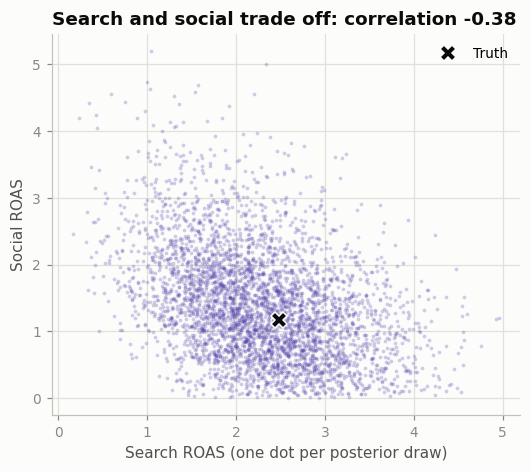

In [36]:
draws_m1 = ROAS_DRAWS["M1 + demand control"]
i_search, i_social = CHANNELS.index("search"), CHANNELS.index("social")
rho = np.corrcoef(draws_m1[:, i_search], draws_m1[:, i_social])[0, 1]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(draws_m1[:, i_search], draws_m1[:, i_social], s=6, color=PYMC_COLOR, alpha=0.25, linewidth=0)
ax.plot(TRUE_ROAS[i_search], TRUE_ROAS[i_social], marker="X", color=INK, markersize=11, markeredgecolor=SURFACE, linestyle="none", label="Truth")
ax.set(xlabel="Search ROAS (one dot per posterior draw)", ylabel="Social ROAS",
       title=f"Search and social trade off: correlation {rho:.2f}")
ax.legend()
plt.show()

**Reading the output.** The cloud slopes downward. Draws in which search has a high ROAS are draws in which social has a low one, and vice versa. The data pins down their *combined* effect far better than the split between them. The truth sits inside the cloud, so the model is not wrong, but it is unsure. No amount of modelling skill can remove this uncertainty from observational data; only new information can. That brings us to calibration.

## 6.10 Calibration with experiments (model M2)

A **lift test** is a randomised experiment: change the spend on a channel in some randomly chosen regions, leave the others alone, and measure the difference in sales. Because the assignment is random, the difference is *causal*, free of confounding. Lift tests are the gold standard (Section 1.3), but each one measures only one channel at one spend level.

**Calibration** means feeding experiment results into the MMM as additional evidence. In PyMC-Marketing a lift test is described by four numbers:

* `x`: the weekly spend level before the test,
* `delta_x`: the change in weekly spend during the test,
* `delta_y`: the measured change in weekly sales,
* `sigma`: the standard error of that measurement.

The library adds a second likelihood term which says: *the model's saturation curve for this channel, evaluated at `x + delta_x` minus its value at `x`, should equal `delta_y`, give or take `sigma`.* The response curve is then pinned down at the tested points, and the posterior narrows.

We simulate five experiments from the true response curves, each with 15% measurement noise: two on search, two on social and one on video.

In [37]:
rng_lift = np.random.default_rng(SEED + 1)
experiments = [  # (channel, weekly spend before the test, change in weekly spend)
    ("search", 15_000.0, 8_000.0),
    ("search", 25_000.0, 10_000.0),
    ("social", 12_000.0, 6_000.0),
    ("social", 18_000.0, 8_000.0),
    ("video", 10_000.0, 6_000.0),
]
rows = []
for channel, x0, dx in experiments:
    j = CHANNELS.index(channel)
    true_lift = float(true_response(j, np.array([x0 + dx]))[0] - true_response(j, np.array([x0]))[0])
    standard_error = 0.15 * true_lift                        # experiments are noisy too
    measured = true_lift + rng_lift.normal(0, standard_error)
    rows.append({"channel": channel, "x": x0, "delta_x": dx, "delta_y": measured, "sigma": standard_error,
                 "true_delta_y (answer key)": true_lift})
lift_results = pd.DataFrame(rows)
lift_results["incremental return per $"] = lift_results["delta_y"] / lift_results["delta_x"]
display(lift_results.round(2))

df_lift_test = lift_results[["channel", "x", "delta_x", "delta_y", "sigma"]]

,channel,x,delta_x,delta_y,sigma,true_delta_y (answer key),incremental return per $
0,search,15000.0,8000.0,12604.83,2210.62,14737.50,1.58
1,search,25000.0,10000.0,8334.09,1393.39,9289.29,0.83
2,social,12000.0,6000.0,4297.84,881.81,5878.71,0.72
3,social,18000.0,8000.0,6628.56,851.48,5676.54,0.83
4,video,10000.0,6000.0,7649.77,1419.47,9463.16,1.27


M2 fitted in 86 seconds.  Convergence: {'max r_hat': 1.0, 'min ess_bulk': 2228.0, 'min ess_tail': 1656.0, 'divergences': 0}


,true,median,hdi_3%,hdi_97%,truth inside interval
tv,1.41,1.36,1.19,1.53,True
search,2.48,2.20,1.36,3.09,True
social,1.17,0.88,0.68,1.15,False
display,0.40,0.65,0.00,2.07,True
video,1.82,1.61,0.84,2.70,True


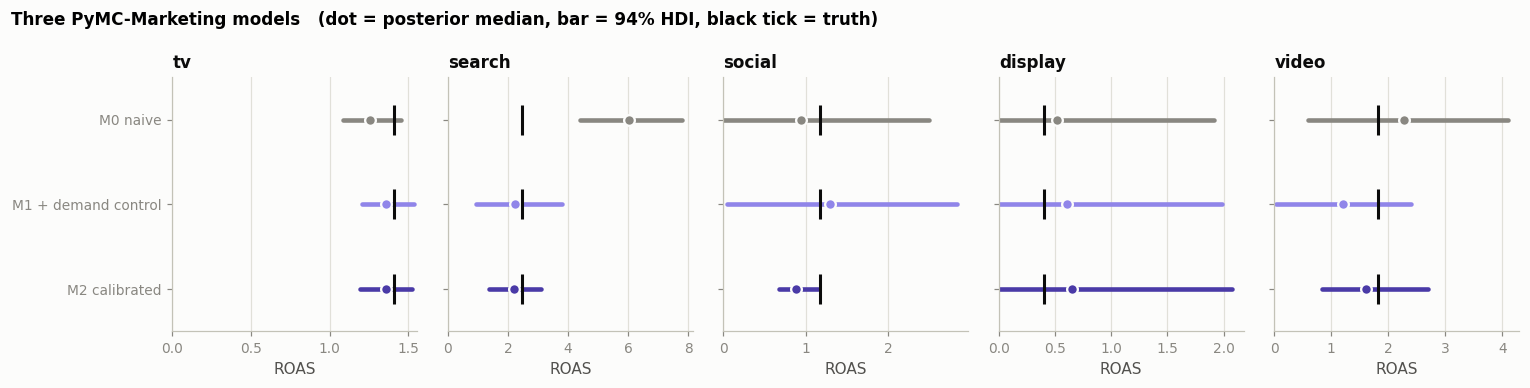

In [38]:
mmm_m2, seconds_m2 = fit_pymc_mmm(M1_CONTROLS, lift_tests=df_lift_test)
store_pymc_results("M2 calibrated", mmm_m2)
record_fit("M2 calibrated", pymc_predictions(mmm_m2, M1_CONTROLS))

print(f"M2 fitted in {seconds_m2:.0f} seconds.  Convergence: {mcmc_health(mmm_m2)}")
display(roas_table("M2 calibrated").round(2))
plot_roas(["M0 naive", "M1 + demand control", "M2 calibrated"], [MUTED, "#9085e9", PYMC_COLOR],
          "Three PyMC-Marketing models")

,M1 interval width,M2 interval width,change
tv,0.33,0.33,+0%
search,2.84,1.73,-39%
social,2.79,0.47,-83%
display,1.98,2.07,+5%
video,2.36,1.86,-21%


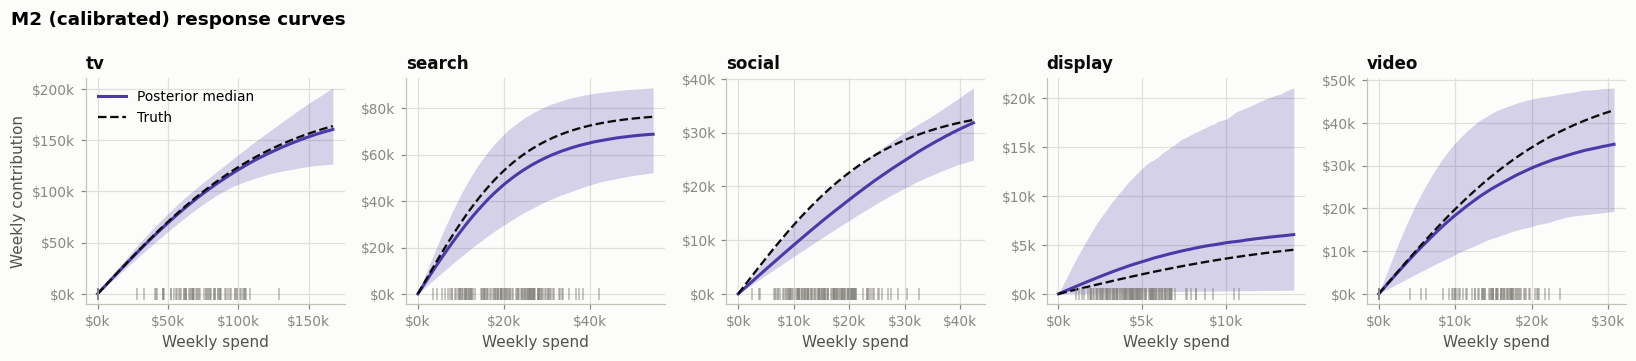

In [39]:
def interval_width(label: str) -> np.ndarray:
    """Width of the 94% HDI of ROAS per channel."""
    t = roas_table(label)
    return (t["hdi_97%"] - t["hdi_3%"]).to_numpy()


width_change = pd.DataFrame({
    "M1 interval width": interval_width("M1 + demand control"),
    "M2 interval width": interval_width("M2 calibrated"),
}, index=CHANNELS)
width_change["change"] = width_change["M2 interval width"] / width_change["M1 interval width"] - 1
display(width_change.style.format({"M1 interval width": "{:.2f}", "M2 interval width": "{:.2f}", "change": "{:+.0%}"}))

plot_response_curves(lambda j, grid: pymc_response_draws(mmm_m2, j, grid), PYMC_COLOR,
                     "M2 (calibrated) response curves")

**Reading the output.** The table shows the width of each channel's ROAS interval before and after calibration. For the three channels that had experiments the intervals shrink: by about 40% for search, 80% for social and 20% for video. TV and display, which had no experiment, are unchanged. In the response-curve plot, the search, social and video bands are visibly tighter than in M1.

This is what calibration buys: **the experiments break the tie that multicollinearity created.** The observational data could not split credit between search and social; the experiments could.

Now look at social more carefully. Its calibrated interval is narrow, about 0.7 to 1.15, and it *just misses* the true value of 1.17. The cause is in the experiment table above: the first social test measured a lift of about \$4,300 where the true lift was \$5,900, a result nearly two standard errors too low. That is ordinary bad luck for a noisy experiment, and the calibrated model inherited it. **Calibration transfers the experiment's error into the model along with its information.** A single test can be off by two standard errors about one time in twenty; several tests per channel, repeated over time, are the protection.

Two further cautions for real projects. First, a lift test measures the effect during the test window, usually without long-run carry-over, so what it measures and what the MMM estimates are not exactly the same quantity; treat calibration as strong evidence, not as an identity. Second, a badly run test (contaminated control regions, too short, too small) calibrates the model to a wrong number with great confidence. Check the experiment before trusting it.

## 6.11 Prior sensitivity

With little data the prior matters, so a responsible analysis asks: *would the conclusions change under a different reasonable prior?* We refit M1 with the prior on channel effect sizes made three times wider (`beta_prior_width` from 0.15 to 0.45), which weakens the "ROAS is similar across channels" belief, and compare.

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Fitted in 115 seconds.  Convergence: {'max r_hat': 1.0, 'min ess_bulk': 1463.0, 'min ess_tail': 1200.0, 'divergences': 1}


,true,M1 median,M1 width,wide-prior median,wide-prior width
tv,1.41,1.36,0.33,1.35,0.33
search,2.48,2.23,2.84,2.27,2.87
social,1.17,1.30,2.79,1.34,2.82
display,0.40,0.61,1.98,0.65,2.14
video,1.82,1.20,2.36,1.26,2.48


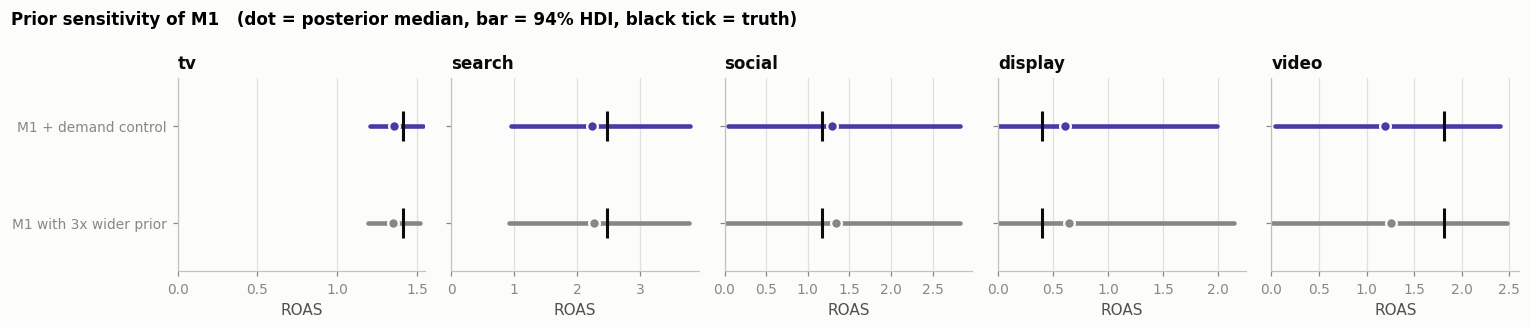

In [40]:
mmm_wide, seconds_wide = fit_pymc_mmm(M1_CONTROLS, beta_prior_width=0.45)
store_pymc_results("M1 with 3x wider prior", mmm_wide)
print(f"Fitted in {seconds_wide:.0f} seconds.  Convergence: {mcmc_health(mmm_wide)}")

sens = pd.DataFrame({
    "true": TRUE_ROAS,
    "M1 median": roas_table("M1 + demand control")["median"],
    "M1 width": interval_width("M1 + demand control"),
    "wide-prior median": roas_table("M1 with 3x wider prior")["median"],
    "wide-prior width": interval_width("M1 with 3x wider prior"),
})
display(sens.round(2))
plot_roas(["M1 + demand control", "M1 with 3x wider prior"], [PYMC_COLOR, MUTED], "Prior sensitivity of M1")

**Reading the output.** Tripling the width of the prior changes almost nothing. Medians move by at most 0.06 and interval widths by a few percent; the largest change is display, whose interval widens slightly.

That is good news, and it is informative about where the model's knowledge comes from. The conclusions do not hinge on how wide we made this prior. What bounds the estimates is the data together with the *sign* constraint (effects cannot be negative), which is why several intervals start at zero.

The check has limits. We varied one prior in one direction. A thorough analysis would also vary the adstock and saturation priors, and would try a prior that does not scale with spend share. And insensitivity to the prior does not make wide intervals narrow: social, display and video remain poorly measured whatever prior we choose. A report to decision makers should say so plainly: "TV is measured well; search moderately; social, display and video need experiments."

## 6.12 Decomposition: where did sales come from?

Finally, the chart most stakeholders ask for: sales split into baseline and media contributions over time. We use the calibrated model M2 and compare each channel's estimated weekly contribution with the answer key.

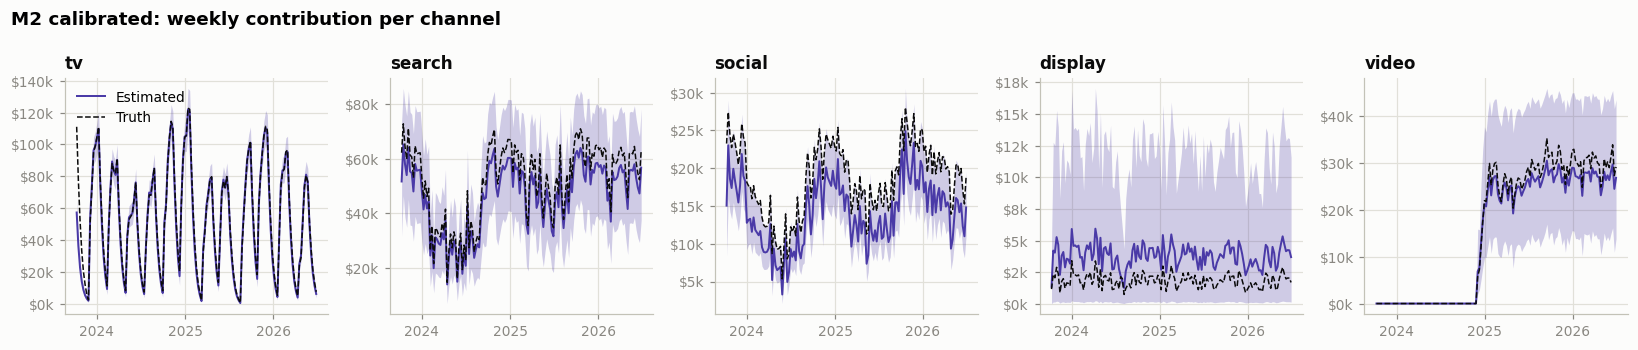

,true share of sales,estimated share (mean),hdi_3%,hdi_97%
tv,11.2%,10.8%,9.4%,12.1%
search,10.7%,9.7%,5.9%,13.4%
social,3.8%,2.9%,2.2%,3.8%
display,0.4%,0.8%,0.0%,2.0%
video,3.3%,3.0%,1.5%,4.9%
all media,29.4%,27.2%,22.8%,31.6%


In [41]:
def decomposition_plot(label: str, color: str) -> None:
    """Small multiples: estimated weekly contribution per channel (mean and 94% band) against the truth."""
    draws = CONTRIB_DRAWS[label]
    fig, axes = plt.subplots(1, len(CHANNELS), figsize=(15, 3.2))
    for ax, (j, ch) in zip(axes, enumerate(CHANNELS)):
        lo, hi = np.quantile(draws[:, :, j], [0.03, 0.97], axis=0)
        ax.fill_between(train_df["date"], lo, hi, color=color, alpha=0.25, linewidth=0)
        ax.plot(train_df["date"], draws[:, :, j].mean(axis=0), color=color, linewidth=1.3, label="Estimated")
        ax.plot(train_df["date"], truth[f"contrib_{ch}"].iloc[:N_TRAIN], color=INK, linewidth=1, linestyle="--", label="Truth")
        ax.set_title(ch, fontsize=11)
        thousands(ax)
        ax.xaxis.set_major_locator(mpl.dates.YearLocator())
        ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%Y"))
    axes[0].legend(loc="upper left")
    fig.suptitle(f"{label}: weekly contribution per channel", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


decomposition_plot("M2 calibrated", PYMC_COLOR)

total_sales_train = train_df["sales"].sum()
share_draws = CONTRIB_DRAWS["M2 calibrated"].sum(axis=1) / total_sales_train
share = pd.DataFrame({
    "true share of sales": TRUE_CONTRIB_TRAIN / total_sales_train,
    "estimated share (mean)": share_draws.mean(axis=0),
    "hdi_3%": [az.hdi(share_draws[:, j], hdi_prob=0.94)[0] for j in range(len(CHANNELS))],
    "hdi_97%": [az.hdi(share_draws[:, j], hdi_prob=0.94)[1] for j in range(len(CHANNELS))],
}, index=CHANNELS)
share.loc["all media"] = [TRUE_CONTRIB_TRAIN.sum() / total_sales_train, share_draws.sum(axis=1).mean(),
                          *az.hdi(share_draws.sum(axis=1), hdi_prob=0.94)]
display(share.style.format("{:.1%}"))

**Reading the output.** The estimated weekly contributions follow the true ones in shape for every channel: the TV bursts and their decay, the seasonal rise of search and social, the launch of video. The table gives the totals. The model attributes about 27% of sales to media, with a 94% interval of roughly 23% to 32% that contains the true 29.4%. Note that the interval for *all media* is tighter, relative to its size, than the intervals for the individual digital channels. The sum is better identified than its parts, for the reason seen in the scatter plot of Section 6.9.

In [42]:
# Log the three main PyMC fits to MLflow.
for label, mmm, secs, extra in [
    ("pymc_M0_naive", mmm_m0, seconds_m0, {"controls": ",".join(BASE_CONTROLS), "lift_tests": 0, "key": "M0 naive"}),
    ("pymc_M1_demand_control", mmm_m1, seconds_m1, {"controls": ",".join(M1_CONTROLS), "lift_tests": 0, "key": "M1 + demand control"}),
    ("pymc_M2_calibrated", mmm_m2, seconds_m2, {"controls": ",".join(M1_CONTROLS), "lift_tests": len(df_lift_test), "key": "M2 calibrated"}),
]:
    key = extra.pop("key")
    roas_error = np.abs(np.median(ROAS_DRAWS[key], axis=0) - TRUE_ROAS) / TRUE_ROAS
    log_run(label, "pymc-marketing",
            params={**SAMPLER, **extra, "adstock": "geometric", "saturation": "logistic", "l_max": L_MAX},
            metrics={**{k.replace(" ", "_"): v for k, v in FIT_ROWS[key].items()},
                     **{k.replace(" ", "_"): v for k, v in mcmc_health(mmm).items()},
                     "fit_seconds": secs, "mean_abs_pct_error_roas": roas_error.mean()},
            data_hash=DATA_HASH)
print("Logged 3 runs to MLflow experiment 'mmm-textbook'.")

Logged 3 runs to MLflow experiment 'mmm-textbook'.


---
# Part VII. The MMM in Google Meridian, on geo-level data

## 7.1 How Meridian thinks

Meridian is Google's open-source MMM library. It is Bayesian like PyMC-Marketing and uses the same NUTS sampler, here running on the JAX numerical backend. The model has the same overall shape (baseline plus adstocked and saturated media plus controls) but it is built around **geo-level data**: one time series per region instead of a single national series. Writing $g$ for region and $t$ for week:

$$
y_{g,t} \;=\; \underbrace{\mu_t}_{\text{time effect (knots)}} \;+\; \underbrace{\tau_g}_{\text{region effect}} \;+\; \underbrace{\sum_{c} \gamma_{g,c}\, z_{g,c,t}}_{\text{controls}} \;+\; \underbrace{\sum_{m} \beta_{g,m}\, \text{Hill}\big(\text{adstock}(x_{g,m,t};\,\alpha_m);\; ec_m,\, slope_m\big)}_{\text{media}} \;+\; \varepsilon_{g,t}
$$

Here $y_{g,t}$ is sales **per person** in region $g$, and $x_{g,m,t}$ is media **per person**. Dividing by population puts a region of 90,000 people and a region of 900,000 on the same footing.

| Topic | PyMC-Marketing (as configured in Part VI) | Meridian |
|---|---|---|
| Unit of analysis | One national series | **One series per region**, scaled by population |
| Saturation curve | Logistic, parameter $\lambda$ | Hill, parameters $ec$ and $slope$ (slope fixed at 1 by default for media: concave) |
| Trend and seasonality | Fourier seasonality plus piecewise-linear trend | One flexible **time effect** $\mu_t$ defined by **knots** |
| Differences between regions | Not applicable | Region baseline $\tau_g$; media effect $\beta_{g,m}$ varies by region around a common mean (**hierarchical**) |
| What the media prior is placed on | The coefficient $\beta_m$ | The **ROI** of each channel directly |
| Experiments | Lift tests as extra likelihood terms on the response curve | Experiments translated into the **ROI prior** |

Four ideas need explanation.

**Why geo-level data helps.** A national series gives one observation per week. Twenty regions give twenty. More importantly, regions differ in how much media they receive per person, and those differences are a second source of variation, separate from variation over time. Something that hits all regions in the same week (a holiday, a national demand swing) can be separated from media if media intensity differs across regions in that week. This is why Meridian's documentation recommends geo-level data whenever it exists.

**Hierarchical effects.** Meridian does not assume that a channel works equally well everywhere, nor does it estimate each region in isolation. It assumes that the regional effects $\beta_{g,m}$ are draws from a common distribution whose mean and spread are themselves estimated. Regions with little data are pulled towards the common mean; regions with strong evidence can deviate. This is called **partial pooling**, and the parameter `eta_m` measures how much a channel's effect varies across regions.

**Knots.** Instead of separate trend and seasonality terms, Meridian lets the time effect $\mu_t$ change over time. It places a number of *knots* along the time axis, estimates a value at each, and interpolates linearly between them. More knots give a more flexible baseline. This is a trade-off: with too few knots the baseline cannot follow trend and season, and media absorbs the difference; with too many, the baseline can soak up variation that media actually caused.

**ROI priors.** This is Meridian's signature idea. In most MMMs you put a prior on a regression coefficient, which few people have intuitions about. Meridian re-parameterises the model so that the prior is on each channel's **ROI**, a quantity that marketers do have beliefs about and that experiments measure directly. The default is $\text{LogNormal}(0.2, 0.9)$: a median ROI of about 1.2, with 95% of the prior mass between roughly 0.2 and 7.

**Assumptions.** As in Section 6.1 (additivity, stable response curves, no unobserved confounding, Normal noise), plus: the saturation curve is Hill-shaped, and regional effects are exchangeable draws from a common distribution.

In [43]:
# Meridian is imported here, at the point where it is first needed.
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import immutabledict
import meridian
from meridian import backend, constants
from meridian.data import data_frame_input_data_builder as data_builder
from meridian.model import model as meridian_model
from meridian.model import spec as meridian_spec
from meridian.model import prior_distribution
from meridian.analysis import analyzer as meridian_analyzer
from meridian.analysis import optimizer as meridian_optimizer
from meridian.analysis.review import reviewer as meridian_reviewer

ENVIRONMENT["google_meridian"] = meridian.__version__
print(f"google-meridian {meridian.__version__}")

google-meridian 2.1.0


## 7.2 A geo-level dataset for Meridian

The national dataset of Part IV was produced by PyMC-Marketing's own functions, and a single national series is the setting Meridian is least suited to. To study Meridian on its own terms we generate a second dataset: **the same company, the same three years, now reported for 20 sales regions**, with sales produced by **Meridian's model form**.

What stays the same as in Part IV:

* the five channels and their national weekly budgets (the national `spend` matrix is reused and split across regions),
* the calendar: trend, seasonality, holidays, price promotions, the stock-out,
* the hidden drivers: market demand (now with a regional component) and competitor promotions (now only in some regions),
* the true adstock retention rates.

What is new:

| Feature | How it is built | Why it matters |
|---|---|---|
| **Regions of unequal size** | 20 populations from a skewed distribution, from under 100 thousand to nearly 1 million | Requires population scaling; small regions are noisier |
| **Regional media mix** | Each region's share of a channel's budget is its population share times a region-specific tilt, plus week-to-week noise | Creates the cross-region variation that geo models exploit |
| **A national channel** | TV is bought nationally: every region gets almost the same TV spend per person | Geo data adds nothing for a channel with no regional variation |
| **Local demand confounding** | Demand has a national part and a regional part; search spend follows both | The confounder now also operates across regions |
| **Hill saturation per person** | Response depends on adstocked spend per person through a Hill curve with slope 1 | Meridian's functional form |
| **Regional effect heterogeneity** | Each channel's effect varies across regions by about 20% (log-normal) | Meridian's hierarchical structure |
| **Regional baselines** | Baseline sales per person differ by about 15% between regions | The region effect $\tau_g$ |

There is no ready-made simulator for this in either library, so we write the generating equations out in NumPy. That keeps every assumption visible. The true ROAS of each channel is set by construction to the same round targets as before (1.4, 2.5, 1.2, 0.4, 1.8), so the two datasets describe a similar market.

### Step 1: regions and regional media spend

In [44]:
rng_geo = np.random.default_rng(SEED + 2)

N_GEOS: int = 20
GEOS: list[str] = [f"region_{i + 1:02d}" for i in range(N_GEOS)]

# Region sizes: a skewed (log-normal) distribution, sorted from largest to smallest.
population = np.sort(rng_geo.lognormal(mean=np.log(400_000), sigma=0.7, size=N_GEOS))[::-1].round(-3)
pop_share = population / population.sum()

# Hidden demand per region = a national part (the series from Part IV) + a regional part.
local_shocks = rng_geo.normal(0, 1, (N_TOTAL, N_GEOS))
local_demand = np.zeros((N_TOTAL, N_GEOS))
for i in range(1, N_TOTAL):  # explicit loop: each value depends on the previous one
    local_demand[i] = 0.85 * local_demand[i - 1] + local_shocks[i]
local_demand = (local_demand - local_demand.mean(axis=0)) / local_demand.std(axis=0)
demand_geo = np.sqrt(0.6) * demand[:, None] + np.sqrt(0.4) * local_demand      # (weeks, regions)

# Split each channel's national budget across regions.
#                         tv    search social display video
regional_tilt_sd = np.array([0.05, 0.35, 0.35, 0.40, 0.40])   # persistent differences between regions
weekly_noise_sd  = np.array([0.05, 0.25, 0.25, 0.35, 0.30])   # week-to-week regional variation
regional_tilt = np.exp(rng_geo.normal(0, regional_tilt_sd, (N_GEOS, len(CHANNELS))))
budget_share = pop_share[:, None] * regional_tilt
budget_share = budget_share / budget_share.sum(axis=0)          # each channel's shares sum to 1
weekly_noise = np.exp(rng_geo.normal(0, weekly_noise_sd, (N_TOTAL, N_GEOS, len(CHANNELS))))
weekly_noise[:, :, CHANNELS.index("search")] *= np.exp(0.30 * local_demand)   # search chases LOCAL demand too

# geo_spend has shape (weeks, regions, channels). `spend` is the national matrix from Part IV.
geo_spend = np.round(spend[:, None, :] * budget_share[None, :, :] * weekly_noise, 2)

pd.DataFrame({"population": population.astype(int), "population share": pop_share.round(3)}, index=GEOS).T

,region_01,region_02,region_03,region_04,region_05,region_06,region_07,region_08,region_09,region_10,region_11,region_12,region_13,region_14,region_15,region_16,region_17,region_18,region_19,region_20
population,948000.000,868000.000,633000.000,622000.000,561000.000,384000.000,371000.00,345000.000,340000.000,318000.000,292000.00,269000.000,236000.000,222000.00,212000.000,211000.000,180000.000,149000.00,144000.000,86000.000
population share,0.128,0.117,0.086,0.084,0.076,0.052,0.05,0.047,0.046,0.043,0.04,0.036,0.032,0.03,0.029,0.029,0.024,0.02,0.019,0.012


### Step 2: the true response, in Meridian's form

For each region and channel: divide spend by population, apply geometric adstock, apply a Hill curve, and multiply by a regional effect size. The Hill half-saturation point `ec` of each channel is set relative to the typical (median) level of adstocked spend per person, so that typical spend sits on the bending part of the curve. The overall effect size of each channel is then solved for, so that its national ROAS equals the target.

In [45]:
GEO_TRUE: dict = {
    #                         tv   search social display video
    "target_roas": np.array([1.4, 2.5,   1.2,   0.4,    1.8]),
    "ec_factor":   np.array([1.5, 0.8,   1.0,   1.5,    1.2]),   # ec as a multiple of median adstocked spend per person
    "slope":       np.ones(len(CHANNELS)),                        # slope 1: concave from the first dollar
    "eta": 0.2,                                                   # spread of regional effects (log scale)
}

spend_per_person = geo_spend / population[None, :, None]
# Adstock every region-channel series with the same retention rates as in Part IV.
adstocked_pp = np.stack([
    np.stack([geometric_adstock_np(spend_per_person[:, g, m], TRUE_PARAMS["adstock_alpha"][m], L_MAX)
              for m in range(len(CHANNELS))], axis=-1)
    for g in range(N_GEOS)
], axis=1)                                                         # (weeks, regions, channels)

GEO_EC = np.array([GEO_TRUE["ec_factor"][m] * np.median(adstocked_pp[:, :, m][adstocked_pp[:, :, m] > 0])
                   for m in range(len(CHANNELS))])
GEO_HET = np.exp(rng_geo.normal(0, GEO_TRUE["eta"], (N_GEOS, len(CHANNELS))))   # regional effect multipliers

# Response in "units"; the channel effect size beta then converts units to dollars.
response_units = population[None, :, None] * GEO_HET[None, :, :] * hill_np(
    adstocked_pp, GEO_EC[None, None, :], GEO_TRUE["slope"][None, None, :])
GEO_BETA = GEO_TRUE["target_roas"] * geo_spend[obs].sum(axis=(0, 1)) / response_units[obs].sum(axis=(0, 1))
true_media_geo_all = response_units * GEO_BETA                     # true dollar contribution (weeks, regions, channels)

pd.DataFrame({"ec (adstocked $ per person per week)": GEO_EC, "effect size beta ($ per person at saturation)": GEO_BETA},
             index=CHANNELS).round(5)

,ec (adstocked $ per person per week),effect size beta ($ per person at saturation)
tv,0.00739,0.01991
search,0.00206,0.01378
social,0.00200,0.00529
display,0.00086,0.00070
video,0.00203,0.00800


### Step 3: baseline, noise and the sales series

The regional baseline reuses the true national effects of Part IV (`TRUE_PARAMS`), shared out by population. Each region has its own baseline level. Competitor promotions hit about 60% of the regions. Noise is larger, relative to sales, in small regions, and is sized so that the national total has the same noise level as before (\$14,000 a week).

In [46]:
g_trend, g_price, g_demand, g_competitor, g_bf, g_xmas, g_stockout = TRUE_PARAMS["gamma_control"]

regional_level = np.exp(rng_geo.normal(0, 0.15, N_GEOS))                       # baseline differences between regions
competitor_geo = competitor_promo[:, None] * (rng_geo.uniform(size=N_GEOS) < 0.6)[None, :]

# The part of the national baseline that is common to all regions (dollars per week, national scale).
common_baseline = (
    TRUE_PARAMS["intercept"] + g_trend * trend_shape + true_season_all
    + g_bf * black_friday + g_xmas * christmas + g_price * (price_index - 1.0) + g_stockout * stockout
)
baseline_geo = pop_share[None, :] * (
    regional_level[None, :] * common_baseline[:, None] + g_demand * demand_geo + g_competitor * competitor_geo
)

noise_sd_geo = pop_share ** 0.75
noise_sd_geo = TRUE_PARAMS["y_sigma"] * noise_sd_geo / np.sqrt((noise_sd_geo ** 2).sum())
sales_geo_all = baseline_geo + true_media_geo_all.sum(axis=-1) + rng_geo.normal(0, 1, (N_TOTAL, N_GEOS)) * noise_sd_geo[None, :]
assert (sales_geo_all[obs] > 0).all(), "Simulated sales must be positive in every region and week."

proxy_geo_all = 100 * (1 + 0.25 * demand_geo) + rng_geo.normal(0, 6, (N_TOTAL, N_GEOS))   # regional demand proxy

# --- The analyst's geo dataset (long format: one row per region and week) ---------------
geo_dates = dates[obs]
geo_data = pd.DataFrame({
    "date": np.repeat(geo_dates, N_GEOS),
    "geo": np.tile(GEOS, N_OBS),
    "population": np.tile(population, N_OBS).astype(int),
    "sales": np.round(sales_geo_all[obs].ravel(), 2),
})
for m, ch in enumerate(CHANNELS):
    geo_data[ch] = geo_spend[obs][:, :, m].ravel()
geo_data["price_index"] = np.round(np.repeat(price_index[obs], N_GEOS), 4)
geo_data["brand_search_index"] = np.round(proxy_geo_all[obs].ravel(), 1)

# --- The answer key -------------------------------------------------------------------
true_media_geo = true_media_geo_all[obs]                                        # (weeks, regions, channels)
geo_truth = geo_data[["date", "geo"]].copy()
for m, ch in enumerate(CHANNELS):
    geo_truth[f"contrib_{ch}"] = true_media_geo[:, :, m].ravel()

geo_data.to_csv("data/mmm_geo_weekly.csv", index=False)
geo_truth.to_csv("data/ground_truth_geo.csv", index=False)
GEO_DATA_HASH: str = hashlib.sha256(Path("data/mmm_geo_weekly.csv").read_bytes()).hexdigest()

GEO_SPEND_TRAIN = geo_spend[obs][:N_TRAIN].sum(axis=(0, 1))
TRUE_CONTRIB_GEO_TRAIN = true_media_geo[:N_TRAIN].sum(axis=(0, 1))
TRUE_ROAS_GEO = TRUE_CONTRIB_GEO_TRAIN / GEO_SPEND_TRAIN

print(f"Saved data/mmm_geo_weekly.csv  ({geo_data.shape[0]:,} rows x {geo_data.shape[1]} columns)  sha256 {GEO_DATA_HASH[:12]}...")
print(f"Media explains {true_media_geo.sum() / sales_geo_all[obs].sum():.1%} of total sales in the geo dataset.")
pd.DataFrame({"true ROAS, national dataset (Part IV)": TRUE_ROAS, "true ROAS, geo dataset": TRUE_ROAS_GEO}, index=CHANNELS).round(2)

Saved data/mmm_geo_weekly.csv  (3,120 rows x 11 columns)  sha256 af3d86fb1c47...
Media explains 29.9% of total sales in the geo dataset.


,"true ROAS, national dataset (Part IV)","true ROAS, geo dataset"
tv,1.41,1.39
search,2.48,2.56
social,1.17,1.20
display,0.40,0.40
video,1.82,1.81


**Reading the output.** The geo dataset has 3,120 rows (20 regions times 156 weeks). Media explains about 30% of sales, as in the national dataset, and the true ROAS values in the training window are close to the round targets. The two answer keys are similar but not identical, so from here on **each library is graded against the truth of its own dataset**.

## 7.3 A look at the geo data

The checks of Part V apply to geo data as well; we repeat the essential ones briefly and add the question that is specific to geo data: *how much does each channel's intensity differ across regions?*

Shape: 3,120 rows x 11 columns;  regions: 20;  weeks: 156
Missing values: 0;  every region has every week: True


,mean weekly $ per person,coefficient of variation across regions
sales,0.0683,10%
tv,0.0050,6%
search,0.0031,40%
social,0.0022,28%
display,0.0007,42%
video,0.0012,49%


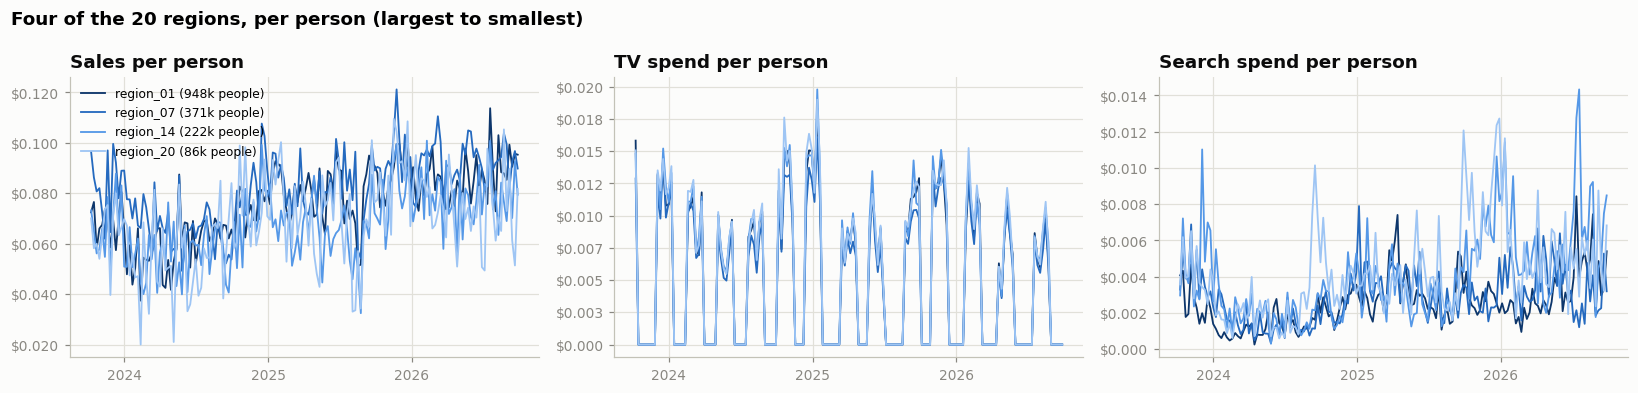

In [47]:
geo_df = pd.read_csv("data/mmm_geo_weekly.csv", parse_dates=["date"])
print(f"Shape: {geo_df.shape[0]:,} rows x {geo_df.shape[1]} columns;  regions: {geo_df['geo'].nunique()};  weeks: {geo_df['date'].nunique()}")
print(f"Missing values: {int(geo_df.isna().sum().sum())};  every region has every week: "
      f"{bool((geo_df.groupby('geo')['date'].nunique() == N_OBS).all())}")

per_person = geo_df.assign(**{c: geo_df[c] / geo_df["population"] for c in ["sales"] + CHANNELS})
regional_mean = per_person.groupby("geo")[["sales"] + CHANNELS].mean()
variation = pd.DataFrame({
    "mean weekly $ per person": regional_mean.mean(),
    "coefficient of variation across regions": regional_mean.std() / regional_mean.mean(),
})
display(variation.style.format({"mean weekly $ per person": "{:.4f}", "coefficient of variation across regions": "{:.0%}"}))

show_regions = [GEOS[0], GEOS[6], GEOS[13], GEOS[19]]      # largest, two mid-sized, smallest
region_colors = ["#0d366b", "#256abf", "#5598e7", "#9ec5f4"]   # one hue, dark to light = large to small
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for region, color in zip(show_regions, region_colors):
    part = per_person[per_person["geo"] == region]
    label = f"{region} ({int(part['population'].iloc[0] / 1e3)}k people)"
    axes[0].plot(part["date"], part["sales"], color=color, linewidth=1.2, label=label)
    axes[1].plot(part["date"], part["tv"], color=color, linewidth=1.2)
    axes[2].plot(part["date"], part["search"], color=color, linewidth=1.2)
axes[0].set_title("Sales per person")
axes[1].set_title("TV spend per person")
axes[2].set_title("Search spend per person")
for ax in axes:
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"${v:.3f}"))
    ax.xaxis.set_major_locator(mpl.dates.YearLocator())
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%Y"))
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Four of the 20 regions, per person (largest to smallest)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the output.**

* The panel is complete: no missing values and every region has all 156 weeks.
* **Sales per person** follow the same national pattern in every region (trend, season, the stock-out dip), at somewhat different levels. The smallest region is visibly noisier than the largest.
* **TV per person is nearly identical across regions** (a coefficient of variation of about 6%): the lines lie on top of each other. For TV, having 20 regions is close to having the same observation 20 times.
* **Search per person differs a lot between regions** (about 40%) and from week to week. This is the variation a geo model can learn from. Display and video vary similarly; social somewhat less.

So we should expect geo data to help most for the digital channels and little for TV, which is already well identified by its flighting.

## 7.4 Preparing the input data

We engineer the same features as for the national data. The demand proxy is standardised with training-period statistics only, to avoid leakage.

Meridian wants its data in an `InputData` object. The `DataFrameInputDataBuilder` assembles one from a long-format data frame (one row per region and week), piece by piece:

* **KPI**: the outcome. We declare `kpi_type="revenue"` because our KPI is sales in dollars. (If the KPI were units or sign-ups, Meridian would also need a `revenue_per_kpi` to compute ROI.)
* **Population**: one value per region, used to put regions on a per-person scale.
* **Media and media spend**: Meridian separates the *exposure* variable that drives the effect (ideally impressions) from the *spend* used to compute ROI. We only have spend, so we pass it as both.
* **Controls**: price, holidays, the stock-out indicator and the regional demand proxy.

All 156 weeks are passed in. The 13 test weeks are marked with a **holdout mask** (one flag per region and week): they are excluded from the likelihood, so the model does not learn from their sales, but their spend is used and Meridian predicts them.

In [48]:
geo_df["black_friday"] = geo_df["date"].apply(is_black_friday_week).astype(float)
geo_df["christmas"] = geo_df["date"].apply(is_christmas_week).astype(float)
geo_df["stockout"] = geo_df["date"].isin(df.loc[stockout_rows, "date"]).astype(float)   # confirmed by operations (5.3)
geo_df["price_dev"] = geo_df["price_index"] - 1.0

geo_is_train = geo_df["date"] <= train_df["date"].max()
geo_proxy_mean = geo_df.loc[geo_is_train, "brand_search_index"].mean()
geo_proxy_sd = geo_df.loc[geo_is_train, "brand_search_index"].std()
geo_df["demand_proxy"] = (geo_df["brand_search_index"] - geo_proxy_mean) / geo_proxy_sd
geo_df["time"] = geo_df["date"].dt.strftime("%Y-%m-%d")       # Meridian expects dates as text

MERIDIAN_CONTROLS: list[str] = M1_CONTROLS
train_times: list[str] = sorted(geo_df["time"].unique())[:N_TRAIN]


def build_input_data(frame: pd.DataFrame):
    """Assemble a Meridian InputData object from a long-format data frame with `geo` and `time` columns."""
    builder = data_builder.DataFrameInputDataBuilder(kpi_type="revenue", default_kpi_column="sales")
    builder = (
        builder.with_kpi(frame)
        .with_population(frame)
        .with_controls(frame, control_cols=MERIDIAN_CONTROLS)
        .with_media(frame, media_cols=CHANNELS, media_spend_cols=CHANNELS, media_channels=CHANNELS)
    )
    return builder.build()


geo_input = build_input_data(geo_df)
geo_holdout = np.zeros((N_GEOS, N_OBS), dtype=bool)
geo_holdout[:, N_TRAIN:] = True

print(f"KPI array shape (regions, weeks): {geo_input.kpi.shape}")
print(f"Media array shape (regions, weeks, channels): {geo_input.media.shape}")
print(f"Region-weeks held out: {int(geo_holdout.sum())}")

KPI array shape (regions, weeks): (20, 156)
Media array shape (regions, weeks, channels): (20, 156, 5)
Region-weeks held out: 260


## 7.5 Model specification

`ModelSpec` collects the modelling choices.

* `prior`: a `PriorDistribution`. We set only the ROI prior explicitly (to its default value, to show how it is done) and keep the defaults for everything else.
* `max_lag=8`: the adstock window, the same 8 weeks as in PyMC.
* `knots`: positions of the knots of the time effect.
* `holdout_id`: the test-week mask.

**Choosing the number of knots.** For geo models Meridian's default is one knot *per week*: the time effect $\mu_t$ is then completely free, and absorbs anything that affects all regions equally in a given week. That is a strong defence against national confounders such as seasonality or a competitor's national campaign. But it has a cost that matters here: **a channel that is the same in all regions is then indistinguishable from the time effect.** Our TV is bought nationally, so with weekly knots its effect could not be estimated from the data at all. We therefore use 12 knots over the training period (about one per quarter): flexible enough for trend and a smooth yearly cycle, restrictive enough that TV's week-to-week bursts cannot be explained by the baseline. We place no knots inside the held-out period, where they would have no data to inform them.

In [49]:
def make_roi_prior(mu: np.ndarray, sigma: np.ndarray):
    """A LogNormal ROI prior with one (mu, sigma) pair per channel, in Meridian's numeric type."""
    as_float = backend.np_float_dtype
    return backend.tfd.LogNormal(as_float(np.asarray(mu)), as_float(np.asarray(sigma)), name=constants.ROI_M)


N_KNOTS: int = 12
KNOTS: list[int] = np.unique(np.round(np.linspace(0, N_TRAIN - 1, N_KNOTS)).astype(int)).tolist()
MERIDIAN_SAMPLER: dict = {"n_chains": 4, "n_adapt": 2_000, "n_burnin": 500, "n_keep": 1_000}
MERIDIAN_TARGET_ACCEPT: float = 0.95


def fit_meridian(input_data, holdout: np.ndarray, roi_mu: np.ndarray, roi_sigma: np.ndarray) -> tuple[meridian_model.Meridian, float]:
    """Build and fit a Meridian model with the given per-channel ROI prior. Returns (model, seconds)."""
    model_spec = meridian_spec.ModelSpec(
        prior=prior_distribution.PriorDistribution(roi_m=make_roi_prior(roi_mu, roi_sigma)),
        max_lag=L_MAX,
        knots=KNOTS,
        holdout_id=holdout,
    )
    mer = meridian_model.Meridian(input_data=input_data, model_spec=model_spec)
    started = time.perf_counter()
    mer.sample_prior(500, seed=SEED)                       # draws from the prior, for prior-vs-posterior comparisons
    # NUTS. The step-size settings must be passed as an immutable (hashable) mapping for the JAX backend.
    mer.sample_posterior(
        seed=SEED,
        dual_averaging_kwargs=immutabledict.immutabledict({"target_accept_prob": MERIDIAN_TARGET_ACCEPT}),
        **MERIDIAN_SAMPLER,
    )
    return mer, time.perf_counter() - started


# Default ROI prior for every channel: LogNormal(0.2, 0.9).
default_mu, default_sigma = np.full(len(CHANNELS), 0.2), np.full(len(CHANNELS), 0.9)
prior_draws = stats.lognorm(s=0.9, scale=np.exp(0.2))
print(f"Default ROI prior: median {prior_draws.median():.2f}, 95% of mass between "
      f"{prior_draws.ppf(0.025):.2f} and {prior_draws.ppf(0.975):.2f}")
print(f"Knot positions (week index): {KNOTS}")

Default ROI prior: median 1.22, 95% of mass between 0.21 and 7.13
Knot positions (week index): [0, 13, 26, 39, 52, 65, 77, 90, 103, 116, 129, 142]


## 7.6 Fitting model G1

`sample_posterior` takes `n_adapt` (steps in which the sampler tunes its step size), `n_burnin` (further warm-up steps, discarded) and `n_keep` (kept draws per chain). With 4 chains and 1,000 kept draws we get 4,000 posterior samples, the same as for the PyMC models.

**A note on sampler settings.** We use 2,000 adaptation steps and a target acceptance probability of 0.95 (smaller, more careful steps) in place of Meridian's defaults of 1,000 and about 0.85. On the national version of this model the defaults produced around 60 divergent transitions and effective sample sizes below 100; the more careful settings removed almost all of them. Raising the target acceptance is the usual first remedy for divergences in any NUTS-based library, and it is why diagnostics must be read before results.

The geo model has far more parameters than a national one (a baseline and five media effects *per region*) and twenty times the data, so this fit takes a few minutes on a CPU.

In [50]:
mer_g1, seconds_g1 = fit_meridian(geo_input, geo_holdout, default_mu, default_sigma)
print(f"G1 fitted in {seconds_g1:.0f} seconds (including prior sampling and compilation).")

G1 fitted in 244 seconds (including prior sampling and compilation).


## 7.7 Convergence diagnostics

Meridian stores its draws in the same ArviZ `InferenceData` format as PyMC, so the same tools apply. Its parameter names are:

* `roi_m`: ROI per media channel,
* `alpha_m`: adstock retention per channel (the same meaning as PyMC's `adstock_alpha`),
* `ec_m`: Hill half-saturation point, in units of the channel's median weekly spend per person,
* `eta_m`: how much each channel's effect varies across regions,
* `tau_g`: region baselines; `knot_values`: the time effect at each knot,
* `gamma_c` and `xi_c`: mean and regional spread of the control coefficients; `sigma`: noise.

In [51]:
def meridian_health(mer: meridian_model.Meridian) -> dict[str, float]:
    """Headline convergence numbers for a fitted Meridian model (geo-level or national)."""
    var_names = ["roi_m", "alpha_m", "ec_m", "gamma_c", "knot_values", "sigma"]
    if not mer.is_national:
        var_names += ["eta_m", "tau_g", "xi_c"]
    summary = az.summary(mer.inference_data, var_names=var_names)
    return {
        "max r_hat": float(summary["r_hat"].max()),
        "min ess_bulk": float(summary["ess_bulk"].min()),
        "min ess_tail": float(summary["ess_tail"].min()),
        "divergences": int(mer.inference_data.sample_stats["diverging"].sum()),
    }


print("G1 convergence:", meridian_health(mer_g1))
az.summary(mer_g1.inference_data, var_names=["roi_m", "alpha_m", "ec_m", "eta_m", "sigma"], hdi_prob=0.94).round(3)

G1 convergence: {'max r_hat': 1.01, 'min ess_bulk': 406.0, 'min ess_tail': 664.0, 'divergences': 1}


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
roi_m[tv],1.458,0.147,1.197,1.738,0.003,0.002,3134.0,2839.0,1.00
roi_m[search],2.533,0.773,1.172,4.001,0.028,0.020,810.0,1590.0,1.01
roi_m[social],1.710,0.650,0.545,2.906,0.013,0.010,2497.0,1997.0,1.00
roi_m[display],1.042,0.747,0.091,2.442,0.012,0.009,4700.0,3132.0,1.00
roi_m[video],1.495,0.508,0.621,2.451,0.011,0.008,2190.0,2169.0,1.00
alpha_m[tv],0.617,0.030,0.561,0.670,0.000,0.000,5384.0,2966.0,1.00
alpha_m[search],0.141,0.091,0.000,0.297,0.001,0.001,4047.0,1941.0,1.00
alpha_m[social],0.226,0.171,0.000,0.533,0.003,0.002,4334.0,2299.0,1.00
alpha_m[display],0.473,0.282,0.001,0.922,0.003,0.003,7202.0,2230.0,1.00
alpha_m[video],0.341,0.210,0.000,0.704,0.003,0.002,5558.0,2005.0,1.00


Meridian also ships an automated **model review** that runs a battery of checks: convergence, whether the baseline ever goes negative (a sign that media is being over-credited), a posterior predictive check on total outcome, goodness of fit, and whether the data moved the posterior away from the prior.

In [52]:
review = meridian_reviewer.ModelReviewer(mer_g1).run()
print(review)

Model Quality Checks
Overall Status: PASS
Summary: Passed: No major quality issues were identified.
Health Score: 100.0

Check Results:
----------------------------------------
Convergence Check:
  Status: PASS
  Recommendation: The model has likely converged, as all parameters have R-hat values < 1.2.
----------------------------------------
Baseline Check:
  Status: PASS
  Recommendation: The posterior probability that the baseline is negative is 0.00. We recommend visually inspecting the baseline time series in the Model Fit charts to confirm this.
----------------------------------------
BayesianPPP Check:
  Status: PASS
  Recommendation: The Bayesian posterior predictive p-value is 0.42. The observed total outcome is consistent with the model's posterior predictive distribution.
----------------------------------------
GoodnessOfFit Check:
  Status: PASS
  Recommendation: R-squared = 0.9553 (All), 0.9678 (Train), 0.0390 (Test); MAPE = 0.0254 (All), 0.0231 (Train), 0.0503 (Test); w

**Reading the output.** R-hat is at or below 1.01 for all parameters, the smallest effective sample size is in the hundreds, and at most a handful of the 4,000 draws diverged. The chains have converged. The worst-mixing parameters are the knot values of the time effect; the media parameters have effective sample sizes in the thousands. Note that Meridian's own convergence threshold in the review (R-hat below 1.2) is much more lenient than the 1.01 used in this notebook.

The `eta_m` rows show the estimated regional spread of each channel's effect. The true value is 0.2 for every channel. TV's is estimated near that with a fairly tight interval; for display the interval is very wide, because a channel that can barely be measured in total can certainly not be measured region by region.

The automated review passes its checks and adds a per-channel table with a "calibration score" suggesting which channels would benefit most from an experiment. As with PyMC, a passed review certifies the computation and the fit, not the causal conclusions.

One check deserves a comment: the **prior-posterior shift**. It asks whether the data moved the posterior away from the prior. Where the data is uninformative about a channel, its posterior ROI stays close to the prior, and the result is essentially your own assumption handed back to you. This is the same question as our sensitivity analysis in Section 6.11.

## 7.8 Fit and forecast

A geo model can be judged at two levels: region by region, and for the national total. Meridian's `predictive_accuracy` reports both. For the plots and for comparison with Part VI we use the national total.

Meridian's own accuracy report (expected value against actual):


metric                           MAPE  R_Squared  wMAPE
geo_granularity evaluation_set                         
geo             Train           0.110      0.965  0.092
                Test            0.100      0.958  0.093
national        Train           0.023      0.968  0.022
                Test            0.050      0.039  0.051

National total, same metrics as for the PyMC models:


,train R2,train MAPE,train coverage,test R2,test MAPE,test coverage
Meridian G1 (geo),0.968,2.3%,99%,0.038,5.0%,62%


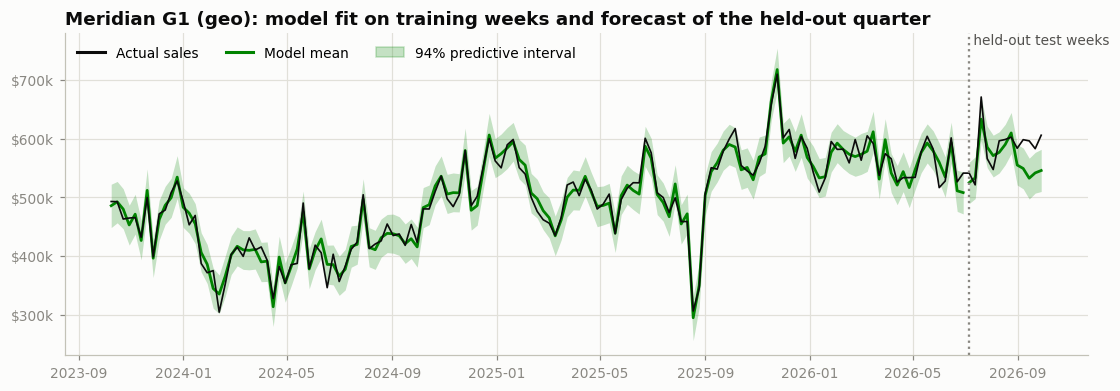

In [53]:
def meridian_predictions(mer: meridian_model.Meridian, pop: np.ndarray, sales_per_person_sd: float) -> dict[str, np.ndarray]:
    """Posterior predictive NATIONAL sales in dollars for training and test weeks: arrays (weeks, samples).

    Meridian returns draws of EXPECTED sales (without observation noise). To make intervals
    comparable with PyMC's posterior predictive we add the noise back. Meridian's `sigma` is the
    noise standard deviation of standardised per-person sales, so the noise of a region's sales in
    dollars is sigma x (std dev of per-person sales) x population, and independent regional noises
    add up in variance.
    """
    analyzer = meridian_analyzer.Analyzer(mer)
    expected = np.asarray(analyzer.expected_outcome(aggregate_geos=True, aggregate_times=False))
    expected = expected.reshape(-1, expected.shape[-1])                     # (samples, weeks)
    sigma = mer.inference_data.posterior["sigma"].to_numpy().reshape(-1, 1)  # (samples, 1)
    national_noise_sd = sigma * sales_per_person_sd * np.sqrt((pop ** 2).sum())
    noise = np.random.default_rng(SEED).normal(0.0, 1.0, size=expected.shape) * national_noise_sd
    predictive = (expected + noise).T                                        # (weeks, samples)
    return {"train": predictive[:N_TRAIN], "test": predictive[N_TRAIN:]}


geo_national_sales = geo_df.groupby("date")["sales"].sum().to_numpy()       # national total of the geo dataset
geo_sales_pp_sd = float(np.std(geo_df["sales"] / geo_df["population"]))

record_fit("Meridian G1 (geo)", meridian_predictions(mer_g1, population, geo_sales_pp_sd),
           actual_train=geo_national_sales[:N_TRAIN], actual_test=geo_national_sales[N_TRAIN:])

accuracy = meridian_analyzer.Analyzer(mer_g1).predictive_accuracy().to_dataframe().reset_index()
accuracy_table = accuracy.pivot_table(index=["geo_granularity", "evaluation_set"], columns="metric", values="value")
print("Meridian's own accuracy report (expected value against actual):")
display(accuracy_table.loc[[("geo", "Train"), ("geo", "Test"), ("national", "Train"), ("national", "Test")]].round(3))

print("National total, same metrics as for the PyMC models:")
display(pd.DataFrame(FIT_ROWS).T.loc[["Meridian G1 (geo)"]].style.format(fit_fmt))
plot_fit("Meridian G1 (geo)", MERIDIAN_COLOR)

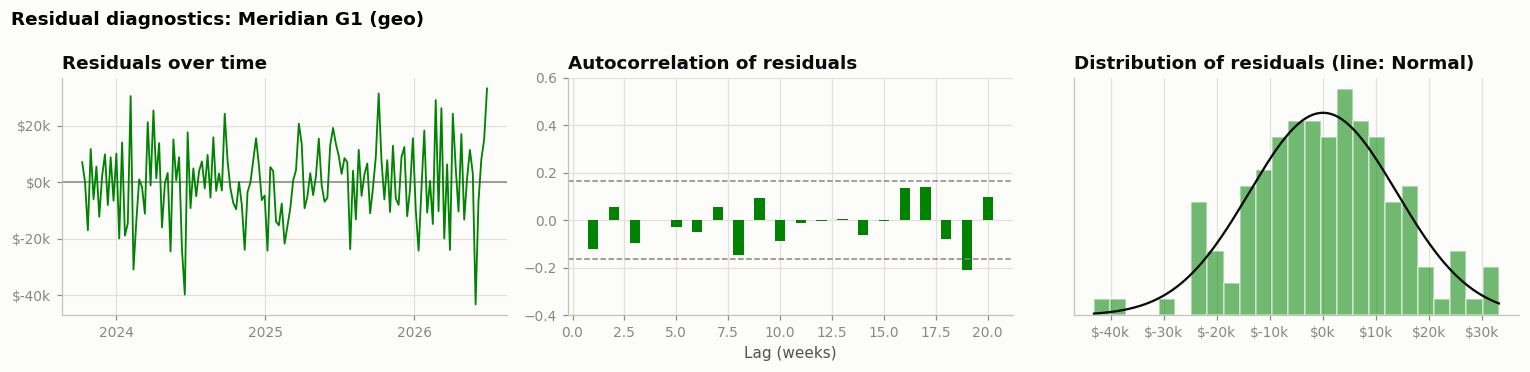

Residual std dev: $13,920   (true noise std dev: $14,000)
Durbin-Watson: 2.20
Ljung-Box test (8 lags): statistic 8.3, p-value 0.403
Shapiro-Wilk normality test: statistic 0.993, p-value 0.694


In [54]:
residual_report("Meridian G1 (geo)", MERIDIAN_COLOR)

**Reading the output.**

* **Region level.** R-squared is about 0.96 on both the training and the held-out weeks, with a typical error of about 10% per region-week. Individual regions are noisy (we built them that way), and most of the variance being explained at this level is the difference in size between regions, which is why R-squared stays high out of sample.
* **National total, training weeks.** R-squared 0.97 and an error of about 2.3%, the same quality of fit as the PyMC models achieved on their national series. Regional errors largely cancel in the total. The residuals of the national total show no significant autocorrelation and no evidence against Normality.
* **National total, held-out weeks.** The error rises to about 5%, R-squared drops to near zero, and only about 60% of the held-out weeks fall inside the 94% predictive interval. The plot shows why: the forecast runs level while actual sales keep rising. The explanation is structural. Beyond the last knot, Meridian's time effect is a flat line: it has no mechanism for continuing a trend or a seasonal pattern into the future. Meridian's documentation is clear that the library is built for causal attribution and not for forecasting, and its recommended holdout scheme is a random sample of region-weeks, not the final weeks. We keep the time-based holdout because it is the stricter test and the same one used in Part VI. If forecasting matters to you, this is a real difference between the two designs: PyMC-Marketing's explicit trend and Fourier seasonality extrapolate, a knot-based time effect does not.

## 7.9 What Meridian learned about each channel

Meridian's `Analyzer` computes ROI as incremental outcome divided by spend, where incremental outcome is the difference between predicted sales with the channel's actual spend and predicted sales with that spend set to zero. For an additive model this is the channel's contribution, so the numbers are directly comparable with the answer key. We sum over regions and restrict the calculation to the training weeks.

,true,median,hdi_3%,hdi_97%,truth inside interval
tv,1.39,1.44,1.20,1.73,True
search,2.56,2.50,1.26,4.18,True
social,1.20,1.64,0.55,2.91,True
display,0.40,0.85,0.09,2.45,True
video,1.81,1.45,0.63,2.47,True


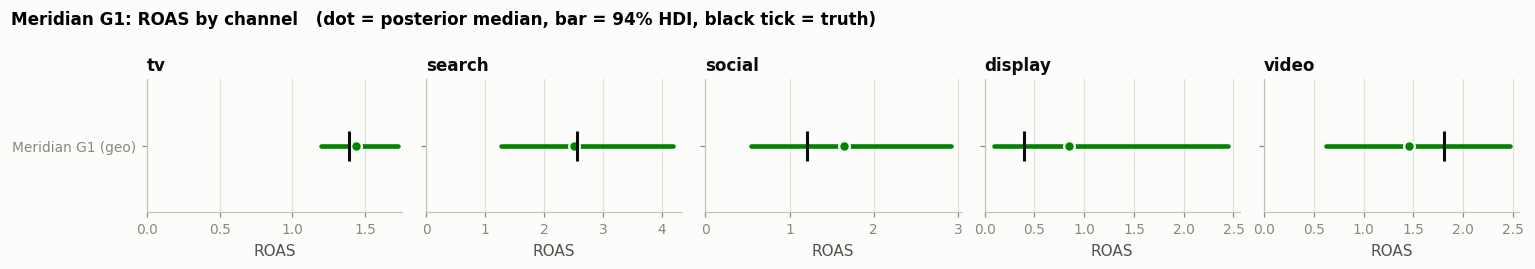

In [55]:
def store_meridian_results(label: str, mer: meridian_model.Meridian, truth_roas: np.ndarray,
                           spend_total: np.ndarray, sales_total: float) -> None:
    """Extract per-draw national weekly contributions (dollars) and ROAS for the training window."""
    analyzer = meridian_analyzer.Analyzer(mer)
    incremental = np.asarray(analyzer.incremental_outcome(aggregate_times=False))   # (chain, draw, week, channel)
    incremental = incremental.reshape(-1, incremental.shape[-2], incremental.shape[-1])[:, :N_TRAIN, :]
    CONTRIB_DRAWS[label] = incremental
    ROAS_DRAWS[label] = incremental.sum(axis=1) / spend_total
    ROAS_TRUTH[label] = truth_roas
    TOTAL_SALES[label] = sales_total


GEO_SALES_TRAIN_TOTAL = float(geo_national_sales[:N_TRAIN].sum())
store_meridian_results("Meridian G1 (geo)", mer_g1, TRUE_ROAS_GEO, GEO_SPEND_TRAIN, GEO_SALES_TRAIN_TOTAL)
display(roas_table("Meridian G1 (geo)").round(2))
plot_roas(["Meridian G1 (geo)"], [MERIDIAN_COLOR], "Meridian G1: ROAS by channel")

**Reading the output.** All five true values lie inside their 94% intervals.

* **TV** is estimated precisely (about 1.44 against a true 1.39).
* **Search** has a median almost exactly on the truth (about 2.5 against 2.56), with a wide interval.
* **Social and video** have medians about 0.4 away from the truth (social too high, video too low) and wide intervals.
* **Display** has a median of about 0.85, double the truth of 0.4. This is the **ROI prior at work**: the data says almost nothing about so small a channel, so the posterior stays in the neighbourhood of the prior median of 1.2. Meridian has not *measured* display; it has reported what it assumed.

The intervals for the digital channels are still wide. Geo data is not magic: the regional series are noisy, and search and social still move together within each region.

### Carry-over

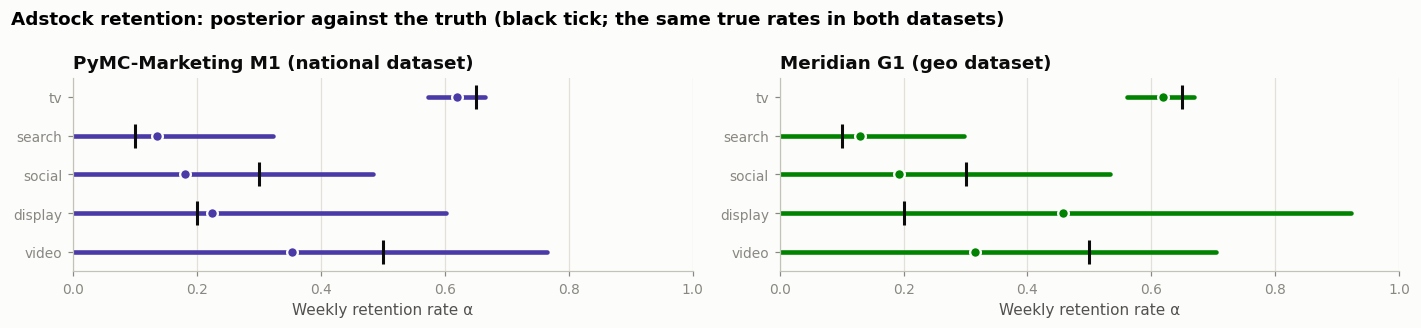

In [56]:
alpha_g1 = mer_g1.inference_data.posterior["alpha_m"].to_numpy().reshape(-1, len(CHANNELS))

fig, axes = plt.subplots(1, 2, figsize=(13, 3), sharex=True)
interval_plot(axes[0], alpha_draws, TRUE_PARAMS["adstock_alpha"], PYMC_COLOR, "Weekly retention rate α")
axes[0].set_title("PyMC-Marketing M1 (national dataset)")
interval_plot(axes[1], alpha_g1, TRUE_PARAMS["adstock_alpha"], MERIDIAN_COLOR, "Weekly retention rate α")
axes[1].set_title("Meridian G1 (geo dataset)")
axes[0].set_xlim(0, 1)
fig.suptitle("Adstock retention: posterior against the truth (black tick; the same true rates in both datasets)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the output.** The true retention rates are the same in both datasets, so the panels can be compared directly. The pattern is the same in both libraries: TV's retention is learned precisely from its flighting; the always-on channels have wide intervals. Meridian's default prior on $\alpha$ is uniform between 0 and 1, whereas we gave PyMC a Beta(1, 3) that favours low values, so where the data is weak (display in particular) Meridian's interval spans almost the whole range. For search, social and video the geo data narrows Meridian's intervals somewhat compared with what a national series allows.

### Response curves

Meridian reports response curves as *total incremental sales over the period* when a channel's whole historical spend pattern is multiplied by a factor (0 = no spend, 1 = what actually happened, 2 = double). We compute the true curve in the same way from the answer key, by pushing scaled regional spend through the true adstock and Hill functions.

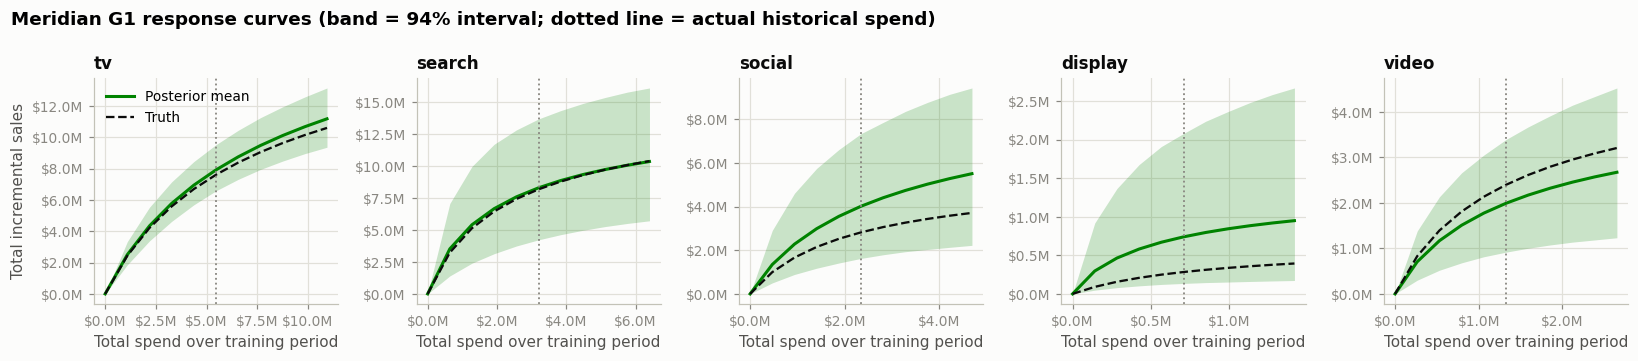

In [57]:
multipliers = np.linspace(0, 2, 11)
response_g1 = meridian_analyzer.Analyzer(mer_g1).response_curves(
    spend_multipliers=multipliers.tolist(), selected_times=train_times, confidence_level=0.94)


def true_geo_total_response(channel_index: int, multiplier: float) -> float:
    """TRUE incremental sales over the training window if the channel's spend were scaled by `multiplier` in every region."""
    total = 0.0
    for g in range(N_GEOS):
        adstocked = geometric_adstock_np(multiplier * spend_per_person[:, g, channel_index],
                                         TRUE_PARAMS["adstock_alpha"][channel_index], L_MAX)
        weekly = (population[g] * GEO_HET[g, channel_index] * GEO_BETA[channel_index]
                  * hill_np(adstocked, GEO_EC[channel_index], GEO_TRUE["slope"][channel_index]))
        total += float(weekly[L_MAX:L_MAX + N_TRAIN].sum())
    return total


def plot_meridian_response(response: xr.Dataset, title: str) -> None:
    """Small multiples: Meridian's response curve per channel against the true curve."""
    fig, axes = plt.subplots(1, len(CHANNELS), figsize=(15, 3.3))
    for ax, (j, ch) in zip(axes, enumerate(CHANNELS)):
        curve = response["incremental_outcome"].sel(channel=ch)
        spend_axis = response["spend"].sel(channel=ch).to_numpy()
        ax.fill_between(spend_axis, curve.sel(metric="ci_lo"), curve.sel(metric="ci_hi"), color=MERIDIAN_COLOR, alpha=0.2, linewidth=0)
        ax.plot(spend_axis, curve.sel(metric="mean"), color=MERIDIAN_COLOR, label="Posterior mean")
        ax.plot(spend_axis, [true_geo_total_response(j, m) for m in multipliers], color=INK, linestyle="--", linewidth=1.5, label="Truth")
        ax.axvline(GEO_SPEND_TRAIN[j], color=MUTED, linestyle=":", linewidth=1.2)
        ax.set_title(ch, fontsize=11)
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M"))
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M"))
        ax.set_xlabel("Total spend over training period")
    axes[0].set_ylabel("Total incremental sales")
    axes[0].legend(loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_meridian_response(response_g1, "Meridian G1 response curves (band = 94% interval; dotted line = actual historical spend)")

**Reading the output.** The model and the data now share the same functional form (Hill with slope 1), and it shows: for TV and search the estimated curve follows the true curve closely over the whole range, including the extrapolation region to the right of the dotted line. For social and video the mean curve is near the truth inside a wide band. For display the mean curve is well above the truth, the response-curve view of the prior-driven ROI seen above. In every panel the true curve is inside the band.

## 7.10 What does geo-level data buy?

To isolate the value of the regional breakdown we throw it away: sum the geo dataset over regions and fit the **same Meridian specification** to the resulting national series (model N1). Same sales, same spend, same truth, same priors, same knots; the only difference is that N1 sees one series where G1 sees twenty.

N1 fitted in 46 seconds.  Convergence: {'max r_hat': 1.01, 'min ess_bulk': 466.0, 'min ess_tail': 517.0, 'divergences': 2}


,true,median,hdi_3%,hdi_97%,truth inside interval
tv,1.39,1.45,1.20,1.73,True
search,2.56,1.41,0.20,2.80,True
social,1.20,1.35,0.12,3.01,True
display,0.40,0.98,0.09,2.89,True
video,1.81,1.66,0.28,3.32,True


,true,N1 median,N1 width,G1 median,G1 width,width change
tv,1.39,1.45,0.53,1.44,0.53,+0%
search,2.56,1.41,2.60,2.50,2.92,+12%
social,1.20,1.35,2.89,1.64,2.37,-18%
display,0.40,0.98,2.80,0.85,2.36,-16%
video,1.81,1.66,3.04,1.45,1.84,-40%


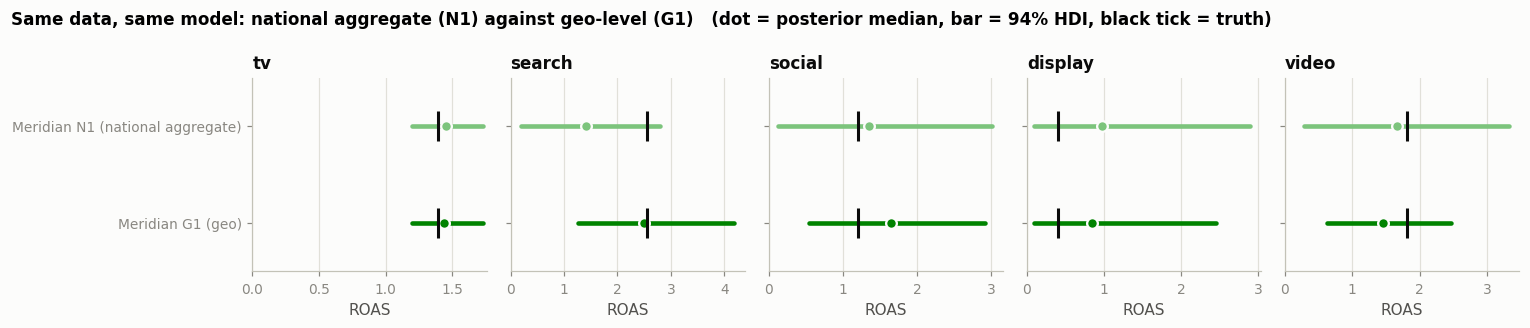

In [58]:
# Aggregate the geo dataset to national level. Sums for sales and spend; a population-weighted
# average for the demand proxy; the calendar controls are identical in every region.
weighted = geo_df.assign(proxy_x_pop=geo_df["demand_proxy"] * geo_df["population"])
national_agg = weighted.groupby("time", as_index=False).agg(
    {**{c: "sum" for c in ["sales"] + CHANNELS + ["proxy_x_pop", "population"]},
     **{c: "first" for c in BASE_CONTROLS}})
national_agg["demand_proxy"] = national_agg["proxy_x_pop"] / national_agg["population"]
national_agg["geo"] = "national"
national_agg["population"] = 1.0

national_holdout = np.zeros(N_OBS, dtype=bool)
national_holdout[N_TRAIN:] = True

mer_n1, seconds_n1 = fit_meridian(build_input_data(national_agg), national_holdout, default_mu, default_sigma)
store_meridian_results("Meridian N1 (national aggregate)", mer_n1, TRUE_ROAS_GEO, GEO_SPEND_TRAIN, GEO_SALES_TRAIN_TOTAL)
record_fit("Meridian N1 (national aggregate)", meridian_predictions(mer_n1, np.array([1.0]), float(np.std(national_agg["sales"]))),
           actual_train=geo_national_sales[:N_TRAIN], actual_test=geo_national_sales[N_TRAIN:])

print(f"N1 fitted in {seconds_n1:.0f} seconds.  Convergence: {meridian_health(mer_n1)}")
display(roas_table("Meridian N1 (national aggregate)").round(2))

geo_value = pd.DataFrame({
    "true": TRUE_ROAS_GEO,
    "N1 median": roas_table("Meridian N1 (national aggregate)")["median"],
    "N1 width": interval_width("Meridian N1 (national aggregate)"),
    "G1 median": roas_table("Meridian G1 (geo)")["median"],
    "G1 width": interval_width("Meridian G1 (geo)"),
})
geo_value["width change"] = geo_value["G1 width"] / geo_value["N1 width"] - 1
display(geo_value.style.format({c: "{:.2f}" for c in geo_value.columns[:-1]} | {"width change": "{:+.0%}"}))
plot_roas(["Meridian N1 (national aggregate)", "Meridian G1 (geo)"], ["#7cc47c", MERIDIAN_COLOR],
          "Same data, same model: national aggregate (N1) against geo-level (G1)")

**Reading the output.** Compare the two models row by row.

* **TV: no change.** Median and interval width are the same in N1 and G1. TV is bought nationally, so the regional breakdown contains no additional information about it. Its precision comes from flighting, which is visible in a national series just as well.
* **Search: the estimate is corrected.** On the national aggregate the median is about 1.4, far below the true 2.56, with the truth only just inside the interval. With regional data the median moves to about 2.5. The interval does not get narrower (it is in fact slightly wider), but it is now centred on the right value. The national model had only one way to separate search from demand, the national demand proxy; the geo model can also compare regions with more and less search per person in the same week.
* **Social, display, video: narrower intervals,** by roughly 15 to 40%. Their medians do not uniformly improve: display moves towards the truth, social and video move a little away from it, all well within their intervals.

Averaged over the five channels, the error of the median falls from about 43% to 35% and the mean interval width from about 2.4 to 2.0.

This is the practical case for geo-level data, stated without exaggeration: it helps where regions differ in media intensity, and not at all where they do not, and with noisy regions the gain is moderate, not dramatic. If you have regional data, use it. If a channel is planned nationally, regional data will not rescue it, and an experiment or deliberate flighting is needed.

## 7.11 Calibration with experiments (model G2)

Meridian calibrates through the **ROI prior**. If an experiment has measured a channel's ROI, you replace that channel's default prior with one centred on the experimental estimate, with a width that reflects the experiment's standard error.

Suppose the experimentation team summarises its geo tests for the three tested channels as an average ROI with a standard error. We simulate those summaries from the true ROAS of the geo dataset with measurement noise. To turn "mean $m$, standard error $s$" into a LogNormal prior we match moments: $\sigma^2 = \ln(1 + s^2/m^2)$ and $\mu = \ln m - \sigma^2/2$.

Note that the two libraries take in experimental evidence in different forms: PyMC-Marketing received five points on the response curves, Meridian receives three average ROIs.

In [59]:
experiment_roi = pd.DataFrame({
    "channel": ["search", "social", "video"],
    "standard_error": [0.30, 0.25, 0.40],
})
experiment_roi["true ROAS (answer key)"] = [TRUE_ROAS_GEO[CHANNELS.index(c)] for c in experiment_roi["channel"]]
experiment_roi["measured_roi"] = experiment_roi["true ROAS (answer key)"] + rng_lift.normal(0, experiment_roi["standard_error"])
display(experiment_roi.round(2))

calibrated_mu, calibrated_sigma = default_mu.copy(), default_sigma.copy()
for _, row in experiment_roi.iterrows():
    j = CHANNELS.index(row["channel"])
    variance = np.log(1 + (row["standard_error"] / row["measured_roi"]) ** 2)   # moment matching
    calibrated_sigma[j] = np.sqrt(variance)
    calibrated_mu[j] = np.log(row["measured_roi"]) - variance / 2

pd.DataFrame({"prior mu": calibrated_mu, "prior sigma": calibrated_sigma,
              "prior median ROI": np.exp(calibrated_mu)}, index=CHANNELS).round(2)

,channel,standard_error,true ROAS (answer key),measured_roi
0,search,0.30,2.56,2.69
1,social,0.25,1.20,1.18
2,video,0.40,1.81,2.01


,prior mu,prior sigma,prior median ROI
tv,0.20,0.90,1.22
search,0.98,0.11,2.67
social,0.14,0.21,1.15
display,0.20,0.90,1.22
video,0.68,0.20,1.97


G2 fitted in 220 seconds.  Convergence: {'max r_hat': 1.01, 'min ess_bulk': 590.0, 'min ess_tail': 997.0, 'divergences': 7}


,true,median,hdi_3%,hdi_97%,truth inside interval
tv,1.39,1.44,1.20,1.74,True
search,2.56,2.75,2.19,3.29,True
social,1.20,1.26,0.86,1.80,True
display,0.40,0.85,0.09,2.32,True
video,1.81,1.86,1.32,2.45,True


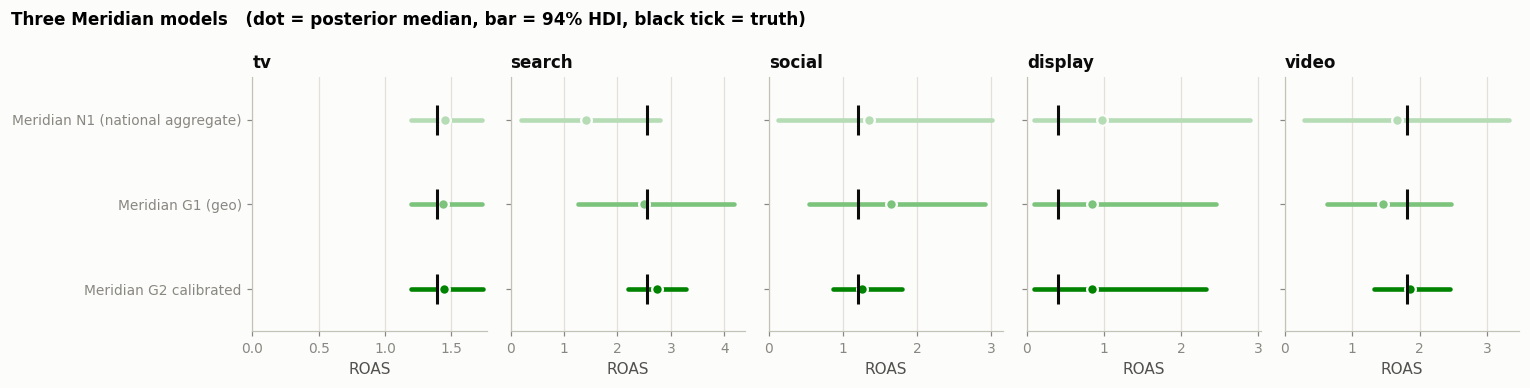

In [60]:
mer_g2, seconds_g2 = fit_meridian(geo_input, geo_holdout, calibrated_mu, calibrated_sigma)
store_meridian_results("Meridian G2 calibrated", mer_g2, TRUE_ROAS_GEO, GEO_SPEND_TRAIN, GEO_SALES_TRAIN_TOTAL)
record_fit("Meridian G2 calibrated", meridian_predictions(mer_g2, population, geo_sales_pp_sd),
           actual_train=geo_national_sales[:N_TRAIN], actual_test=geo_national_sales[N_TRAIN:])

print(f"G2 fitted in {seconds_g2:.0f} seconds.  Convergence: {meridian_health(mer_g2)}")
display(roas_table("Meridian G2 calibrated").round(2))
plot_roas(["Meridian N1 (national aggregate)", "Meridian G1 (geo)", "Meridian G2 calibrated"],
          ["#b5dcb5", "#7cc47c", MERIDIAN_COLOR], "Three Meridian models")

**Reading the output.** The ROI intervals of search, social and video tighten around the experimental values, as they did in PyMC. TV and display, which had no experiment, change little; display's median stays well above the truth: no experiment, no information.

Because Meridian's calibration acts through the prior, the posterior for a calibrated channel is a compromise between the experiment and what the observational data says. When the two agree, the interval narrows. When they disagree, the posterior lands in between and you should investigate why.

The experiments drawn for Meridian happened to land close to the truth (within about half a standard error), while one of PyMC's social tests was nearly two standard errors off. Differences in how well the two *calibrated* models hit the truth are therefore partly luck of the draw, not a property of either library.

In [61]:
for label, mer, secs, key, data_level in [
    ("meridian_G1_geo", mer_g1, seconds_g1, "Meridian G1 (geo)", "geo"),
    ("meridian_G2_geo_calibrated", mer_g2, seconds_g2, "Meridian G2 calibrated", "geo"),
    ("meridian_N1_national_aggregate", mer_n1, seconds_n1, "Meridian N1 (national aggregate)", "national"),
]:
    roas_error = np.abs(np.median(ROAS_DRAWS[key], axis=0) - TRUE_ROAS_GEO) / TRUE_ROAS_GEO
    log_run(label, "google-meridian",
            params={**MERIDIAN_SAMPLER, "target_accept": MERIDIAN_TARGET_ACCEPT, "controls": ",".join(MERIDIAN_CONTROLS),
                    "knots": N_KNOTS, "max_lag": L_MAX, "adstock": "geometric", "saturation": "hill",
                    "data_level": data_level, "n_geos": N_GEOS if data_level == "geo" else 1,
                    "calibrated": key.endswith("calibrated")},
            metrics={**{k.replace(" ", "_"): v for k, v in FIT_ROWS[key].items()},
                     **{k.replace(" ", "_"): v for k, v in meridian_health(mer).items()},
                     "fit_seconds": secs, "mean_abs_pct_error_roas": roas_error.mean()},
            data_hash=GEO_DATA_HASH)
print("Logged 3 runs to MLflow experiment 'mmm-textbook'.")

Logged 3 runs to MLflow experiment 'mmm-textbook'.


---
# Part VIII. Side-by-side comparison

We now have six models and two answer keys.

| Model | Library | Dataset | What distinguishes it |
|---|---|---|---|
| M0 naive | PyMC-Marketing | National (Part IV) | No demand control |
| M1 + demand control | PyMC-Marketing | National | Demand proxy added |
| M2 calibrated | PyMC-Marketing | National | M1 plus five lift tests |
| Meridian N1 | Meridian | Geo dataset summed to national | Default ROI priors, one series |
| Meridian G1 | Meridian | Geo (Section 7.2) | Default ROI priors, 20 regions |
| Meridian G2 calibrated | Meridian | Geo | G1 plus three experimental ROI priors |

**The two libraries were fitted to different datasets**, each generated in that library's own functional form: logistic saturation on a national series for PyMC-Marketing, Hill saturation on regional per-person data for Meridian. The datasets describe the same company and have similar true ROAS values, but they are not the same data. So this part does not answer "which library is more accurate on a given dataset". It answers a different and, for practice, more useful question: *when each library is used in the setting it was designed for, how well does it recover a known truth, and do the same lessons appear in both?*

Every model is graded against the truth of its own dataset.

## 8.1 Recovery of the true ROAS

Three summary numbers per model:

* **Mean absolute percentage error** of the posterior median ROAS against the truth, averaged over the five channels. Lower is better.
* **Coverage**: how many of the five true values fall inside the model's 94% interval. A calibrated model should cover most of them. A model that covers all five only because its intervals are enormous is not useful, so read coverage together with:
* **Mean interval width**: narrower is better, *provided* coverage holds.

PyMC-Marketing models, national dataset: posterior median ROAS


,TRUTH,M0 naive,M1 + demand control,M2 calibrated
tv,1.41,1.26,1.36,1.36
search,2.48,6.04,2.23,2.20
social,1.17,0.94,1.30,0.88
display,0.40,0.52,0.61,0.65
video,1.82,2.28,1.20,1.61


Meridian models, geo dataset: posterior median ROAS


,TRUTH,Meridian N1 (national aggregate),Meridian G1 (geo),Meridian G2 calibrated
tv,1.39,1.45,1.44,1.44
search,2.56,1.41,2.50,2.75
social,1.20,1.35,1.64,1.26
display,0.40,0.98,0.85,0.85
video,1.81,1.66,1.45,1.86


,mean abs % error of median,channels with truth inside 94% interval,mean interval width
M0 naive,46%,4 of 5,2.33
M1 + demand control,22%,5 of 5,2.06
M2 calibrated,23%,4 of 5,1.29
Meridian N1 (national aggregate),43%,5 of 5,2.37
Meridian G1 (geo),35%,5 of 5,2.00
Meridian G2 calibrated,26%,5 of 5,1.19


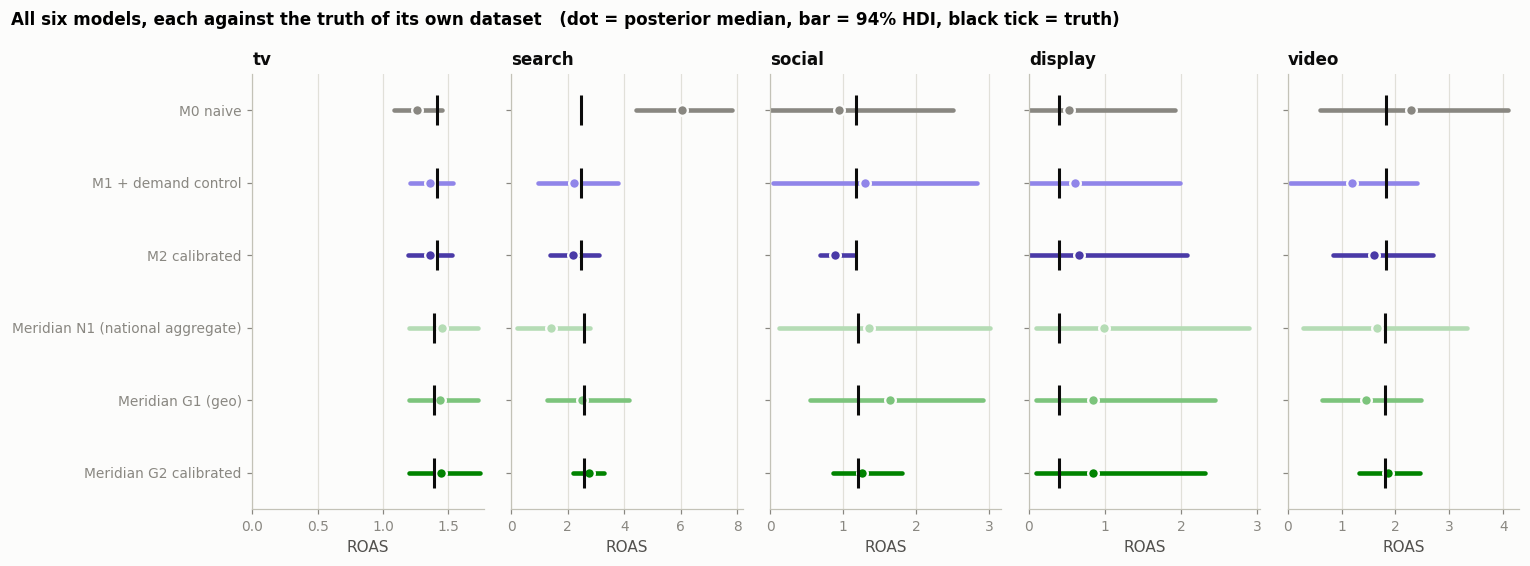

In [62]:
PYMC_MODELS: list[str] = ["M0 naive", "M1 + demand control", "M2 calibrated"]
MERIDIAN_MODELS: list[str] = ["Meridian N1 (national aggregate)", "Meridian G1 (geo)", "Meridian G2 calibrated"]
ALL_MODELS: list[str] = PYMC_MODELS + MERIDIAN_MODELS
ALL_COLORS: list[str] = [MUTED, "#9085e9", PYMC_COLOR, "#b5dcb5", "#7cc47c", MERIDIAN_COLOR]

for title, models, truth_values in [
    ("PyMC-Marketing models, national dataset: posterior median ROAS", PYMC_MODELS, TRUE_ROAS),
    ("Meridian models, geo dataset: posterior median ROAS", MERIDIAN_MODELS, TRUE_ROAS_GEO),
]:
    medians = pd.DataFrame({label: np.median(ROAS_DRAWS[label], axis=0) for label in models}, index=CHANNELS)
    medians.insert(0, "TRUTH", truth_values)
    print(title)
    display(medians.round(2))

recovery = pd.DataFrame({
    label: {
        "mean abs % error of median": float(np.mean(np.abs(np.median(ROAS_DRAWS[label], axis=0) - ROAS_TRUTH[label]) / ROAS_TRUTH[label])),
        "channels with truth inside 94% interval": int(roas_table(label)["truth inside interval"].sum()),
        "mean interval width": float(interval_width(label).mean()),
    } for label in ALL_MODELS
}).T
display(recovery.style.format({"mean abs % error of median": "{:.0%}", "channels with truth inside 94% interval": "{:.0f} of 5",
                               "mean interval width": "{:.2f}"}))

plot_roas(ALL_MODELS, ALL_COLORS, "All six models, each against the truth of its own dataset")

## 8.2 Predictive accuracy

All rows refer to the national weekly total (for the geo models, the sum of the regional predictions).

In [63]:
display(pd.DataFrame(FIT_ROWS).T.loc[ALL_MODELS].style.format(fit_fmt))

,train R2,train MAPE,train coverage,test R2,test MAPE,test coverage
M0 naive,0.952,3.3%,97%,0.869,1.8%,100%
M1 + demand control,0.972,2.5%,97%,0.766,2.3%,92%
M2 calibrated,0.972,2.5%,97%,0.737,2.4%,92%
Meridian N1 (national aggregate),0.970,2.2%,97%,0.177,4.7%,69%
Meridian G1 (geo),0.968,2.3%,99%,0.038,5.0%,62%
Meridian G2 calibrated,0.968,2.3%,99%,0.044,5.0%,62%


## 8.3 How much of sales is media?

Budget holders often ask a blunter question than ROAS by channel: *how much of our sales is due to advertising at all?* This total is usually better identified than the split between channels, because collinear channels trade off against each other while their sum stays stable.

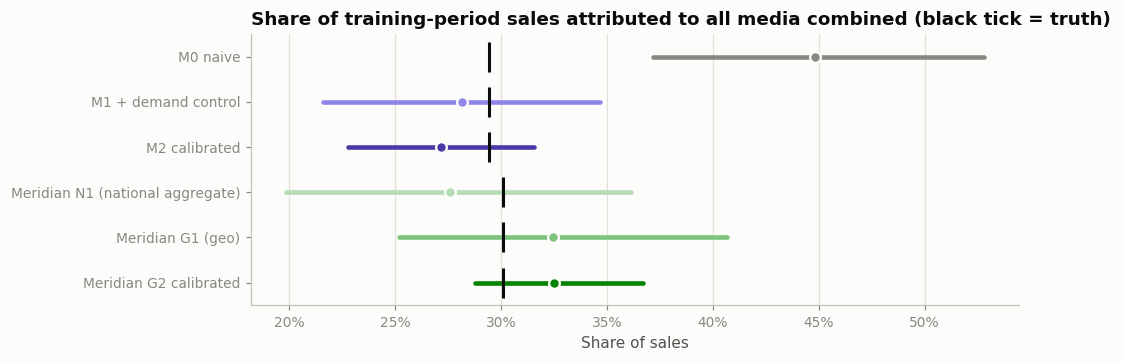

,true share,estimated share (mean),hdi_3%,hdi_97%
M0 naive,29.4%,44.8%,37.2%,52.8%
M1 + demand control,29.4%,28.2%,21.6%,34.7%
M2 calibrated,29.4%,27.2%,22.8%,31.6%
Meridian N1 (national aggregate),30.1%,27.6%,19.9%,36.1%
Meridian G1 (geo),30.1%,32.5%,25.2%,40.7%
Meridian G2 calibrated,30.1%,32.5%,28.8%,36.7%


In [64]:
TRUE_MEDIA_SHARE: dict[str, float] = {
    **{label: float(TRUE_CONTRIB_TRAIN.sum() / TOTAL_SALES[label]) for label in PYMC_MODELS},
    **{label: float(TRUE_CONTRIB_GEO_TRAIN.sum() / TOTAL_SALES[label]) for label in MERIDIAN_MODELS},
}
total_share = {}
for label in ALL_MODELS:
    draws = CONTRIB_DRAWS[label].sum(axis=(1, 2)) / TOTAL_SALES[label]
    lo, hi = az.hdi(draws, hdi_prob=0.94)
    total_share[label] = {"true share": TRUE_MEDIA_SHARE[label], "estimated share (mean)": draws.mean(), "hdi_3%": lo, "hdi_97%": hi}

fig, ax = plt.subplots(figsize=(9, 3.2))
for row, (label, color) in enumerate(zip(ALL_MODELS, ALL_COLORS)):
    s = total_share[label]
    ax.plot([s["hdi_3%"], s["hdi_97%"]], [row, row], color=color, linewidth=3, solid_capstyle="round")
    ax.plot(s["estimated share (mean)"], row, "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.plot(s["true share"], row, "|", color=INK, markersize=20, markeredgewidth=2)
ax.set_yticks(range(len(ALL_MODELS)), ALL_MODELS)
ax.set_ylim(len(ALL_MODELS) - 0.5, -0.5)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.set(title="Share of training-period sales attributed to all media combined (black tick = truth)", xlabel="Share of sales")
plt.show()
display(pd.DataFrame(total_share).T.style.format("{:.1%}"))

## 8.4 Computational cost

**ESS per second** is the fairest speed measure for MCMC: it is the number of effectively independent samples produced per second of wall-clock time, here for the worst-mixing parameter. Raw seconds alone can mislead, because a sampler that is fast but produces highly correlated draws has done less useful work. The geo models process twenty times as many observations and estimate several times as many parameters as the national ones, so their times are not comparable with the national rows like for like.

In [65]:
cost = pd.DataFrame({
    "M0 naive": {**mcmc_health(mmm_m0), "seconds": seconds_m0, "observations": N_TRAIN},
    "M1 + demand control": {**mcmc_health(mmm_m1), "seconds": seconds_m1, "observations": N_TRAIN},
    "M2 calibrated": {**mcmc_health(mmm_m2), "seconds": seconds_m2, "observations": N_TRAIN},
    "Meridian N1 (national aggregate)": {**meridian_health(mer_n1), "seconds": seconds_n1, "observations": N_TRAIN},
    "Meridian G1 (geo)": {**meridian_health(mer_g1), "seconds": seconds_g1, "observations": N_TRAIN * N_GEOS},
    "Meridian G2 calibrated": {**meridian_health(mer_g2), "seconds": seconds_g2, "observations": N_TRAIN * N_GEOS},
}).T
cost["min ESS per second"] = cost["min ess_bulk"] / cost["seconds"]
display(cost.style.format({"max r_hat": "{:.3f}", "min ess_bulk": "{:,.0f}", "min ess_tail": "{:,.0f}", "divergences": "{:.0f}",
                           "seconds": "{:.0f}", "observations": "{:,.0f}", "min ESS per second": "{:.1f}"}))

,max r_hat,min ess_bulk,min ess_tail,divergences,seconds,observations,min ESS per second
M0 naive,1.010,"1,711","1,243",1,91,143,18.8
M1 + demand control,1.000,"1,656","1,383",0,98,143,16.9
M2 calibrated,1.000,"2,228","1,656",0,86,143,25.9
Meridian N1 (national aggregate),1.010,466,517,2,46,143,10.0
Meridian G1 (geo),1.010,406,664,1,244,"2,860",1.7
Meridian G2 calibrated,1.010,590,997,7,220,"2,860",2.7


## 8.5 What the comparison shows

**1. Controlling for the confounder mattered more than anything else.** On the national dataset, moving from M0 to M1 by adding one control column halved the average error of the ROAS estimates (from about 46% to about 22%) and brought the estimated media share of sales from 45% down to 28%, against a true 29%. No choice of prior or sampler setting had an effect of that size. The most valuable hour in an MMM project is the one spent asking what drives each channel's budget.

**2. Fit statistics did not reveal the problem.** M0, the model with the badly biased search estimate, has the *best* forecast error of all six models on the held-out quarter. Section 6.7 explains why.

**3. Regional data helped where regions differed.** The same Meridian model had an average error of about 43% on the national aggregate (N1) and about 35% on the regional data (G1), with narrower intervals, and the largest single improvement was the correction of the search estimate. It added nothing for TV, which is bought nationally.

**4. Calibration bought precision in both libraries.** The mean interval width fell from about 2.1 to 1.3 for PyMC-Marketing and from about 2.0 to 1.2 for Meridian. Whether the *centre* improved depended on the experiments. Meridian's error fell (35% to 26%) because its three experiments landed near the truth. PyMC-Marketing's stayed the same (22% and 23%) because one noisy social test pulled that channel away from the truth and just outside its now much narrower interval. Experiments are evidence with their own error bars.

**5. The same channels were hard in both settings.** TV, with clean on/off variation, is estimated within a few percent by every model that includes the demand control. Display, with a small budget, is not measured by any model: the medians (about 0.6 for PyMC-Marketing, about 0.85 for Meridian, against a true 0.4) mainly reflect each library's prior, and every interval is wide enough to say "we do not know". Search and social are hard to separate until an experiment breaks the tie. What makes a channel measurable is the variation in its spend, not the software.

**6. The total is better identified than the split.** Every model with the demand control has the true total media share inside its interval.

**7. Do not rank the libraries from these tables.** They were fitted to different datasets, each in its own functional form, with different experimental evidence. What the tables do show is that both, used in their intended setting with sound controls, recover a known truth to a broadly similar degree: uncalibrated errors of roughly 20 to 35% on channel ROAS medians, 5 of 5 truths inside the intervals, and calibrated intervals about 40% narrower.

**8. Forecasting differs by design.** On held-out weeks the PyMC-Marketing models were within about 2% and the Meridian models within about 5%, with poor interval coverage, because a knot-based time effect does not extrapolate (Section 7.8). This is a property of how each model represents time, and it would reverse nobody's attribution results.

**9. Cost.** National models fit in under two minutes in either library. The geo model, with twenty times the data and a parameter set per region, took about four minutes on a CPU; Meridian's JAX backend can use a GPU, which matters for hundreds of regions. Meridian needed non-default sampler settings to sample cleanly, and its effective sample sizes were lower than PyMC's, though adequate.

---
# Part IX. From model to decision: budget optimisation

## 9.1 The idea

A fitted MMM contains a response curve for every channel. Budget optimisation asks: *for a fixed total budget, which split across channels gives the largest total media contribution?*

The principle is to move money from channels where the next dollar earns little to channels where it earns more, until the **marginal returns are equal** everywhere (or a constraint stops you). Saturation is what makes this well-posed: as you add money to a channel its marginal return falls, so there is an interior optimum.

**Constraints are essential.** An unconstrained optimiser will happily recommend spending ten times the historical maximum on some channel, a region where the response curve is pure extrapolation. Standard practice is to keep each channel within a band around its recent spend. We use plus or minus 30%.

**The scenario.** Plan a typical week of the coming quarter. The total weekly budget equals the average weekly spend of the last 52 training weeks. Each channel may move up or down by at most 30% from its own recent average. We run the exercise twice: with PyMC-Marketing on the national dataset and with Meridian on the geo dataset. National budgets are almost the same in the two datasets, so the starting allocations nearly coincide.

In [66]:
recent = train_df[CHANNELS].tail(52)
current_weekly = recent.mean().to_numpy()                  # current average weekly spend per channel
weekly_budget = float(current_weekly.sum())
lower, upper = 0.7 * current_weekly, 1.3 * current_weekly

print(f"Weekly budget to allocate (national dataset): ${weekly_budget:,.0f}")
pd.DataFrame({"current weekly spend": current_weekly, "lower bound": lower, "upper bound": upper}, index=CHANNELS).round(0)

Weekly budget to allocate (national dataset): $97,782


,current weekly spend,lower bound,upper bound
tv,34537.0,24176.0,44898.0
search,24480.0,17136.0,31824.0
social,17812.0,12468.0,23155.0
display,4466.0,3126.0,5805.0
video,16487.0,11541.0,21433.0


## 9.2 Optimising with PyMC-Marketing

`MultiDimensionalBudgetOptimizerWrapper` wraps a fitted model for a future time window. `optimize_budget` takes the budget per period and optional per-channel bounds, and maximises the posterior mean of total media contribution. We use the calibrated model M2.

In [67]:
optimizer_pymc = MultiDimensionalBudgetOptimizerWrapper(
    model=mmm_m2,
    start_date=str(test_df["date"].iloc[0].date()),
    end_date=str(test_df["date"].iloc[-1].date()),
)
budget_bounds = xr.DataArray(
    np.stack([lower, upper], axis=1),
    dims=["channel", "bound"],
    coords={"channel": CHANNELS, "bound": ["lower", "upper"]},
)
allocation_pymc_xr, optimisation_result = optimizer_pymc.optimize_budget(budget=weekly_budget, budget_bounds=budget_bounds)
allocation_pymc = allocation_pymc_xr.sel(channel=CHANNELS).to_numpy()
print(f"Optimiser converged: {optimisation_result.success}.  Allocated ${allocation_pymc.sum():,.0f} of ${weekly_budget:,.0f} per week.")

Optimiser converged: True.  Allocated $97,782 of $97,782 per week.


## 9.3 Optimising with Meridian

Meridian's `BudgetOptimizer` works on a historical window: it takes the spend pattern of the selected period, including how each channel's budget was distributed across regions and weeks, and asks how the same total should have been split between channels. We select the last 52 training weeks of the geo dataset, keep the budget fixed and allow each channel to move by 30%. We use the calibrated model G2 and convert the result to an average week.

In [68]:
recent_geo_spend = geo_spend[obs][N_TRAIN - 52:N_TRAIN]                      # (52 weeks, regions, channels)
current_weekly_geo = recent_geo_spend.sum(axis=1).mean(axis=0)               # national weekly spend per channel
weekly_budget_geo = float(current_weekly_geo.sum())
lower_geo, upper_geo = 0.7 * current_weekly_geo, 1.3 * current_weekly_geo

optimizer_meridian = meridian_optimizer.BudgetOptimizer(mer_g2)
meridian_result = optimizer_meridian.optimize(
    start_date=train_times[-52],
    end_date=train_times[-1],
    fixed_budget=True,
    spend_constraint_lower=0.3,
    spend_constraint_upper=0.3,
)
optimised_share = meridian_result.optimized_data["spend"].sel(channel=CHANNELS).to_numpy()
optimised_share = optimised_share / optimised_share.sum()
allocation_meridian = optimised_share * weekly_budget_geo
print(f"Weekly budget to allocate (geo dataset): ${weekly_budget_geo:,.0f}.  Allocated ${allocation_meridian.sum():,.0f}.")

Weekly budget to allocate (geo dataset): $101,757.  Allocated $101,757.


## 9.4 Grading the recommendations against the truth

On a real project you would implement the recommendation and hope. Here we can do what is never possible in practice: evaluate each plan under the **true** response curves of its dataset. We also compute the plan that an all-knowing planner would choose, by optimising the true curves under the same constraints.

For the grading we use the steady-state weekly response: the contribution a channel settles at when its weekly spend is held constant. (With normalised adstock, constant spend gives constant adstocked spend, so this is simply the saturation curve.) For the geo dataset, a national weekly budget for a channel is split across regions in the same proportions as in the last 52 weeks, and each region responds through its own true Hill curve.

Recommended change in weekly spend relative to current


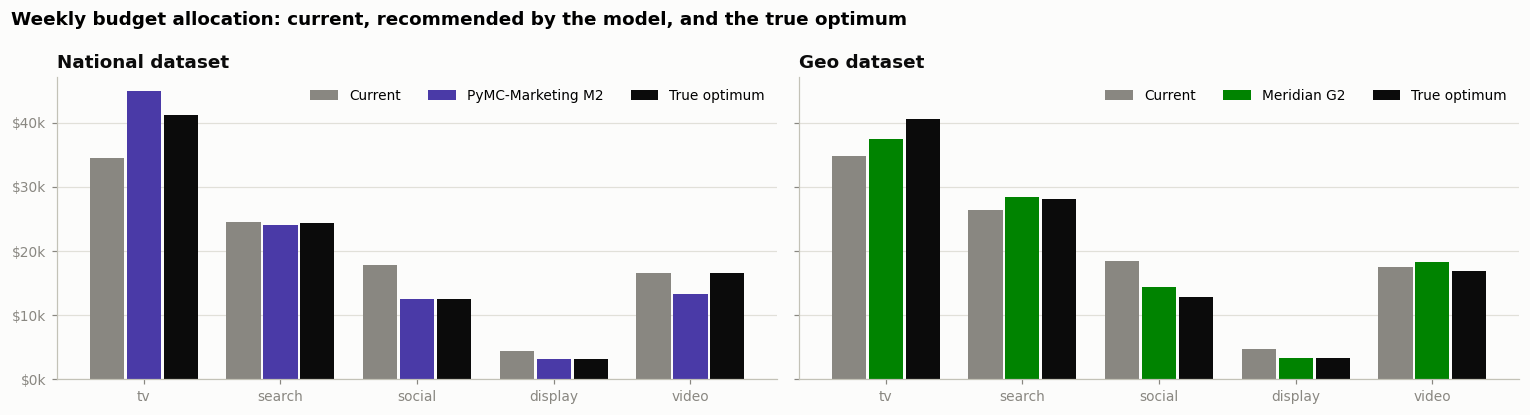

National dataset (PyMC-Marketing M2)


,true weekly media sales,gain vs current ($/week),gain vs current (%),share of achievable gain captured
Current,"$162,298",$0,+0.00%,0%
Model recommendation,"$165,200","$2,902",+1.79%,87%
True optimum,"$165,629","$3,331",+2.05%,100%


Geo dataset (Meridian G2)


,true weekly media sales,gain vs current ($/week),gain vs current (%),share of achievable gain captured
Current,"$174,656",$0,+0.00%,0%
Model recommendation,"$176,797","$2,141",+1.23%,86%
True optimum,"$177,147","$2,491",+1.43%,100%


In [69]:
from scipy.optimize import minimize


def true_weekly_media_sales(allocation: np.ndarray) -> float:
    """National dataset: TRUE steady-state weekly media contribution (dollars) for a weekly allocation."""
    return float(sum(true_response(j, np.array([allocation[j]]))[0] for j in range(len(CHANNELS))))


GEO_RECENT_SHARE = recent_geo_spend.sum(axis=0) / recent_geo_spend.sum(axis=(0, 1))   # (regions, channels)


def true_geo_weekly_media_sales(allocation: np.ndarray) -> float:
    """Geo dataset: TRUE steady-state weekly media contribution (dollars) for a national weekly allocation."""
    per_person = allocation[None, :] * GEO_RECENT_SHARE / population[:, None]
    response = population[:, None] * GEO_HET * GEO_BETA[None, :] * hill_np(per_person, GEO_EC[None, :], GEO_TRUE["slope"][None, :])
    return float(response.sum())


def best_possible_allocation(value_fn, start: np.ndarray, lo: np.ndarray, hi: np.ndarray, budget: float) -> np.ndarray:
    """The allocation that maximises the TRUE response under the same budget and bounds."""
    result = minimize(lambda a: -value_fn(a), x0=start, bounds=list(zip(lo, hi)),
                      constraints=[{"type": "eq", "fun": lambda a: a.sum() - budget}], method="SLSQP")
    return result.x


def grade_plans(plans: dict[str, np.ndarray], value_fn) -> pd.DataFrame:
    """Value each plan under the true response and express its gain relative to the best achievable gain."""
    base = value_fn(plans["Current"])
    best_gain = value_fn(plans["True optimum"]) - base
    return pd.DataFrame({
        name: {
            "true weekly media sales": value_fn(alloc),
            "gain vs current ($/week)": value_fn(alloc) - base,
            "gain vs current (%)": value_fn(alloc) / base - 1,
            "share of achievable gain captured": (value_fn(alloc) - base) / best_gain,
        } for name, alloc in plans.items()
    }).T


plans_national = {
    "Current": current_weekly,
    "Model recommendation": allocation_pymc,
    "True optimum": best_possible_allocation(true_weekly_media_sales, current_weekly, lower, upper, weekly_budget),
}
plans_geo = {
    "Current": current_weekly_geo,
    "Model recommendation": allocation_meridian,
    "True optimum": best_possible_allocation(true_geo_weekly_media_sales, current_weekly_geo, lower_geo, upper_geo, weekly_budget_geo),
}

change = pd.DataFrame({
    ("National dataset", "PyMC-Marketing M2"): plans_national["Model recommendation"] / plans_national["Current"] - 1,
    ("National dataset", "True optimum"): plans_national["True optimum"] / plans_national["Current"] - 1,
    ("Geo dataset", "Meridian G2"): plans_geo["Model recommendation"] / plans_geo["Current"] - 1,
    ("Geo dataset", "True optimum"): plans_geo["True optimum"] / plans_geo["Current"] - 1,
}, index=CHANNELS)
print("Recommended change in weekly spend relative to current")
display(change.style.format("{:+.0%}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
bar_width = 0.25
for ax, plans, model_name, model_color, title in [
    (axes[0], plans_national, "PyMC-Marketing M2", PYMC_COLOR, "National dataset"),
    (axes[1], plans_geo, "Meridian G2", MERIDIAN_COLOR, "Geo dataset"),
]:
    for k, (name, color) in enumerate([("Current", MUTED), ("Model recommendation", model_color), ("True optimum", INK)]):
        label = model_name if name == "Model recommendation" else name
        ax.bar(np.arange(len(CHANNELS)) + (k - 1) * (bar_width + 0.02), plans[name], width=bar_width, color=color, label=label)
    ax.set_xticks(range(len(CHANNELS)), CHANNELS)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    thousands(ax)
    ax.legend(ncol=3, loc="upper right")
fig.suptitle("Weekly budget allocation: current, recommended by the model, and the true optimum", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

grade_fmt = {"true weekly media sales": "${:,.0f}", "gain vs current ($/week)": "${:,.0f}",
             "gain vs current (%)": "{:+.2%}", "share of achievable gain captured": "{:.0%}"}
print("National dataset (PyMC-Marketing M2)")
display(grade_plans(plans_national, true_weekly_media_sales).style.format(grade_fmt))
print("Geo dataset (Meridian G2)")
display(grade_plans(plans_geo, true_geo_weekly_media_sales).style.format(grade_fmt))

## 9.5 What the optimisation shows

**Both models point in the right direction.** In both datasets the true optimum, under these constraints, is to cut social and display to their lower bounds and move the money mainly into TV. Both models recommend cutting social and display and raising TV.

**Each plan deviates from the optimum in ways that trace back to estimation results.**

* PyMC-Marketing (national dataset) pushes TV to its upper bound (+30%, where +19% is optimal) and cuts video by about a fifth, where the optimum keeps it. It had underestimated video's return.
* Meridian (geo dataset) is more cautious than the optimum on TV (+8% where +17% is optimal), does not cut social all the way, and nudges video up where the optimum trims it slightly. Its uncalibrated social estimate had been high, and the calibrated one is still a little above the truth.

**The gains are modest and that is normal.** The best possible reallocation within a 30% band raises media-driven sales by about 2% in the national dataset and 1.4% in the geo dataset: roughly \$2,500 to \$3,300 a week, or \$130,000 to \$170,000 a year, for no extra spend. Each model's plan captures between 85% and 90% of the gain achievable in its dataset. **Imperfect models produced plans that beat the current allocation**, because the direction of the main moves was right even though individual ROAS estimates were off by 20% or more. The reason is that near an optimum the payoff is flat: being roughly right about which channels are over- and under-funded captures most of the value.

**How to act on a result like this.** Move in the recommended direction but less far than the optimiser says; treat the largest shifts as experiments and measure them; and re-estimate after the change, since the new spend levels supply the variation that the model lacked.

Three caveats specific to this exercise. The grading uses steady-state weekly responses, which ignores TV's flighting pattern. The two optimisers were set up differently (a uniform future quarter for PyMC-Marketing, the historical 52-week regional pattern for Meridian). And the optimisers maximise the posterior *mean* response; a risk-averse planner would also look at the spread, which both libraries can report.

---
# Part X. Practices to carry into real projects

## 10.1 A workflow checklist

This is the sequence we followed, written as a checklist. Each item names the section where it was demonstrated.

**Before modelling**

1. **Define the decision.** What will change depending on the answer? (1.1)
2. **Audit the data.** Shape, types, time gaps, missing values, zeros. Decide explicitly how to treat each problem and record it. (5.1)
3. **Explain outliers; do not delete them.** Add indicators for confirmed events. (5.3)
4. **Look at correlations and VIF.** Know in advance which channels the data cannot separate. (5.6)
5. **List the confounders.** For each channel ask: what drives its budget, and does that also drive sales? Find a control or proxy. (1.2, 6.6, 6.7)
6. **Use regional data if you have it,** and check how much each channel's intensity actually varies across regions. (7.3, 7.10)
7. **Fit a simple baseline.** It gives you a number to beat and a first warning of problems. (5.7)

**Modelling**

8. **Choose priors deliberately and write down why.** (6.2, 7.1, 7.5)
9. **Run a prior predictive check.** (6.3)
10. **Hold out the most recent period.** Split by time, never at random, and compute any scaling from the training data only. (5.4)
11. **Fit with several chains.** (6.4, 7.6)

**After fitting**

12. **Check convergence first:** R-hat, ESS, divergences, trace plots. Do not read results from a model that has not converged. (6.5, 7.7)
13. **Check the fit:** in-sample and out-of-sample accuracy, interval coverage. (6.7, 7.8)
14. **Check the residuals:** pattern over time, autocorrelation, shape. (6.8)
15. **Report intervals, not just point estimates.** A wide interval is a finding. (6.7)
16. **Run a prior sensitivity analysis** and state which conclusions depend on the priors. (6.11)
17. **Calibrate with experiments** wherever they exist, and plan experiments for the channels with the widest intervals. (6.10, 7.11)
18. **Remember that fit does not validate attribution.** (5.7, 6.7)

**Decisions**

19. **Optimise with constraints** that keep spend near the range of the data. (9.1)
20. **Treat recommendations as hypotheses.** Make moderate changes, then measure the result, ideally with an experiment. (9.5)
21. **Track every run:** settings, seed, data version, metrics. (0.3)

**In production**, add: refit on a schedule as new data arrives; compare each new model against the current one before replacing it; monitor forecast error over time and whether ROAS estimates drift between refits; and keep the data pipeline versioned so that any past result can be reproduced.

## 10.2 Limits of this study

* **The data is synthetic, and each library was fitted to data generated in its own functional form.** PyMC-Marketing fitted geometric adstock and logistic saturation to a national series generated exactly that way; Meridian fitted geometric adstock and Hill saturation to regional data generated exactly that way. Both are therefore *well-specified*, which real data never allows. Expect larger errors in practice.
* **The two libraries saw different datasets.** This notebook shows how each behaves in its intended setting. It is not a head-to-head benchmark, and no ranking of the libraries should be read into the tables of Part VIII. A benchmark would fit both libraries to the same datasets, of both kinds.
* **One dataset of each kind, one seed.** A proper study repeats the exercise over many simulated datasets and reports the distribution of errors. Differences of a few percentage points between models here are within what a different random draw could produce.
* **The calibrated models were given different evidence** (response-curve points for PyMC-Marketing, average ROIs for Meridian), each with its own measurement noise.
* **True effects were constant over time.** Real channel effectiveness drifts with creative quality, competition and audience fatigue. Both libraries offer time-varying extensions that we did not use.
* **Additivity was true by construction.** Real channels interact (TV drives search queries, for example). An additive model credits such sales to whichever channel is closest to the purchase.
* **Regional structure was simple.** Regions shared the same seasonality, prices and calendar, differed only in level, noise and media mix, and did not influence each other. Real regions differ in seasonality and have spill-overs (people commute, media markets overlap).
* **The geo dataset skipped the data-quality problems** (missing values, undetected outliers) that the national dataset contained; we reused the conclusions of Part V.
* **The models were graded on the training window.** We did not refit on the full 156 weeks after validation, which is what you would do before using a model for planning.
* **Cross-validation used a single split.** Rolling-origin (time-slice) cross-validation over several cut-off dates gives a more reliable picture of forecast accuracy; PyMC-Marketing provides `TimeSliceCrossValidator` for this.

## 10.3 Choosing between the libraries

Both are capable, actively developed, open-source Bayesian MMM libraries built on NUTS. The differences that matter in practice:

| If you... | Consider |
|---|---|
| have geo-level data and want a guided, opinionated workflow with built-in reporting | **Meridian** |
| think about channels in terms of ROI and have experiments expressed as ROI | **Meridian** (ROI priors) |
| have reach and frequency data (for example YouTube) | **Meridian** (reach/frequency modelling) |
| want to choose and combine components freely: adstock and saturation families, Fourier seasonality, trends, Gaussian-process time-varying effects, custom likelihoods | **PyMC-Marketing** |
| want to calibrate to lift tests at specific spend levels | **PyMC-Marketing** (lift-test likelihood) |
| need to extend the model with your own PyMC code | **PyMC-Marketing** |

PyMC-Marketing can also fit geo-level (panel) data, through the `dims` argument of the same `MMM` class, and Meridian can fit national data, as model N1 showed; the table describes where each is most at home, not what each is limited to. A defensible practice for an important decision is to fit both to the same data. Where they agree, confidence is warranted. Where they disagree, you have found the channels whose answer depends on modelling assumptions, which is exactly where an experiment is worth its cost.

## 10.4 Glossary

| Term | Meaning |
|---|---|
| **Adstock** | Transformation that spreads the effect of advertising over later periods. |
| **Baseline** | Sales that would occur without any media: intercept, trend, seasonality and controls. |
| **Calibration** | Using experimental results to constrain an MMM. |
| **Chain** | One independent run of an MCMC sampler. |
| **Confounder** | A variable that affects both the treatment (spend) and the outcome (sales), creating a spurious association. |
| **Contribution** | The part of sales attributed to a channel. |
| **Control variable** | A non-media variable included to account for its effect on sales. |
| **Credible interval** | A range containing the unknown with stated posterior probability. |
| **Divergence** | A warning from the NUTS sampler that it failed to explore a region accurately. |
| **`do` operator** | Sets a model variable to a fixed value; used here to simulate from known parameters. |
| **ESS (effective sample size)** | The number of independent draws that the correlated MCMC draws are worth. |
| **Flighting** | Running advertising in bursts separated by pauses. |
| **Fourier terms** | Sine and cosine waves used to model smooth seasonality. |
| **HDI (highest density interval)** | The narrowest credible interval for a given probability. |
| **Hill function** | An S-shaped or concave saturation curve with half-saturation point `ec` and slope. |
| **Holdout** | Data kept out of fitting, used to test predictions. |
| **Incrementality** | Sales caused by marketing that would not have happened otherwise. |
| **Knots** | Points in time where Meridian estimates the baseline level, interpolating in between. |
| **Lift test** | A randomised experiment measuring the causal effect of a change in spend. |
| **Likelihood** | The probability of the observed data given the parameters. |
| **MAPE** | Mean absolute percentage error. |
| **Marginal ROAS (mROAS)** | Return on the next dollar spent. |
| **MCMC** | Markov chain Monte Carlo: algorithms that draw samples from a posterior distribution. |
| **Multicollinearity** | Strong correlation among predictors, making their separate effects hard to estimate. |
| **NUTS** | The No-U-Turn Sampler, the efficient MCMC algorithm used by both libraries. |
| **Omitted-variable bias** | Bias from leaving a confounder out of the model. |
| **Posterior** | The distribution of the parameters after combining prior and data. |
| **Posterior predictive check** | Comparing data simulated from the fitted model with the observed data. |
| **Prior** | The distribution expressing beliefs about parameters before seeing the data. |
| **Prior predictive check** | Simulating data from the priors alone to check they are sensible. |
| **R-hat** | Convergence diagnostic comparing chains; should be close to 1. |
| **ROAS / ROI** | Incremental sales per dollar of spend. (Strictly, ROI subtracts the cost; in MMM practice, including Meridian, both words are used for the ratio.) |
| **Saturation** | Diminishing returns to additional spend. |
| **VIF** | Variance inflation factor, a measure of multicollinearity. |
| **Warm-up (tuning, burn-in)** | Initial MCMC steps, discarded, during which the sampler adapts. |

## 10.5 Further reading

* Jin, Wang, Sun, Chan and Koehler (2017), *Bayesian Methods for Media Mix Modeling with Carryover and Shape Effects*. Google Research. The paper both libraries build on.
* Chan and Perry (2017), *Challenges and Opportunities in Media Mix Modeling*. Google Research. A frank account of what can go wrong.
* PyMC-Marketing documentation, in particular the MMM example notebook, "Generating Synthetic MMM Data", and the lift-test calibration guide: https://www.pymc-marketing.io
* Google Meridian documentation, in particular the pages on ROI priors and calibration, knot selection and national-level models: https://developers.google.com/meridian
* Gelman, Vehtari, Simpson and co-authors (2020), *Bayesian Workflow*. The general method behind the checks in this notebook.
* McElreath, *Statistical Rethinking*. An accessible full course in Bayesian statistics, including confounding and causal reasoning.
* Vehtari, Gelman, Simpson, Carpenter and Bürkner (2021), *Rank-normalization, folding, and localization: An improved R-hat for assessing convergence of MCMC*.